In [320]:
%reset -f
%load_ext autoreload
%autoreload 2

import os
import time
import sys
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import glob
import math
from sklearn.linear_model import LinearRegression
import figurefirst as fifi
sys.path.append('../utils_2')
import figure_functions as ff
import utility
from pybounds import SlidingEmpiricalObservabilityMatrix, SlidingFisherObservability, colorline
sys.path.append('../model')
from drone_model_with_PWM import DroneSimulator
from drone_model_with_PWM import DroneModel
from drone_model_with_PWM import DroneParameters
sys.path.append('../EKF')
from ekf import ekf as EKF
import pynumdiff
from scipy import signal
sys.path.append('../trajectories')
from trajectory_gen import TrajectoryGenerator
from IPython.display import display,SVG
# from drone_model_body_level import DroneSimulator

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [321]:
sys.path.append('../model')
import drone_config
FLAG = drone_config.FLAG

# Import Data

In [345]:
wind_sensor = 'real' #['real', 'simulated']
condition = 'flying' #['walking', 'flying']
motif = 'sine' #['p2p', 'p2p_con_yaw', 'acc', 'sine']
path = '/home/austinlopez/Drone_AFRL/CSV/BIG_BUG_DATA'
all_files = glob.glob(path + "/" + condition + "/" + motif + "/*.csv")
data = {}
for filename in all_files:
    df = pd.read_csv(filename,index_col=None,header=0)
    # set data dictionary based on filename after the string '__'
    key = filename.split('__')[-1].split('.')[0]
    # remove the next 18 characters from the key name then replace '_slash_' with '/'
    key = key[6:].replace('_slash_', '/')
    data[key] = df

for key in data.keys():
    print(key)

mavros/imu/data
optic_flow/global/mean/y
trisonica_body_level
mavros/imu/data_raw
optic_flow/wind_sensor/mean/y
optic_flow/wind_sensor/mean/x
mavros/rc/out
mavros/setpoint_raw/local
mavros/local_position/velocity_body
trisonica
mavros/imu/mag
optic_flow/camera/mean/y
trisonica_global
mavros/local_position/velocity_local
mavros/vision_pose/pose
optic_flow/global/mean/x
optic_flow/camera/mean/x
mavros/local_position/pose
mavros/rc/in
rosout


# useful functions to have

In [346]:
def quaternion_to_euler(x, y, z, w):
    """
    input: x, y, z, w
    output: R, P, Y
    """
    t0 = +2.0 * (w * x + y * z)
    t1 = +1.0 - 2.0 * (x * x + y * y)
    R = math.degrees(math.atan2(t0, t1))

    t2 = +2.0 * (w * y - z * x)
    t2 = +1.0 if t2 > +1.0 else t2
    t2 = -1.0 if t2 < -1.0 else t2
    P = math.degrees(math.asin(t2))

    t3 = +2.0 * (w * z + x * y)
    t4 = +1.0 - 2.0 * (y * y + z * z)
    Y = math.degrees(math.atan2(t3, t4))

    return R, P, Y

# function that interpolates data based on two time arrays using numpy
def interpolate_data(time1, data1, time2):
    """
    input: time1 (interp from), data1 (interp from), time2 (interp to)
    output: interpolated data2
    """
    return np.interp(time2, time1, data1)

# function that takes in data frame and gives out time array based on the columns secs and nsecs
def time_array(data):
    "input: data frame with columns secs and nsecs"
    "output: array of time in seconds"
    time = []
    for i in range(len(data)):
        time.append(data['secs'][i] + data['nsecs'][i] * 1e-9)

    return time

def high_pass_filter(data, dt, cut_off_freq):
    """
    input: data, dt, cut_off_freq
    output: data_filtered
    """
    # Create the high pass filter
    b, a = signal.butter(1, cut_off_freq, 'high', fs=1/dt)
    
    # Apply the high pass filter
    data_filtered = signal.filtfilt(b, a, data)
    
    return data_filtered

def low_pass_filter(data, dt, cut_off_freq):
    """
    input: data, dt, cut_off_freq
    output: data_filtered
    """
    # Create the high pass filter
    b, a = signal.butter(1, cut_off_freq, 'low', fs=1/dt)
    
    # Apply the high pass filter
    data_filtered = signal.filtfilt(b, a, data)
    
    return data_filtered

import numpy as np
import pandas as pd
from scipy.stats import zscore

def remove_outliers(data, method='iqr', threshold=1.5):
    """
    Replaces outliers with the median of their column, preserving original shape and returning a NumPy array.

    Parameters:
        data (array-like or DataFrame): Input data (1D or 2D).
        method (str): 'iqr' or 'zscore'.
        threshold (float): Threshold for detecting outliers.
                           - IQR: commonly 1.5
                           - Z-score: commonly 3.0

    Returns:
        NumPy array with outliers replaced by column median, matching original dimensions.
    """
    original_data = np.asarray(data)
    is_1d = original_data.ndim == 1

    # Convert to DataFrame
    if is_1d:
        df = pd.DataFrame({'value': original_data})
    else:
        df = pd.DataFrame(original_data)

    processed = df.copy()

    if method == 'iqr':
        for col in processed.columns:
            Q1 = processed[col].quantile(0.25)
            Q3 = processed[col].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - threshold * IQR
            upper_bound = Q3 + threshold * IQR
            median = processed[col].median()
            processed[col] = processed[col].apply(lambda x: median if x < lower_bound or x > upper_bound else x)
    elif method == 'zscore':
        zscores = np.abs(zscore(processed))
        for i, col in enumerate(processed.columns):
            median = processed[col].median()
            processed.loc[zscores[:, i] > threshold, col] = median
    else:
        raise ValueError("Method must be 'iqr' or 'zscore'")

    result = processed.to_numpy()
    return result.flatten() if is_1d else result


# Ground truth Mocap

In [347]:
mocap_time = data['mavros/local_position/pose']['rosbagTimestamp']/1e9/2
mocap_dt = np.mean(np.diff(mocap_time))
print('mocap_dt:', 1/mocap_dt)
mocap_Roll, mocap_Pitch, mocap_Yaw = [], [], []
for i in range(len(data['mavros/local_position/pose'])):
    R, P, Y = quaternion_to_euler(data['mavros/local_position/pose']['x.1'][i],
                                  data['mavros/local_position/pose']['y.1'][i],
                                  data['mavros/local_position/pose']['z.1'][i],
                                  data['mavros/local_position/pose']['w'][i])
    mocap_Roll.append(R)
    mocap_Pitch.append(P)
    mocap_Yaw.append(Y)


mocap_X = data['mavros/local_position/pose']['x']
mocap_Y = data['mavros/local_position/pose']['y']
mocap_Z = data['mavros/local_position/pose']['z']

mocap_time_shifted = mocap_time - mocap_time[0]
# take the derivative of the mocap data to get the velocities

smooth_params = [4, 0.1]
mocap_X_hat, mocap_X_dot = pynumdiff.smooth_finite_difference.butterdiff(mocap_X, mocap_dt, smooth_params, options={'iterate': False})
mocap_Y_hat, mocap_Y_dot = pynumdiff.smooth_finite_difference.butterdiff(mocap_Y, mocap_dt, smooth_params, options={'iterate': False})
mocap_Z_hat, mocap_Z_dot = pynumdiff.smooth_finite_difference.butterdiff(mocap_Z, mocap_dt, smooth_params, options={'iterate': False})

# mocap_Roll_hat, mocap_Roll_dot = pynumdiff.smooth_finite_difference.butterdiff(mocap_Roll, mocap_dt, smooth_params, options={'iterate': False})
# mocap_Pitch_hat, mocap_Pitch_dot = pynumdiff.smooth_finite_difference.butterdiff(mocap_Pitch, mocap_dt, smooth_params, options={'iterate': False})
# mocap_Yaw_hat, mocap_Yaw_dot = pynumdiff.smooth_finite_difference.butterdiff(mocap_Yaw, mocap_dt, smooth_params, options={'iterate': False})

mocap_Roll_unwrapped = np.rad2deg(utility.unwrap_angle(np.radians(mocap_Roll)))
mocap_Pitch_unwrapped = np.rad2deg(utility.unwrap_angle(np.radians(mocap_Pitch)))
mocap_Yaw_unwrapped = np.rad2deg(utility.unwrap_angle(np.radians(mocap_Yaw)))
mocap_Roll_temp = np.rad2deg(utility.diff_angle(np.radians(mocap_Roll), mocap_dt , smooth_params)[0])
mocap_Yaw_temp = np.rad2deg(utility.diff_angle(np.radians(mocap_Yaw), mocap_dt , smooth_params)[0])
mocap_Pitch_temp = np.rad2deg(utility.diff_angle(np.radians(mocap_Pitch), mocap_dt , smooth_params)[0]) 

# mocap_Roll_dot = np.rad2deg(utility.diff_angle(np.radians(mocap_Roll), mocap_dt , smooth_params)[1])
# mocap_Yaw_dot = np.rad2deg(utility.diff_angle(np.radians(mocap_Yaw), mocap_dt , smooth_params)[1])
# mocap_Pitch_dot = np.rad2deg(utility.diff_angle(np.radians(mocap_Pitch), mocap_dt , smooth_params)[1])

mocap_Roll_hat, mocap_Roll_dot =pynumdiff.smooth_finite_difference.butterdiff(mocap_Roll_unwrapped, mocap_dt, smooth_params, options={'iterate': False})
mocap_Yaw_hat, mocap_Yaw_dot =pynumdiff.smooth_finite_difference.butterdiff(mocap_Yaw_unwrapped, mocap_dt, smooth_params, options={'iterate': False})
mocap_Pitch_hat, mocap_Pitch_dot =pynumdiff.smooth_finite_difference.butterdiff(mocap_Pitch_unwrapped, mocap_dt, smooth_params, options={'iterate': False})

# mocap_Roll = mocap_Roll_hat
# mocap_Pitch = mocap_Pitch_hat
# mocap_Yaw = mocap_Yaw_hat

mocap_Xdot_hat,mocap_X_ddot = pynumdiff.smooth_finite_difference.butterdiff(mocap_X_dot, mocap_dt, smooth_params, options={'iterate': False})
mocap_Ydot_hat,mocap_Y_ddot = pynumdiff.smooth_finite_difference.butterdiff(mocap_Y_dot, mocap_dt, smooth_params, options={'iterate': False})
mocap_Zdot_hat,mocap_Z_ddot = pynumdiff.smooth_finite_difference.butterdiff(mocap_Z_dot, mocap_dt, smooth_params, options={'iterate': False})

mocap_dt: 29.99964934495999


# plot all the mocap data

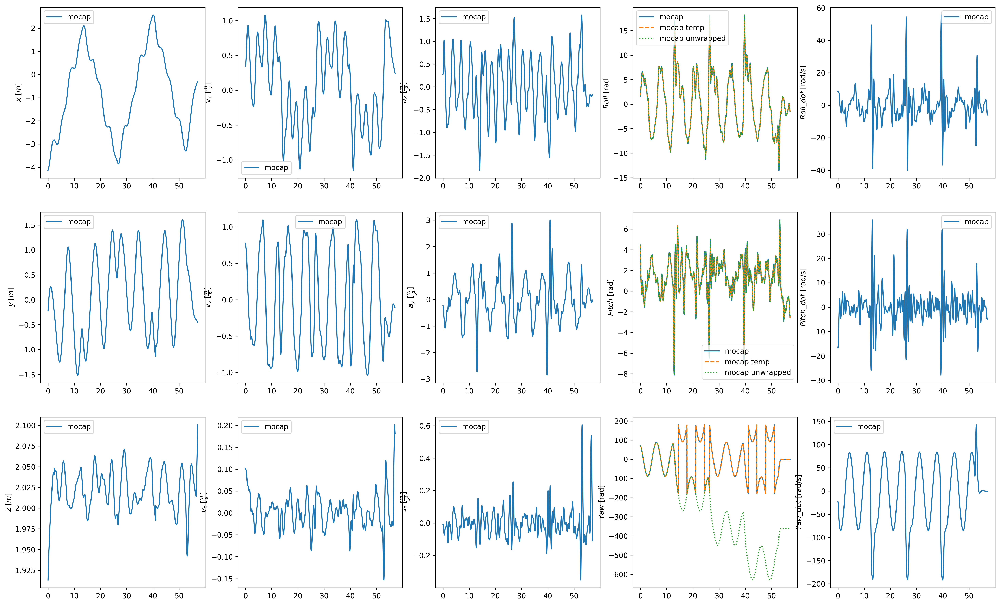

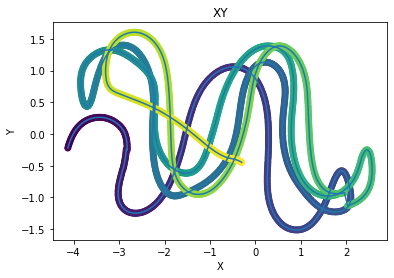

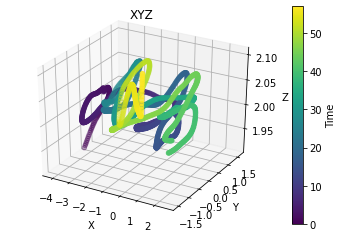

In [348]:
# plot the mocap data 
fig, ax = plt.subplots(3, 5, figsize=(3 * 8, 3 * 5), dpi=300)
# plot x
ax[0, 0].plot(mocap_time_shifted, mocap_X, label='mocap')
ax[0, 0].set_ylabel('$x$ [$m$]')
ax[0, 0].legend()
# plot y
ax[1, 0].plot(mocap_time_shifted, mocap_Y, label='mocap')
ax[1, 0].set_ylabel('$y$ [$m$]')
ax[1, 0].legend()
# plot z
ax[2, 0].plot(mocap_time_shifted, mocap_Z, label='mocap')
ax[2, 0].set_ylabel('$z$ [$m$]')
ax[2, 0].legend()
# plot x_dot
ax[0, 1].plot(mocap_time_shifted, mocap_X_dot, label='mocap')
ax[0, 1].set_ylabel(r'$v_x$ [$\frac{m}{s}$]')
ax[0, 1].legend()
# plot y_dot
ax[1, 1].plot(mocap_time_shifted, mocap_Y_dot, label='mocap')
ax[1, 1].set_ylabel(r'$v_y$ [$\frac{m}{s}$]')
ax[1, 1].legend()
# plot z_dot
ax[2, 1].plot(mocap_time_shifted, mocap_Z_dot, label='mocap')
ax[2, 1].set_ylabel(r'$v_z$ [$\frac{m}{s}$]')
ax[2, 1].legend()
# plot x_ddot
ax[0, 2].plot(mocap_time_shifted, mocap_X_ddot, label='mocap')
ax[0, 2].set_ylabel(r'$a_x$ [$\frac{m}{s^2}$]')
ax[0, 2].legend()
# plot y_ddot
ax[1, 2].plot(mocap_time_shifted, mocap_Y_ddot, label='mocap')
ax[1, 2].set_ylabel(r'$a_y$ [$\frac{m}{s^2}$]')
ax[1, 2].legend()
# plot z_ddot
ax[2, 2].plot(mocap_time_shifted, mocap_Z_ddot, label='mocap')
ax[2, 2].set_ylabel(r'$a_z$ [$\frac{m}{s^2}$]')
ax[2, 2].legend()
# plot Roll
ax[0, 3].plot(mocap_time_shifted, mocap_Roll, label='mocap')
ax[0, 3].plot(mocap_time_shifted, mocap_Roll_temp, label='mocap temp', linestyle='--')
ax[0, 3].plot(mocap_time_shifted, mocap_Roll_unwrapped, label='mocap unwrapped', linestyle=':')
ax[0, 3].set_ylabel('$Roll$ [rad]')
ax[0, 3].legend()
# plot Pitch
ax[1, 3].plot(mocap_time_shifted, mocap_Pitch, label='mocap')
ax[1, 3].plot(mocap_time_shifted, mocap_Pitch_temp, label='mocap temp', linestyle='--')
ax[1, 3].plot(mocap_time_shifted, mocap_Pitch_unwrapped, label='mocap unwrapped', linestyle=':')
ax[1, 3].set_ylabel('$Pitch$ [rad]')
ax[1, 3].legend()
# plot Yaw
ax[2, 3].plot(mocap_time_shifted, mocap_Yaw, label='mocap')
ax[2, 3].plot(mocap_time_shifted, mocap_Yaw_temp, label='mocap temp', linestyle='--')
ax[2, 3].plot(mocap_time_shifted, mocap_Yaw_unwrapped, label='mocap unwrapped', linestyle=':')
ax[2, 3].set_ylabel('$Yaw$ [rad]')
# ax[2, 3].legend()
# plot Roll_dot
ax[0, 4].plot(mocap_time_shifted, mocap_Roll_dot, label='mocap')
ax[0, 4].set_ylabel(r'$Roll\_dot$ [rad/s]')
ax[0, 4].legend()
# plot Pitch_dot
ax[1, 4].plot(mocap_time_shifted, mocap_Pitch_dot, label='mocap')
ax[1, 4].set_ylabel(r'$Pitch\_dot$ [rad/s]')
ax[1, 4].legend()
# plot Yaw_dot
ax[2, 4].plot(mocap_time_shifted, mocap_Yaw_dot, label='mocap')
ax[2, 4].set_ylabel(r'$Yaw\_dot$ [rad/s]')
ax[2, 4].legend()
plt.show()

# x,y plot of the mocap data
plt.plot(mocap_X, mocap_Y)
plt.scatter(mocap_X, mocap_Y, label='start', c=mocap_time_shifted)
plt.xlabel('X')
plt.ylabel('Y')
plt.title('XY')
plt.show()



# make 3d plot of XYZ with time as color
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(mocap_X, mocap_Y, mocap_Z, c=mocap_time_shifted)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.title('XYZ')
plt.colorbar(sc, label='Time')
plt.show()

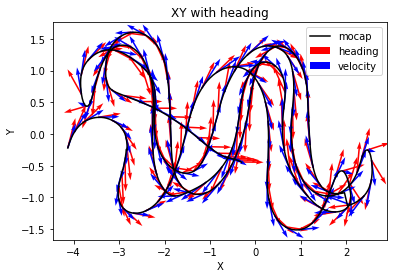

In [349]:
# plot X y data and add heading a s a quiver plot
fig, ax = plt.subplots()
ax.plot(mocap_X, mocap_Y,color='black', label='mocap')
# use mocap_yaw to get the heading
u = np.cos(np.radians(1*np.array(mocap_Yaw)))
v = np.sin(np.radians(1*np.array(mocap_Yaw)))
# plot every 10th point
ax.quiver(mocap_X[::10], mocap_Y[::10], u[::10], v[::10], angles='xy', scale_units='xy', scale=2, color='r', label='heading')
# add quiver based on velocity
Vu = mocap_X_dot
Vv = mocap_Y_dot
# plot every 10th point
ax.quiver(mocap_X[::10], mocap_Y[::10], Vu[::10], Vv[::10], angles='xy', scale_units='xy', scale=2, color='b', label='velocity')
ax.set_xlabel('X')
ax.set_ylabel('Y')
# add legend
ax.legend()
ax.set_title('XY with heading')
plt.show()

Text(0, 0.5, 'Y')

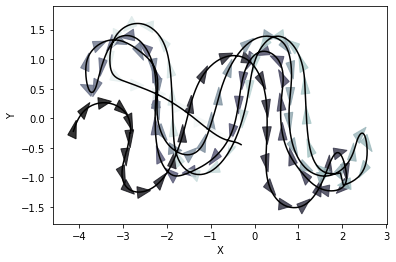

In [350]:
# make the heading arrows that point in the direction of yaw

# # overlay triangles with color by time
#         tri = np.array([[.1,0],[-.05,-.05],[-.05,.05]]) * scale
#         for i in range(0, len(tsim), marker_step):
#             R = np.array([[np.cos(psi[i]), -np.sin(psi[i])],
#                         [np.sin(psi[i]),  np.cos(psi[i])]])
#             tri_r = tri @ R.T
#             color = cmap(norm(tsim[i]))
#             plt.fill(x[i]+tri_r[:,0],
#                     y[i]+tri_r[:,1],
#                     color=color, alpha=0.8, edgecolor=None)


fig, ax = plt.subplots()
ax.plot(mocap_X, mocap_Y, color='black', label='mocap')
# use mocap_yaw to get the heading
tri = np.array([[.1, 0], [-.05, -0.05], [-.05, 0.05]]) * 2
marker_step = 15
cmap = plt.get_cmap('bone')
norm = mpl.colors.Normalize(vmin=mocap_time_shifted.min(), vmax=mocap_time_shifted.max())
for i in range(0, len(mocap_time_shifted), marker_step):
    R = np.array([[np.cos(np.radians(mocap_Yaw[i])), -np.sin(np.radians(mocap_Yaw[i]))],
                  [np.sin(np.radians(mocap_Yaw[i])),  np.cos(np.radians(mocap_Yaw[i]))]])
    tri_r = tri @ R.T
    color = cmap(norm(mocap_time_shifted[i]))
    ax.fill(mocap_X[i] + tri_r[:, 0], mocap_Y[i] + tri_r[:, 1], color=color, alpha=0.8, edgecolor=None)
# ax.scatter(mocap_X[::marker_step], mocap_Y[::marker_step], c=mocap_time_shifted[::marker_step], cmap='viridis', label='time')
ax.set_xlabel('X')
ax.set_ylabel('Y')
# ax.set_title('XY with heading arrows')

1.665290639471579 4.455828935898579 70.40214516577598
velocity_body_dt: 29.999650786300368


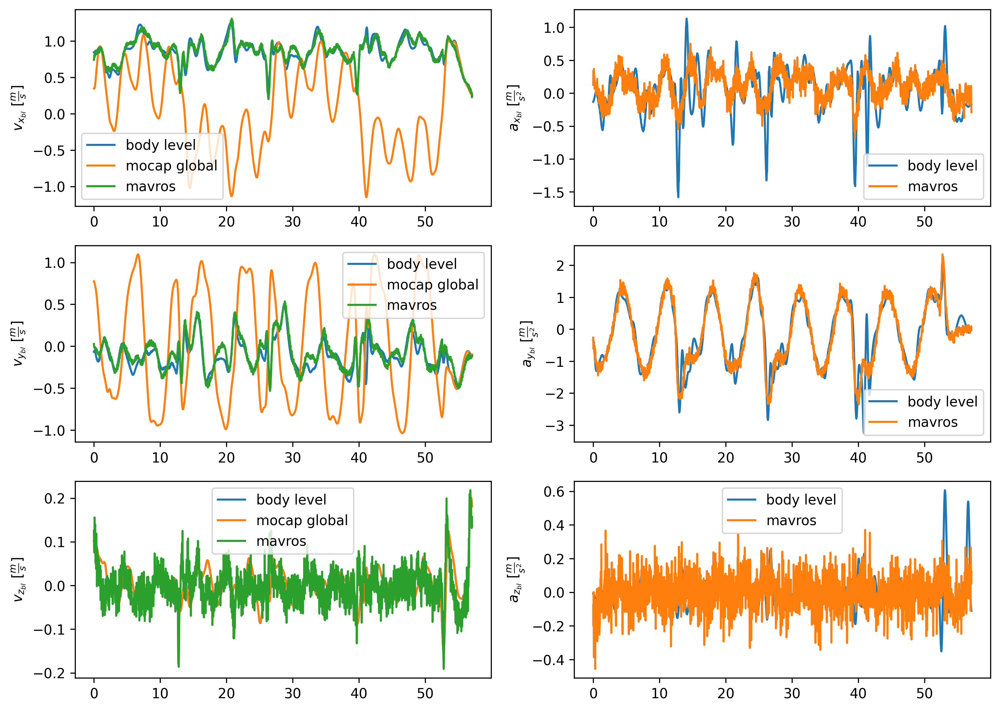

In [351]:
# R_G_BL (rotation from global to body level ) function that takes in roll, pitch, yaw and gives out the rotation matrix

def R_G_BL(roll, pitch, yaw):
    """
    Compute the rotation matrix from global frame to body-level frame.
    This only applies a yaw rotation (inverse of R_z) to align with the body-level frame.

    Args:
    roll  (float): Roll angle (phi) in radians.
    pitch (float): Pitch angle (theta) in radians.
    yaw   (float): Yaw angle (psi) in radians.

    Returns:
    numpy.ndarray: 3x3 rotation matrix from global to body-level frame.
    """
    R_z = np.array([[ np.cos(yaw), np.sin(yaw), 0],
                    [-np.sin(yaw), np.cos(yaw), 0],
                    [ 0, 0, 1]])

    return R_z  # This is R_z(-yaw), rotating global to body-level

    return R_G_BL
print(mocap_Roll[0], mocap_Pitch[0], mocap_Yaw[0])
# Rotate the velocity and acceleration from global to body level
mocap_bl_X_dot = []
mocap_bl_Y_dot = []
mocap_bl_Z_dot = []
mocap_bl_X_ddot = []
mocap_bl_Y_ddot = []
mocap_bl_Z_ddot = []

for i in range(len(mocap_Roll)):
    R_G_BL_i = R_G_BL(np.deg2rad(mocap_Roll[i]), np.deg2rad(mocap_Pitch[i]), np.deg2rad(mocap_Yaw[i]))
    
    # Velocity transformation
    velocity_vector = np.array([mocap_X_dot[i], mocap_Y_dot[i], mocap_Z_dot[i]])
    transformed_velocity = R_G_BL_i @ velocity_vector  # This returns a 3-element vector

    mocap_bl_X_dot.append(transformed_velocity[0])
    mocap_bl_Y_dot.append(transformed_velocity[1])
    mocap_bl_Z_dot.append(transformed_velocity[2])

    # Acceleration transformation
    acceleration_vector = np.array([mocap_X_ddot[i], mocap_Y_ddot[i], mocap_Z_ddot[i]])
    transformed_acceleration = R_G_BL_i @ acceleration_vector  # This returns a 3-element vector

    mocap_bl_X_ddot.append(transformed_acceleration[0])
    mocap_bl_Y_ddot.append(transformed_acceleration[1])
    mocap_bl_Z_ddot.append(transformed_acceleration[2])


data['mavros/local_position/velocity_body']
velocity_body_time = data['mavros/local_position/velocity_body']['rosbagTimestamp']/1e9/2
velocity_body_dt = np.mean(np.diff(velocity_body_time))
print('velocity_body_dt:', 1/velocity_body_dt)
# plt.plot(velocity_body_time, data['mavros/local_position/velocity_body']['x'], label='x')
velocity_body_x = data['mavros/local_position/velocity_body']['x']
velocity_body_y = data['mavros/local_position/velocity_body']['y']
velocity_body_z = data['mavros/local_position/velocity_body']['z']
velocity_body_x = interpolate_data(velocity_body_time, data['mavros/local_position/velocity_body']['x'], mocap_time)
velocity_body_y = interpolate_data(velocity_body_time, data['mavros/local_position/velocity_body']['y'], mocap_time)
velocity_body_z = interpolate_data(velocity_body_time, data['mavros/local_position/velocity_body']['z'], mocap_time)

smooth_params = [10, 0.025]
velocity_body_x_hat, accleration_body_x = pynumdiff.smooth_finite_difference.butterdiff(velocity_body_x, velocity_body_dt, smooth_params, options={'iterate': False})
velocity_body_y_hat, accleration_body_y = pynumdiff.smooth_finite_difference.butterdiff(velocity_body_y, velocity_body_dt, smooth_params, options={'iterate': False})
velocity_body_z_hat, accleration_body_z = pynumdiff.smooth_finite_difference.butterdiff(velocity_body_z, velocity_body_dt, smooth_params, options={'iterate': False})

acceleration_noise = 0.1

accleration_body_x = accleration_body_x - velocity_body_y_hat*np.deg2rad(mocap_Yaw_dot) + np.random.normal(0, acceleration_noise, len(accleration_body_x))
accleration_body_y = accleration_body_y + velocity_body_x_hat*np.deg2rad(mocap_Yaw_dot) + np.random.normal(0, acceleration_noise, len(accleration_body_y))
accleration_body_z = accleration_body_z + np.random.normal(0, acceleration_noise, len(accleration_body_z))

# plt.plot(velocity_body_time, vision_pose_velocity_x, label='mavros velocity x')
# plot the body level velocities and accelerations
fig, ax = plt.subplots(3, 2, figsize=(3 * 4, 3 * 3), dpi=300)
# plot x_dot
ax[0, 0].plot(mocap_time_shifted, mocap_bl_X_dot, label='body level')
ax[0, 0].plot(mocap_time_shifted, mocap_X_dot, label='mocap global')
ax[0, 0].plot(mocap_time_shifted, velocity_body_x, label='mavros')
ax[0, 0].set_ylabel(r'$v_{x_{bl}}$ [$\frac{m}{s}$]')
ax[0, 0].legend()
# plot y_dot
ax[1, 0].plot(mocap_time_shifted, mocap_bl_Y_dot, label='body level')
ax[1, 0].plot(mocap_time_shifted, mocap_Y_dot, label='mocap global')
ax[1, 0].plot(mocap_time_shifted, velocity_body_y, label='mavros')
ax[1, 0].set_ylabel(r'$v_{y_{bl}}$ [$\frac{m}{s}$]')
ax[1, 0].legend()
# plot z_dot
ax[2, 0].plot(mocap_time_shifted, mocap_bl_Z_dot, label='body level')
ax[2, 0].plot(mocap_time_shifted, mocap_Z_dot, label='mocap global')
ax[2, 0].plot(mocap_time_shifted, velocity_body_z, label='mavros')
ax[2, 0].set_ylabel(r'$v_{z_{bl}}$ [$\frac{m}{s}$]')
ax[2, 0].legend()
# plot x_ddot
ax[0, 1].plot(mocap_time_shifted, mocap_bl_X_ddot, label='body level')
# ax[0, 1].plot(mocap_time_shifted, mocap_X_ddot, label='mocap global')
ax[0, 1].plot(mocap_time_shifted, accleration_body_x, label='mavros')
ax[0, 1].set_ylabel(r'$a_{x_{bl}}$ [$\frac{m}{s^2}$]')
ax[0, 1].legend()
# plot y_ddot
ax[1, 1].plot(mocap_time_shifted, mocap_bl_Y_ddot, label='body level')
# ax[1, 1].plot(mocap_time_shifted, mocap_Y_ddot, label='mocap global')
ax[1, 1].plot(mocap_time_shifted, accleration_body_y, label='mavros')
ax[1, 1].set_ylabel(r'$a_{y_{bl}}$ [$\frac{m}{s^2}$]')
ax[1, 1].legend()
# plot z_ddot
ax[2, 1].plot(mocap_time_shifted, mocap_bl_Z_ddot, label='body level')
# ax[2, 1].plot(mocap_time_shifted, mocap_Z_ddot, label='mocap global')
ax[2, 1].plot(mocap_time_shifted, accleration_body_z, label='mavros')
ax[2, 1].set_ylabel(r'$a_{z_{bl}}$ [$\frac{m}{s^2}$]')
ax[2, 1].legend()
plt.show()


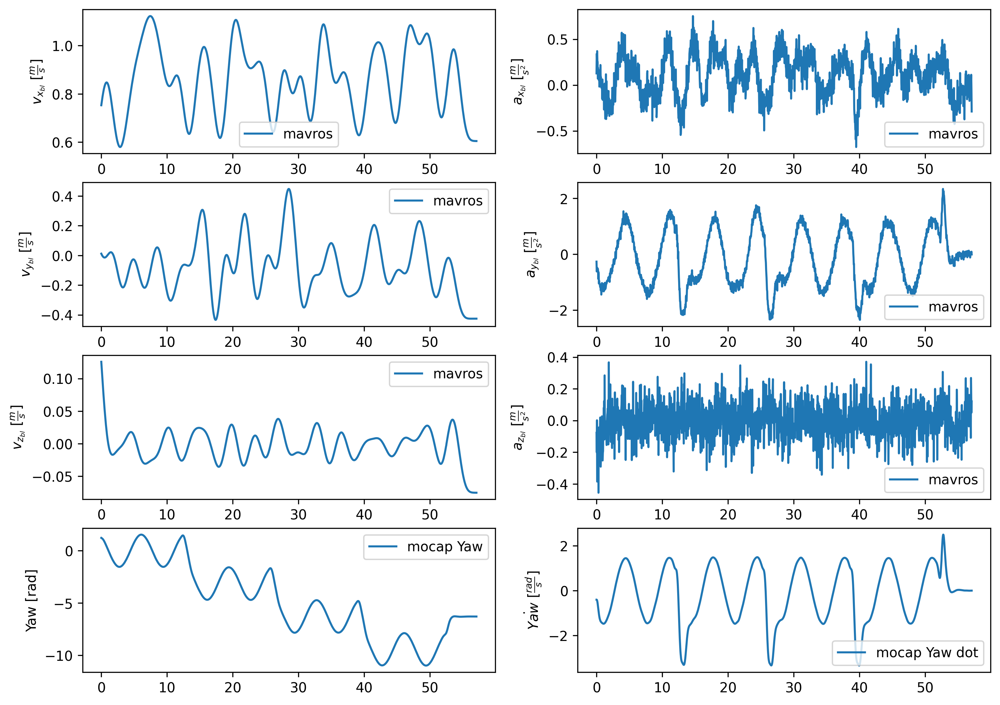

In [352]:
fig, ax = plt.subplots(4, 2, figsize=(3 * 4, 3 * 3), dpi=300)
# plot x_dot

ax[0, 0].plot(mocap_time_shifted, velocity_body_x_hat, label='mavros')
ax[0, 0].set_ylabel(r'$v_{x_{bl}}$ [$\frac{m}{s}$]')
ax[0, 0].legend()
# plot y_dot
ax[1, 0].plot(mocap_time_shifted, velocity_body_y_hat, label='mavros')
ax[1, 0].set_ylabel(r'$v_{y_{bl}}$ [$\frac{m}{s}$]')
ax[1, 0].legend()
# plot z_dot
ax[2, 0].plot(mocap_time_shifted, velocity_body_z_hat, label='mavros')
ax[2, 0].set_ylabel(r'$v_{z_{bl}}$ [$\frac{m}{s}$]')
ax[2, 0].legend()
# plot x_ddot
# ax[0, 1].plot(mocap_time_shifted, mocap_bl_X_ddot, label='body level')
# ax[0, 1].plot(mocap_time_shifted, mocap_X_ddot, label='mocap global')
ax[0, 1].plot(mocap_time_shifted, accleration_body_x, label='mavros')
ax[0, 1].set_ylabel(r'$a_{x_{bl}}$ [$\frac{m}{s^2}$]')
ax[0, 1].legend()
# plot y_ddot
# ax[1, 1].plot(mocap_time_shifted, mocap_bl_Y_ddot, label='body level')
# ax[1, 1].plot(mocap_time_shifted, mocap_Y_ddot, label='mocap global')
ax[1, 1].plot(mocap_time_shifted, accleration_body_y, label='mavros')
ax[1, 1].set_ylabel(r'$a_{y_{bl}}$ [$\frac{m}{s^2}$]')
ax[1, 1].legend()
# plot z_ddot
# ax[2, 1].plot(mocap_time_shifted, mocap_bl_Z_ddot, label='body level')
# ax[2, 1].plot(mocap_time_shifted, mocap_Z_ddot, label='mocap global')
ax[2, 1].plot(mocap_time_shifted, accleration_body_z, label='mavros')
ax[2, 1].set_ylabel(r'$a_{z_{bl}}$ [$\frac{m}{s^2}$]')
ax[2, 1].legend()
ax[3, 0].plot(mocap_time_shifted,np.deg2rad(mocap_Yaw_hat), label='mocap Yaw')
ax[3, 0].set_ylabel(r'Yaw [rad]')
ax[3, 0].legend()
ax[3, 1].plot(mocap_time_shifted, np.deg2rad(mocap_Yaw_dot), label='mocap Yaw dot')
ax[3, 1].set_ylabel(r'$\dot{Yaw}$ [$\frac{rad}{s}$]')
ax[3, 1].legend()
plt.show()

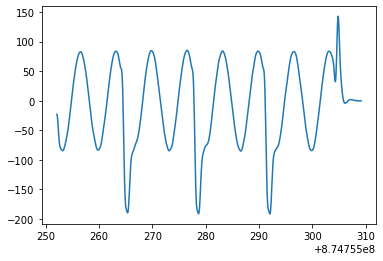

In [353]:
plt.plot(mocap_time,mocap_Yaw_dot)

velocity_body_dt: 29.999650786300368


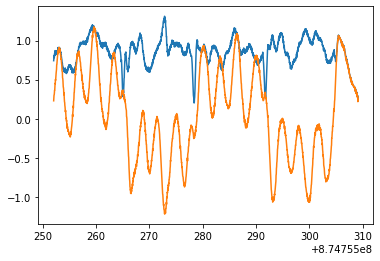

In [354]:
data['mavros/local_position/velocity_body']
velocity_body_time = data['mavros/local_position/velocity_body']['rosbagTimestamp']/1e9/2
velocity_body_dt = np.mean(np.diff(velocity_body_time))
print('velocity_body_dt:', 1/velocity_body_dt)
plt.plot(velocity_body_time, data['mavros/local_position/velocity_body']['x'], label='x')
plt.plot(velocity_body_time, data['mavros/local_position/velocity_local']['x'], label='x')

# IMU [Roll($\phi$),Pitch($\theta$),Yaw($\psi$)] + [$\omega_x$,$\omega_y$,$\omega_z$] + [$A_x$,$A_y$,$A_z$]

imu_time_dt: 0.01910710334777832


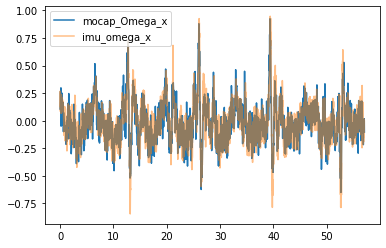

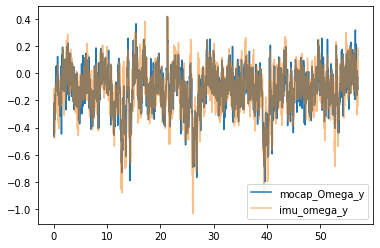

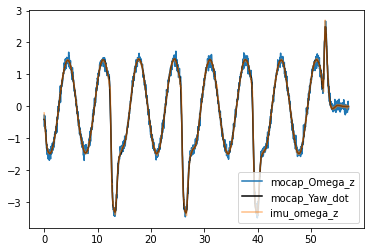

In [355]:
imu_time = data['mavros/imu/data']['rosbagTimestamp']/1e9/2
imu_time_shifted = imu_time - imu_time[0]
imu_time_dt = imu_time[1] - imu_time[0]
print('imu_time_dt:', imu_time_dt)
imu_Roll, imu_Pitch, imu_Yaw = [], [], []
for i in range(len(data['mavros/imu/data'])):
    R, P, Y = quaternion_to_euler(data['mavros/imu/data']['x'][i],
                                  data['mavros/imu/data']['y'][i],
                                  data['mavros/imu/data']['z'][i],
                                  data['mavros/imu/data']['w'][i])
    imu_Roll.append(np.radians(R))
    imu_Pitch.append(np.radians(P))
    imu_Yaw.append(np.radians(Y))

imu_omega_x = data['mavros/imu/data']['x.1']
imu_omega_y = data['mavros/imu/data']['y.1']
imu_omega_z = data['mavros/imu/data']['z.1']

# function that goes from omega_dot to phi_dot, theta_dot, psi_dot

def omega_to_euler_dot(omega_x, omega_y, omega_z, phi, theta, psi):
    """
    Converts angular velocity components (omega_x, omega_y, omega_z)
    to Euler angle rates (phi_dot, theta_dot, psi_dot).

    input: omega_x, omega_y, omega_z, phi, theta
    output: phi_dot, theta_dot, psi_dot
    """
    phi_dot = omega_x + omega_y * np.tan(theta) * np.sin(phi) + omega_z * np.tan(theta) * np.cos(phi)
    theta_dot = omega_y * np.cos(phi) - omega_z * np.sin(phi)
    psi_dot = omega_y * np.sin(phi) / np.cos(theta) + omega_z * np.cos(phi) / np.cos(theta)

    return phi_dot, theta_dot, psi_dot

def euler_dot_to_omega(phi_dot, theta_dot, psi_dot, phi, theta, psi):
    """
    Converts Euler angle rates (phi_dot, theta_dot, psi_dot)
    to angular velocity components (omega_x, omega_y, omega_z).

    input: phi_dot, theta_dot, psi_dot, phi, theta
    output: omega_x, omega_y, omega_z
    """
    omega_x = phi_dot - psi_dot * np.sin(theta)
    omega_y = theta_dot * np.cos(phi) + psi_dot * np.cos(theta) * np.sin(phi)
    omega_z = -theta_dot * np.sin(phi) + psi_dot * np.cos(theta) * np.cos(phi)

    return omega_x, omega_y, omega_z

imu_phi_dot, imu_theta_dot, imu_psi_dot = [], [], []
for i in range(len(data['mavros/imu/data'])):
    phi_dot, theta_dot, psi_dot = omega_to_euler_dot(imu_omega_x[i],
                                                         imu_omega_y[i],
                                                         imu_omega_z[i],
                                                         imu_Roll[i],
                                                         imu_Pitch[i],
                                                         imu_Yaw[i])
    imu_phi_dot.append(phi_dot)
    imu_theta_dot.append(theta_dot)
    imu_psi_dot.append(psi_dot)
# using mocap data get Omega_x, Omega_y, Omega_z
mocap_Omega_x, mocap_Omega_y, mocap_Omega_z = [], [], []
for i in range(len(data['mavros/local_position/pose'])):
    omega_x, omega_y, omega_z = euler_dot_to_omega( np.deg2rad(mocap_Roll_dot[i]),
                                                    np.deg2rad(mocap_Pitch_dot[i]),
                                                    np.deg2rad(mocap_Yaw_dot[i]),
                                                    np.deg2rad(mocap_Roll[i]),
                                                    np.deg2rad(mocap_Pitch[i]),
                                                    np.deg2rad(mocap_Yaw[i]))
    mocap_Omega_x.append(omega_x)
    mocap_Omega_y.append(omega_y)
    mocap_Omega_z.append(omega_z)

# # use pynumdif to smooth the mocap Omega data
# # smooth_params = [10, 0.09]
# mocap_Omega_x, mocap_Omega_x_dot = pynumdiff.smooth_finite_difference.butterdiff(mocap_Omega_x, mocap_dt, smooth_params, options={'iterate': False})
# mocap_Omega_y, mocap_Omega_y_dot = pynumdiff.smooth_finite_difference.butterdiff(mocap_Omega_y, mocap_dt, smooth_params, options={'iterate': False})
# mocap_Omega_z, mocap_Omega_z_dot = pynumdiff.smooth_finite_difference.butterdiff(mocap_Omega_z, mocap_dt, smooth_params, options={'iterate': False})
mocap_omega_noise = 0.1
mocap_Omega_x = mocap_Omega_x + np.random.normal(0, mocap_omega_noise, len(mocap_Omega_x))
mocap_Omega_y = mocap_Omega_y + np.random.normal(0, mocap_omega_noise, len(mocap_Omega_y))
mocap_Omega_z = mocap_Omega_z + np.random.normal(0, mocap_omega_noise, len(mocap_Omega_z))


# # mocap_Omega_x = remove_outliers(mocap_Omega_x, method='iqr', threshold=1.5)
# # mocap_Omega_y = remove_outliers(mocap_Omega_y, method='iqr', threshold=1.5)
# # mocap_Omega_z = remove_outliers(mocap_Omega_z, method='iqr', threshold=1.5)                                                   

# # function that goes from phi_dot, theta_dot, psi_dot to omega_x, omega_y, omega_z
# def euler_dot_to_omega_dot(phi_dot, theta_dot, psi_dot, phi, theta):
#     """
#     input: phi_dot, theta_dot, psi_dot, phi, theta
#     output: omega_x, omega_y, omega_z
#     """
#     omega_x = phi_dot - psi_dot * np.sin(theta)
#     omega_y = theta_dot * np.cos(phi) + psi_dot * np.cos(theta) * np.sin(phi)
#     omega_z = psi_dot * np.cos(theta) * np.cos(phi) - theta_dot * np.sin(phi)
#     return omega_x, omega_y, omega_z

# # take the gradient of imu_roll, imu_pitch, imu_yaw to get the angular velocities
# # imu_Roll_dot = np.gradient(imu_Roll, imu_time)
# # imu_Pitch_dot = np.gradient(imu_Pitch, imu_time)
# # imu_Yaw_dot = np.gradient(imu_Yaw, imu_time)

# # smooth_params = [10, 0.09]
# # imu_Roll_hat, imu_Roll_dot = pynumdiff.smooth_finite_difference.butterdiff(imu_Roll, np.mean(np.diff(imu_time)), smooth_params, options={'iterate': False})
# # imu_Pitch_hat, imu_Pitch_dot = pynumdiff.smooth_finite_difference.butterdiff(imu_Pitch, np.mean(np.diff(imu_time)), smooth_params, options={'iterate': False})
# # imu_Yaw_hat, imu_Yaw_dot = pynumdiff.smooth_finite_difference.butterdiff(imu_Yaw, np.mean(np.diff(imu_time)), smooth_params, options={'iterate': False})


# # # smooth_params = [10, 0.09]
# # mocap_Roll_hat, mocap_Roll_dot = pynumdiff.smooth_finite_difference.butterdiff(np.deg2rad(mocap_Roll), mocap_dt, smooth_params, options={'iterate': False})
# # mocap_Pitch_hat, mocap_Pitch_dot = pynumdiff.smooth_finite_difference.butterdiff(np.deg2rad(mocap_Pitch), mocap_dt, smooth_params, options={'iterate': False})
# # mocap_Yaw_hat, mocap_Yaw_dot = pynumdiff.smooth_finite_difference.butterdiff(np.deg2rad(mocap_Yaw), mocap_dt, smooth_params, options={'iterate': False})

# # mocap_Roll_dot=remove_outliers(np.gradient(np.deg2rad(mocap_Roll), mocap_time), method='iqr', threshold=1.5)
# # mocap_Pitch_dot=remove_outliers(np.gradient(np.deg2rad(mocap_Pitch), mocap_time), method='iqr', threshold=1.5)
# # mocap_Yaw_dot=remove_outliers(np.gradient(np.deg2rad(mocap_Yaw), mocap_time), method='iqr', threshold=1.5)

# print('imu dt:', 1/np.mean(np.diff(imu_time)))
# print('mocap dt:', 1/np.mean(np.diff(mocap_time)))
# # interpolate IMU to mocap time
# # imu_omega_x = interpolate_data(imu_time, imu_omega_x, mocap_time)
# # imu_omega_y = interpolate_data(imu_time, imu_omega_y, mocap_time)
# # imu_omega_z = interpolate_data(imu_time, imu_omega_z, mocap_time)


plt.plot(mocap_time_shifted, mocap_Omega_x, label='mocap_Omega_x')
# plt.plot(mocap_time_shifted, mocap_Roll_dot, label='mocap_Roll_dot')
plt.plot(imu_time_shifted, imu_omega_x, label='imu_omega_x',alpha=.5)
# plt.title('mocap Omega_x and mocap roll_dot and imu omega_x')
# plt.ylim(-1,1)
plt.legend()
plt.show()


plt.plot(mocap_time_shifted, mocap_Omega_y, label='mocap_Omega_y')
# plt.plot(mocap_time_shifted, mocap_Pitch_dot, label='mocap_Pitch_dot')
plt.plot(imu_time_shifted, imu_omega_y, label='imu_omega_y',alpha=.5)
# plt.title('mocap Omega_y and mocap pitch_dot and imu omega_y')
# plt.ylim(-1,1)
plt.legend()
plt.show()

plt.plot(mocap_time_shifted, mocap_Omega_z, label='mocap_Omega_z')
plt.plot(mocap_time_shifted, np.radians(mocap_Yaw_dot), label='mocap_Yaw_dot',color='black')
plt.plot(imu_time_shifted, imu_omega_z, label='imu_omega_z',alpha=.5)
# plt.title('mocap Omega_z and mocap yaw_dot and imu omega_z')
# plt.ylim(-1,1)
plt.legend()
plt.show()

# # plot mocap yae and imu yaw
# plt.plot(mocap_time_shifted, mocap_Yaw, label='mocap_Yaw')
# plt.plot(imu_time_shifted, np.rad2deg(imu_Yaw), label='imu_Yaw',alpha=.5)
# plt.title('mocap Yaw and imu Yaw')
# plt.xlabel('Time [s]')
# plt.ylabel('Yaw [rad]')
# plt.legend()
# plt.show()

In [356]:
data['mavros/local_position/pose']

,rosbagTimestamp,header,seq,stamp,secs,nsecs,frame_id,pose,position,x,y,z,orientation,x.1,y.1,z.1,w
0,1749510504186566391,NaN,85025,NaN,1748040119,93810688,"""map""",NaN,NaN,-4.128503,-0.220388,1.913257,NaN,0.010541,-0.040133,-0.575489,-0.816756
1,1749510504254510253,NaN,85026,NaN,1748040119,135810688,"""map""",NaN,NaN,-4.115859,-0.189741,1.917064,NaN,0.007845,-0.038860,-0.573557,-0.818206
2,1749510504322080610,NaN,85027,NaN,1748040119,167813760,"""map""",NaN,NaN,-4.105484,-0.166413,1.919884,NaN,0.000636,-0.036567,-0.567896,-0.822287
3,1749510504384390738,NaN,85028,NaN,1748040119,199813760,"""map""",NaN,NaN,-4.094476,-0.142901,1.923003,NaN,-0.005757,-0.034049,-0.561126,-0.827010
4,1749510504452291057,NaN,85029,NaN,1748040119,231813760,"""map""",NaN,NaN,-4.082700,-0.119411,1.926232,NaN,-0.009398,-0.032264,-0.556500,-0.830168
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1708,1749510618054739092,NaN,86733,NaN,1748040176,34697152,"""map""",NaN,NaN,-0.334163,-0.433465,2.080544,NaN,-0.006454,-0.017172,-0.005352,0.999817
1709,1749510618117019573,NaN,86734,NaN,1748040176,65699712,"""map""",NaN,NaN,-0.326420,-0.436658,2.085806,NaN,-0.008443,-0.018791,-0.005514,0.999773
1710,1749510618185271830,NaN,86735,NaN,1748040176,98699712,"""map""",NaN,NaN,-0.319107,-0.439807,2.090954,NaN,-0.010096,-0.020372,-0.005720,0.999725
1711,1749510618257557776,NaN,86736,NaN,1748040176,129699712,"""map""",NaN,NaN,-0.312202,-0.442929,2.095948,NaN,-0.011861,-0.020289,-0.005834,0.999707


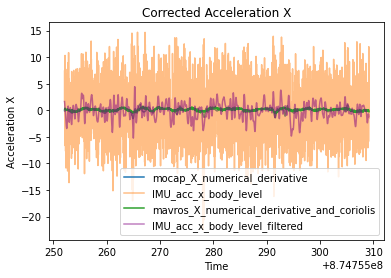

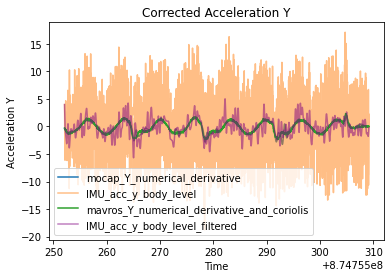

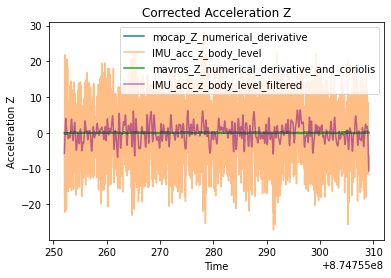

In [357]:
g = 9.81  # Gravitational acceleration (m/s^2)

# Function to compute the rotation matrix from roll, pitch, yaw
def rotation_matrix_from_euler(roll, pitch, yaw):
    """
    Creates a rotation matrix from roll, pitch, yaw angles (in radians).
    """
    # Compute rotation matrices for roll, pitch, and yaw
    R_roll = np.array([
        [1, 0, 0],
        [0, np.cos(roll), -np.sin(roll)],
        [0, np.sin(roll), np.cos(roll)]
    ])
    
    R_pitch = np.array([
        [np.cos(pitch), 0, np.sin(pitch)],
        [0, 1, 0],
        [-np.sin(pitch), 0, np.cos(pitch)]
    ])
    
    R_yaw = np.array([
        [np.cos(yaw), -np.sin(yaw), 0],
        [np.sin(yaw), np.cos(yaw), 0],
        [0, 0, 1]
    ])
    
    # Combine the rotation matrices (Z * Y * X)
    R = R_yaw @ R_pitch @ R_roll
    return R

# Function to remove gravity from linear acceleration
def remove_gravity_from_acceleration(acc_x, acc_y, acc_z, roll, pitch, yaw):
    """
    Removes the gravity component from the linear acceleration in the body frame.
    
    acc_x, acc_y, acc_z: numpy arrays
        Arrays of linear acceleration in the body frame along the x, y, and z axes.
    roll, pitch, yaw: numpy arrays
        Arrays of roll, pitch, and yaw angles (in radians).
    
    Returns:
    acc_x_corrected, acc_y_corrected, acc_z_corrected: numpy arrays
        Corrected linear accelerations with gravity removed along the x, y, and z axes.
    """
    # Initialize corrected acceleration arrays
    acc_x_corrected = np.zeros_like(acc_x)
    acc_y_corrected = np.zeros_like(acc_y)
    acc_z_corrected = np.zeros_like(acc_z)
    
    # Gravity vector in the world frame (assume gravity points along the Z-axis)
    gravity_world = np.array([0, 0, g])
    
    # Loop over each time step and correct the acceleration
    for i in range(len(acc_x)):
        # Get the rotation matrix for the current orientation (roll, pitch, yaw)
        R = rotation_matrix_from_euler(roll[i], pitch[i], yaw[i])
        
        # Transform gravity vector from world frame to body frame
        gravity_body = R.T @ gravity_world  # Transpose R to rotate from world to body
        
        # Measured acceleration in body frame
        acc_body = np.array([acc_x[i], acc_y[i], acc_z[i]])
        
        # Subtract gravity from the body-frame acceleration
        acc_corrected = acc_body - gravity_body
        
        # Store the corrected acceleration
        acc_x_corrected[i] = acc_corrected[0]
        acc_y_corrected[i] = acc_corrected[1]
        acc_z_corrected[i] = acc_corrected[2]
    
    return acc_x_corrected, acc_y_corrected, acc_z_corrected

# Remove gravity from the linear acceleration
imu_acc_x_corrected, imu_acc_y_corrected, imu_acc_z_corrected = remove_gravity_from_acceleration(
    data['mavros/imu/data']['x.2'],
    data['mavros/imu/data']['y.2'],
    data['mavros/imu/data']['z.2'],
    imu_Roll, imu_Pitch, imu_Yaw
)

# rotate the acceleration data to the world frame
def rotate_acceleration_to_world_frame(acc_x, acc_y, acc_z, roll, pitch, yaw):
    """
    Rotates the linear acceleration from the body frame to the world frame.
    
    acc_x, acc_y, acc_z: numpy arrays
        Arrays of linear acceleration in the body frame along the x, y, and z axes.
    roll, pitch, yaw: numpy arrays
        Arrays of roll, pitch, and yaw angles (in radians).
    
    Returns:
    acc_x_world, acc_y_world, acc_z_world: numpy arrays
        Linear acceleration in the world frame along the x, y, and z axes.
    """
    # Initialize world-frame acceleration arrays
    acc_x_world = np.zeros_like(acc_x)
    acc_y_world = np.zeros_like(acc_y)
    acc_z_world = np.zeros_like(acc_z)
    
    # Loop over each time step and rotate the acceleration
    for i in range(len(acc_x)):
        # Get the rotation matrix for the current orientation (roll, pitch, yaw)
        R = rotation_matrix_from_euler(roll[i], pitch[i], yaw[i])
        
        # Measured acceleration in body frame
        acc_body = np.array([acc_x[i], acc_y[i], acc_z[i]])
        
        # Rotate the body-frame acceleration to the world frame
        acc_world = R @ acc_body
        
        # Store the world-frame acceleration
        acc_x_world[i] = acc_world[0]
        acc_y_world[i] = acc_world[1]
        acc_z_world[i] = acc_world[2]
    
    return acc_x_world, acc_y_world, acc_z_world

# Rotate the acceleration data to the world frame
imu_acc_x_corrected_world, imu_acc_y_corrected_world, imu_acc_z_corrected_world = rotate_acceleration_to_world_frame(
    imu_acc_x_corrected, imu_acc_y_corrected, imu_acc_z_corrected, imu_Roll, imu_Pitch, imu_Yaw
)


# creat rotation from body to body level frame ie roll and pitch
def rotation_matrix_from_roll_pitch(roll, pitch):
    """
    Creates a rotation matrix from roll and pitch angles (in radians).
    """
    # Compute rotation matrices for roll and pitch
    R_roll = np.array([
        [1, 0, 0],
        [0, np.cos(roll), -np.sin(roll)],
        [0, np.sin(roll), np.cos(roll)]
    ])
    
    R_pitch = np.array([
        [np.cos(pitch), 0, np.sin(pitch)],
        [0, 1, 0],
        [-np.sin(pitch), 0, np.cos(pitch)]
    ])
    
    # Combine the rotation matrices
    R_b_bl = R_pitch @ R_roll
    return R_b_bl

# rotate the acceleration from the body frame to the body level frame
def rotate_acceleration_to_body_level_frame(acc_x, acc_y, acc_z, roll, pitch):
    """
    Rotates the linear acceleration from the body frame to the body level frame.
    
    acc_x, acc_y, acc_z: numpy arrays
        Arrays of linear acceleration in the body frame along the x, y, and z axes.
    roll, pitch: numpy arrays
        Arrays of roll and pitch angles (in radians).
    
    Returns:
    acc_x_body_level, acc_y_body_level, acc_z_body_level: numpy arrays
        Linear acceleration in the body level frame along the x, y, and z axes.
    """
    # Initialize body-level acceleration arrays
    acc_x_body_level = np.zeros_like(acc_x)
    acc_y_body_level = np.zeros_like(acc_y)
    acc_z_body_level = np.zeros_like(acc_z)
    
    # Loop over each time step and rotate the acceleration
    for i in range(len(acc_x)):
        # Get the rotation matrix for the current orientation (roll, pitch)
        R = rotation_matrix_from_roll_pitch(roll[i], pitch[i])
        
        # Measured acceleration in body frame
        acc_body = np.array([acc_x[i], acc_y[i], acc_z[i]])
        
        # Rotate the body-frame acceleration to the body level frame
        acc_body_level = R @ acc_body
        
        # Store the body-level acceleration
        acc_x_body_level[i] = acc_body_level[0]
        acc_y_body_level[i] = acc_body_level[1]
        acc_z_body_level[i] = acc_body_level[2]
    
    return acc_x_body_level, acc_y_body_level, acc_z_body_level

acc_x_body_level, acc_y_body_level, acc_z_body_level = rotate_acceleration_to_body_level_frame(
    imu_acc_x_corrected, imu_acc_y_corrected, imu_acc_z_corrected, imu_Roll, imu_Pitch
)
# def low_pass_filter(data, dt, cut_off_freq):
# acc_x_body_level=low_pass_filter(acc_x_body_level, np.mean(np.diff(imu_time)), 5)

# create acceleration from velocity bl
mavros_bl_Velocity_x = data['mavros/local_position/velocity_body']['x']
mavros_bl_Velocity_y = data['mavros/local_position/velocity_body']['y']
mavros_bl_Velocity_z = data['mavros/local_position/velocity_body']['z']
smooth_params = [4, 0.1]
acc_x_body_level_hat,acc_x_body_level_dot = pynumdiff.smooth_finite_difference.butterdiff(acc_x_body_level, imu_time_dt, smooth_params, options={'iterate': False})
acc_y_body_level_hat,acc_y_body_level_dot = pynumdiff.smooth_finite_difference.butterdiff(acc_y_body_level, imu_time_dt, smooth_params, options={'iterate': False})
acc_z_body_level_hat,acc_z_body_level_dot = pynumdiff.smooth_finite_difference.butterdiff(acc_z_body_level, imu_time_dt, smooth_params, options={'iterate': False})



# plt.plot(imu_time, imu_acc_x_corrected_world,label='imu_acc_x_corrected')
plt.plot(mocap_time, mocap_bl_X_ddot,label='mocap_X_numerical_derivative')
plt.plot(imu_time, acc_x_body_level,label='IMU_acc_x_body_level',alpha=0.5)
plt.plot(mocap_time, accleration_body_x, label='mavros_X_numerical_derivative_and_coriolis')
plt.plot(imu_time, acc_x_body_level_hat, label='IMU_acc_x_body_level_filtered',alpha=0.5,color='purple')
# plt.plot(mocap_time, mocap_X_ddot,label='mocap_X_ddot',alpha=0.5)
plt.title('Corrected Acceleration X')
plt.xlabel('Time')
plt.ylabel('Acceleration X')
plt.legend()
plt.show()

# plt.plot(imu_time, imu_acc_y_corrected_world,label='imu_acc_y_corrected')
plt.plot(mocap_time, mocap_bl_Y_ddot,label='mocap_Y_numerical_derivative')
plt.plot(imu_time, acc_y_body_level,label='IMU_acc_y_body_level',alpha=0.5)
plt.plot(mocap_time, accleration_body_y, label='mavros_Y_numerical_derivative_and_coriolis')
plt.plot(imu_time, acc_y_body_level_hat, label='IMU_acc_y_body_level_filtered',alpha=0.5,color='purple')
# plt.plot(mocap_time, mocap_Y_ddot,label='mocap_Y_ddot',alpha=0.5)
plt.title('Corrected Acceleration Y')
plt.xlabel('Time')
plt.ylabel('Acceleration Y')
plt.legend()
plt.show()

# plt.plot(imu_time, imu_acc_z_corrected_world,label='imu_acc_z_corrected')
plt.plot(mocap_time, mocap_bl_Z_ddot,label='mocap_Z_numerical_derivative')
plt.plot(imu_time, acc_z_body_level,label='IMU_acc_z_body_level',alpha=0.5)
plt.plot(mocap_time, accleration_body_z, label='mavros_Z_numerical_derivative_and_coriolis')
plt.plot(imu_time, acc_z_body_level_hat, label='IMU_acc_z_body_level_filtered',alpha=0.5,color='purple')
# plt.plot(mocap_time, mocap_Z_ddot,label='mocap_Z_ddot',alpha=0.5)
plt.title('Corrected Acceleration Z')
plt.xlabel('Time')
plt.ylabel('Acceleration Z')
plt.legend()
plt.show()


# optic flow (body level) - camera data

optic_flow_camera_dt: 29.97697102700032


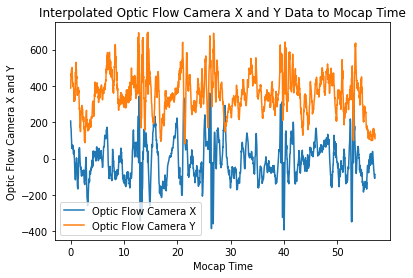

In [358]:
optic_flow_camera_x_time = data['optic_flow/camera/mean/x']['rosbagTimestamp']/1e9/2
optic_flow_camera_y_time = data['optic_flow/camera/mean/y']['rosbagTimestamp']/1e9/2
optic_flow_camera_x = data['optic_flow/camera/mean/x']['data']
optic_flow_camera_y = data['optic_flow/camera/mean/y']['data']

# get dt of optic flow camera data
optic_flow_camera_dt = np.mean(np.diff(optic_flow_camera_x_time))
print('optic_flow_camera_dt:', 1/optic_flow_camera_dt)

# interpolate optic flow camera data to mocap time
optic_flow_camera_x_mocap_interp = interpolate_data(optic_flow_camera_x_time, optic_flow_camera_x, mocap_time)
optic_flow_camera_y_mocap_interp = interpolate_data(optic_flow_camera_y_time, optic_flow_camera_y, mocap_time)

optic_flow_camera_x_mocap_interp=optic_flow_camera_x_mocap_interp
optic_flow_camera_y_mocap_interp=optic_flow_camera_y_mocap_interp

optic_flow_camera_x_mocap_interp[np.abs(optic_flow_camera_x_mocap_interp - np.median(optic_flow_camera_x_mocap_interp)) > 3 * np.std(optic_flow_camera_x_mocap_interp)] = np.median(optic_flow_camera_x_mocap_interp)
optic_flow_camera_y_mocap_interp[np.abs(optic_flow_camera_y_mocap_interp - np.median(optic_flow_camera_y_mocap_interp)) > 3 * np.std(optic_flow_camera_y_mocap_interp)] = np.median(optic_flow_camera_y_mocap_interp)

# Plot the interpolated data
plt.plot(mocap_time_shifted, optic_flow_camera_x_mocap_interp, label="Optic Flow Camera X")
plt.plot(mocap_time_shifted, optic_flow_camera_y_mocap_interp, label="Optic Flow Camera Y")
plt.title('Interpolated Optic Flow Camera X and Y Data to Mocap Time')
plt.xlabel('Mocap Time')
plt.ylabel('Optic Flow Camera X and Y')
plt.legend()
plt.show()

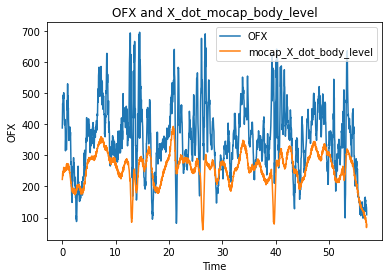

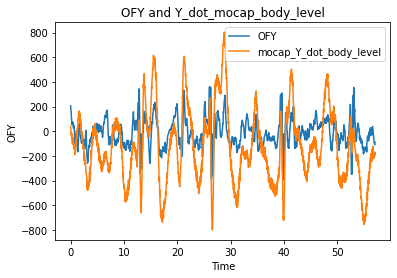

In [359]:
OFX=optic_flow_camera_x_mocap_interp.copy()
OFY=optic_flow_camera_y_mocap_interp.copy()

# apply a yaw rotation to the optic flow data using matrix multiplication
def rotate_optic_flow(OFX, OFY):
    """
    input: OFX, OFY
    output: rotated OFX, OFY
    """
    # apply a 180 degree rotation about x axis using the rotation matrix
    OFX = OFX*1
    OFY = OFY*np.cos(np.pi)

    # un yawing and rotating by 90 degrees
    OFY_rot = np.sin(np.pi/2) * OFX + np.cos(np.pi/2) * OFY
    OFX_rot = np.cos(np.pi/2) * OFX - np.sin(np.pi/2) * OFY
    return OFX_rot, OFY_rot


OFX_rot, OFY_rot = rotate_optic_flow(OFX, OFY)

plt.plot(mocap_time_shifted, OFX_rot,label='OFX')
plt.plot(mocap_time_shifted, np.multiply(velocity_body_x,300),label='mocap_X_dot_body_level')
plt.title('OFX and X_dot_mocap_body_level')
plt.xlabel('Time')
plt.ylabel('OFX')
plt.legend()
plt.show()

plt.plot(mocap_time_shifted, OFY_rot,label='OFY')
plt.plot(mocap_time_shifted, np.multiply(velocity_body_y,1500),label='mocap_Y_dot_body_level')
plt.title('OFY and Y_dot_mocap_body_level')
plt.xlabel('Time')
plt.ylabel('OFY')
plt.legend()
plt.show()


1713
Scalar (meters/pixel) X: 0.0009312377733203169
Scalar (meters/pixel) Y: 0.0007793948902274581


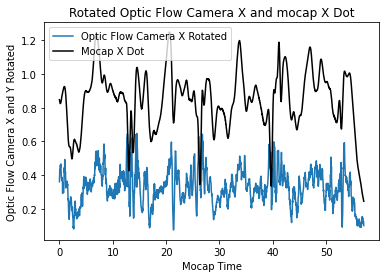

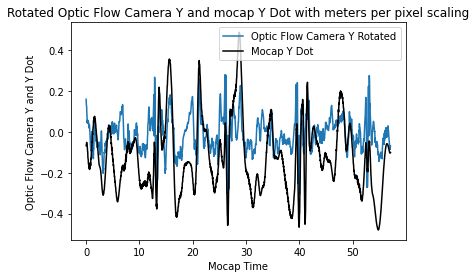

In [360]:
# Reshape the optic flow data to fit the linear regression model
OFX_rot_temp = np.array(OFX_rot)[:int(len(optic_flow_camera_x_mocap_interp)/1)].reshape(-1, 1)
OFY_rot_temp = np.array(OFY_rot)[:int(len(optic_flow_camera_x_mocap_interp)/1)].reshape(-1, 1)
print(len(OFY))
# Perform linear regression
modelX = LinearRegression()
modelX.fit(OFX_rot_temp, mocap_bl_X_dot[:int(len(optic_flow_camera_x_mocap_interp)/1)])

# The slope of the linear regression gives you the scalar (meters/pixel)
meters_per_pixel_X = modelX.coef_[0]
optic_flow_scalar_X = meters_per_pixel_X.copy()
print(f"Scalar (meters/pixel) X: {meters_per_pixel_X}")

modelY = LinearRegression()
modelY.fit(OFY_rot_temp, mocap_bl_Y_dot[:int(len(optic_flow_camera_x_mocap_interp)/1)])

# The slope of the linear regression gives you the scalar (meters/pixel)
meters_per_pixel_Y = modelY.coef_[0]
optic_flow_scalar_Y = meters_per_pixel_Y.copy()
print(f"Scalar (meters/pixel) Y: {meters_per_pixel_Y}")

# Plot the rotated optic flow data
plt.plot(mocap_time_shifted, np.multiply(OFX_rot,meters_per_pixel_X), label="Optic Flow Camera X Rotated")
plt.plot(mocap_time_shifted,np.multiply(mocap_bl_X_dot,1), label="Mocap X Dot",color='black')
# plt.plot(mocap_time, OFY_rot, label="Optic Flow Camera Y Rotated")
plt.title('Rotated Optic Flow Camera X and mocap X Dot')
plt.xlabel('Mocap Time')
plt.ylabel('Optic Flow Camera X and Y Rotated')
plt.legend()
plt.show()

plt.plot(mocap_time_shifted, np.multiply(OFY_rot,meters_per_pixel_Y), label="Optic Flow Camera Y Rotated")
plt.plot(mocap_time_shifted,np.multiply(mocap_bl_Y_dot,1), label="Mocap Y Dot",color='black')
plt.title('Rotated Optic Flow Camera Y and mocap Y Dot with meters per pixel scaling')
plt.xlabel('Mocap Time')
plt.ylabel('Optic Flow Camera Y and Y Dot')
plt.legend()
plt.show()

(0.0, 30.0)

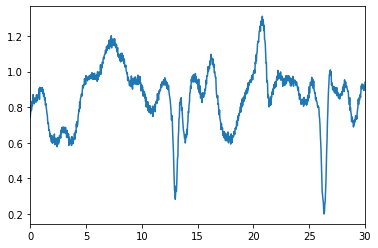

In [361]:
plt.plot(mocap_time_shifted,velocity_body_x, label='mavros X velocity')
plt.xlim([0,30])

# OF STATS MODEL

In [362]:
# save flow_x_mocap_interp and flow_y_mocap_interp and velocity_body_x and velocity_body_y to csv file
if motif == 'sine' and condition == 'walking':
    print('walking_data_dont_save')
else:
    df_of_x_y = pd.DataFrame({
        'flow_x': np.array(OFX_rot),
        'flow_y': np.array(OFY_rot),
        'vel_x': np.divide(velocity_body_x,mocap_Z),
        'vel_y': np.divide(velocity_body_y,mocap_Z),
        'Z': mocap_Z
    })
    df_of_x_y.to_csv(f'of_data_for_cal_{motif}.csv', index=False)

In [363]:
if motif == 'sine' and condition == 'walking':
    print('walking_data_dont_save')
else:
    # import the wind data from the csv files and make one data frame 
    df_of_mulit_motif = pd.DataFrame()
    for motif_i in ['p2p','p2p_con_yaw','sine']:
        df_temp = pd.read_csv(f'of_data_for_cal_{motif_i}.csv')
        df_temp['motif'] = motif_i
        df_of_mulit_motif = pd.concat([df_of_mulit_motif, df_temp], ignore_index=True)

    print(df_of_mulit_motif.head())

       flow_x     flow_y     vel_x     vel_y         Z motif
0 -185.306184  56.561738 -0.245632 -0.004728  1.882774   p2p
1 -176.415621  66.090092 -0.272104 -0.003673  1.884887   p2p
2 -165.453994  57.355877 -0.273578  0.015403  1.887961   p2p
3 -145.417293  50.380101 -0.280824 -0.019160  1.890014   p2p
4 -145.568168  43.303494 -0.292606  0.011972  1.892044   p2p


In [364]:
import pandas as pd
import statsmodels.formula.api as smf

In [365]:
motif

'sine'

                            OLS Regression Results                            
Dep. Variable:                  vel_x   R-squared:                       0.829
Model:                            OLS   Adj. R-squared:                  0.829
Method:                 Least Squares   F-statistic:                 3.329e+04
Date:                Thu, 10 Jul 2025   Prob (F-statistic):               0.00
Time:                        23:14:43   Log-Likelihood:                 4126.5
No. Observations:                6845   AIC:                            -8249.
Df Residuals:                    6843   BIC:                            -8235.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0231      0.002     13.515      0.0

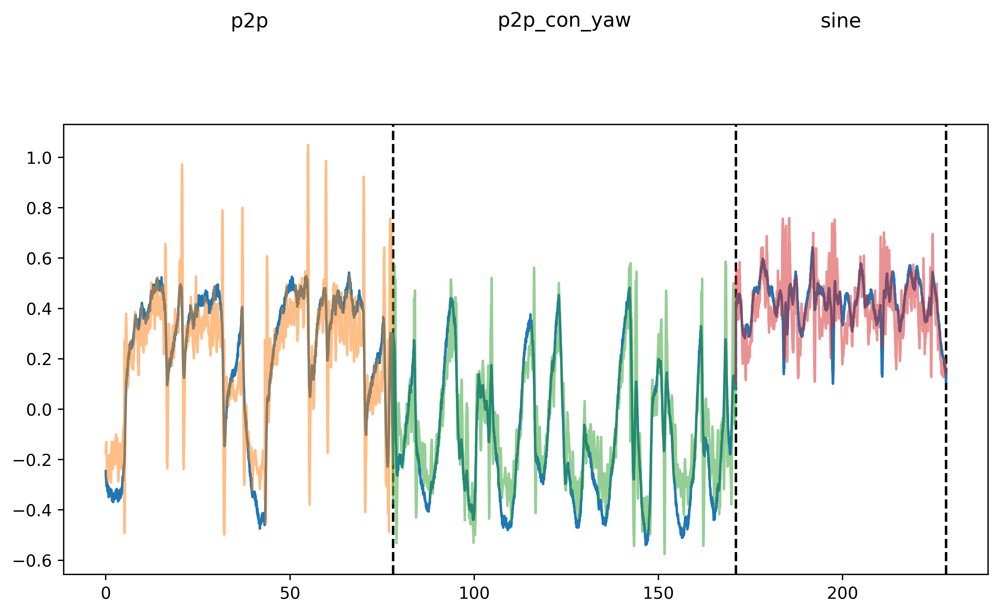

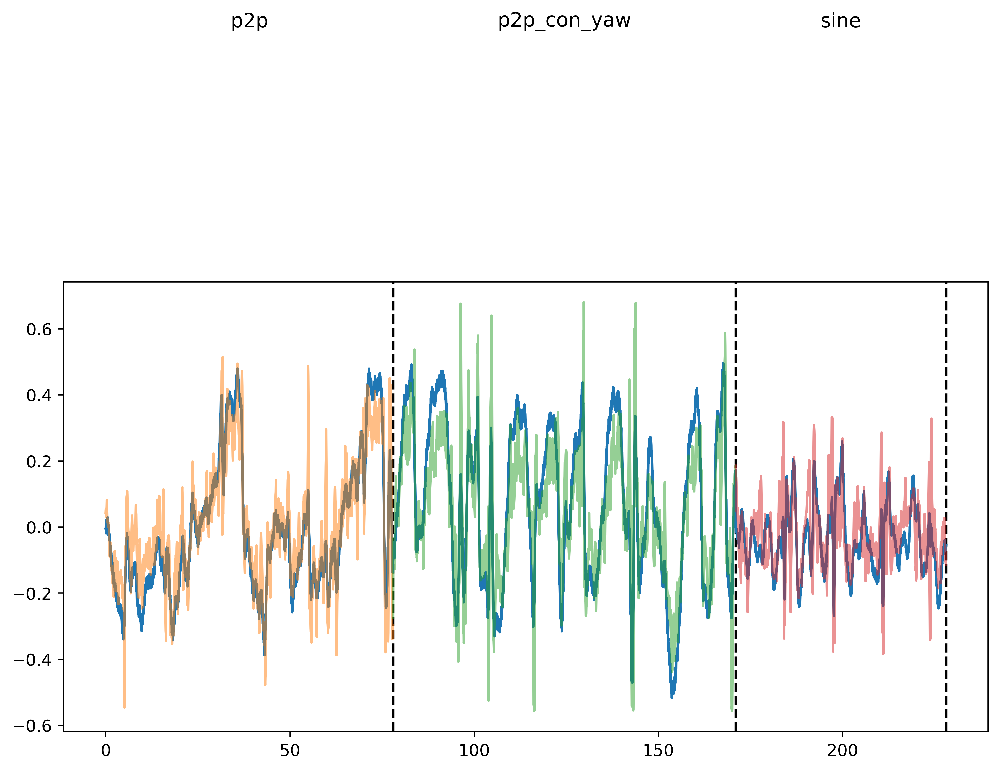

In [366]:
if motif == 'sine' and condition == 'walking':
    

    # Create DataFrame for X-axis
    df_X = pd.DataFrame({
        'flow': np.array(OFX_rot)[:len(optic_flow_camera_x_mocap_interp)],
        'vel': np.divide(velocity_body_x[:len(optic_flow_camera_x_mocap_interp)],mocap_Z[:len(optic_flow_camera_x_mocap_interp)])
    })

    # Run regression for X-axis
    modelX = smf.ols('vel ~ flow', data=df_X).fit()
    optic_flow_scalar_X = modelX.params['flow']
    optic_flow_intercept_X = modelX.params['Intercept']
    vel_from_optic_flow_X = optic_flow_scalar_X * np.array(OFX_rot)[:len(optic_flow_camera_x_mocap_interp)]+ optic_flow_intercept_X
    print(modelX.summary())
    print(f"Scalar (meters/pixel) X: {optic_flow_scalar_X}")

    # Create DataFrame for Y-axis
    df_Y = pd.DataFrame({
        'flow': np.array(OFY_rot)[:len(optic_flow_camera_x_mocap_interp)],
        'vel': np.divide(velocity_body_y[:len(optic_flow_camera_x_mocap_interp)],mocap_Z[:len(optic_flow_camera_x_mocap_interp)])
    })


    # Run regression for Y-axis
    modelY = smf.ols('vel ~ flow', data=df_Y).fit()
    optic_flow_scalar_Y = modelY.params['flow']
    optic_flow_intercept_Y = modelY.params['Intercept']
    vel_from_optic_flow_Y = optic_flow_scalar_Y * np.array(OFY_rot)[:len(optic_flow_camera_x_mocap_interp)]+ optic_flow_intercept_Y
    print(modelY.summary())
    print(f"Scalar (meters/pixel) Y: {optic_flow_scalar_Y}")

    OF_ground = np.sqrt(np.square(OFX_rot) + np.square(OFY_rot))
    V_ground = np.sqrt(np.square(velocity_body_x) + np.square(velocity_body_y))
    df_ground = pd.DataFrame({
        'flow': OF_ground[:len(optic_flow_camera_x_mocap_interp)],
        'vel': np.divide(V_ground[:len(optic_flow_camera_x_mocap_interp)],mocap_Z[:len(optic_flow_camera_x_mocap_interp)])
    })
    # Run regression for ground speed
    model_ground = smf.ols('vel ~ flow', data=df_ground).fit()
    optic_flow_scalar_ground = model_ground.params['flow']
    optic_flow_intercept_ground = model_ground.params['Intercept']
    vel_from_optic_flow_ground = optic_flow_scalar_ground * OF_ground[:len(optic_flow_camera_x_mocap_interp)] + optic_flow_intercept_ground
    print(model_ground.summary())
    print(f"Scalar (meters/pixel) Ground Speed: {optic_flow_scalar_ground}")

    # find the peaks in the mocap yaw rate data
    from scipy.signal import find_peaks
    positive_peaks, _ = find_peaks(mocap_Yaw_dot, height=0.1, distance=10)
    negative_peaks, _ = find_peaks(-mocap_Yaw_dot, height=0.1, distance=10)
    positive_peaks = np.array(positive_peaks, dtype=int)
    negative_peaks = np.array(negative_peaks, dtype=int)


    print("positive_peaks:", positive_peaks)
    print("negative_peaks:", negative_peaks)

    # plot the reconstructed velocity based on the optic flow data and the statsmodels
    fig, ax = plt.subplots(3, 1, figsize=(8, 6), dpi=500)
    # Plot X-axis
    ax[0].plot(mocap_time_shifted, vel_from_optic_flow_X, label="Reconstructed Velocity from Optic Flow X", color='blue')
    ax[0].plot(mocap_time_shifted, np.divide(velocity_body_x, mocap_Z), label="Mocap X Dot", color='black')
    # ax[0].scatter(mocap_time_shifted[positive_peaks], np.divide(mocap_bl_X_dot, mocap_Z)[positive_peaks], color='red', zorder=5)
    # ax[0].scatter(mocap_time_shifted[negative_peaks], np.divide(mocap_bl_X_dot, mocap_Z)[negative_peaks], color='red', zorder=5)
    ax[0].set_title('Reconstructed Velocity from Optic Flow X and Mocap X Dot')
    ax[0].set_xlabel('Mocap Time')
    ax[0].set_ylabel('Velocity (m/s)')
    ax[0].legend()
    print(str(np.std(vel_from_optic_flow_X - np.divide(velocity_body_x, mocap_Z)))+' HERE')
    # Plot Y-axis
    ax[1].plot(mocap_time_shifted, vel_from_optic_flow_Y, label="Reconstructed Velocity from Optic Flow Y", color='blue')
    ax[1].plot(mocap_time_shifted, np.divide(velocity_body_y, mocap_Z), label="Mocap Y Dot", color='black')
    # ax[1].scatter(mocap_time_shifted[positive_peaks], np.divide(mocap_bl_Y_dot, mocap_Z)[positive_peaks], color='red', zorder=5)
    # ax[1].scatter(mocap_time_shifted[negative_peaks], np.divide(mocap_bl_Y_dot, mocap_Z)[negative_peaks], color='red', zorder=5)
    ax[1].set_title('Reconstructed Velocity from Optic Flow Y and Mocap Y Dot')
    ax[1].set_xlabel('Mocap Time')
    ax[1].set_ylabel('Velocity (m/s)')
    ax[1].legend()
    print(str(np.std(vel_from_optic_flow_Y - np.divide(velocity_body_y, mocap_Z)))+' HERE')
    # Plot Ground Speed
    ax[2].plot(mocap_time_shifted, vel_from_optic_flow_ground, label="Reconstructed Ground Speed from Optic Flow", color='blue')
    ax[2].plot(mocap_time_shifted, np.divide(V_ground, mocap_Z), label="Mocap Ground Speed", color='black')
    # ax[2].scatter(mocap_time_shifted[positive_peaks], V_ground[positive_peaks], color='red', zorder=5)
    # ax[2].scatter(mocap_time_shifted[negative_peaks], V_ground[negative_peaks], color='red', zorder=5)
    ax[2].set_title('Reconstructed Ground Speed from Optic Flow and Mocap Ground Speed')
    ax[2].set_xlabel('Mocap Time')
    ax[2].set_ylabel('Ground Speed (m/s)')
    ax[2].legend()
    plt.tight_layout()
    plt.show()

    # angle of velocity vector
    Angle_of_velocity = np.arctan2(vel_from_optic_flow_Y, vel_from_optic_flow_X)
    magnitude_of_velocity = np.sqrt(np.square(vel_from_optic_flow_X) + np.square(vel_from_optic_flow_Y))
    # angle of the fitted optic flow vector
    Angle_of_optic_flow = np.arctan2(OFY_rot, OFX_rot)
    magnitude_of_optic_flow = np.sqrt(np.square(OFX_rot) + np.square(OFY_rot))
    # plot the angle of the velocity vector and the angle of the fitted optic flow vector
    fig, ax = plt.subplots(figsize=(8, 3), dpi=500)
    ax.plot(mocap_time_shifted, np.rad2deg(Angle_of_velocity), label="Angle of Velocity Vector", color='blue')
    ax.plot(mocap_time_shifted, np.rad2deg(Angle_of_optic_flow), label="Angle of Fitted Optic Flow Vector", color='orange')
    # ax.scatter(mocap_time_shifted[positive_peaks], np.rad2deg(Angle_of_velocity[positive_peaks]), color='red', zorder=5)
    # ax.scatter(mocap_time_shifted[negative_peaks], np.rad2deg(Angle_of_velocity[negative_peaks]), color='red', zorder=5)
    ax.set_title('Angle of Velocity Vector and Angle of Fitted Optic Flow Vector')
    ax.set_xlabel('Mocap Time')
    ax.set_ylabel('Angle (degrees)')
    ax.legend()
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(8, 3), dpi=500)
    # Plot the magnitude of the velocity vector and the magnitude of the fitted optic flow vector
    ax.plot(mocap_time_shifted, magnitude_of_velocity, label="Magnitude of Velocity Vector", color='blue')
    ax.plot(mocap_time_shifted, magnitude_of_optic_flow*0.001, label="Magnitude of Fitted Optic Flow Vector", color='orange')
    # ax.scatter(mocap_time_shifted[positive_peaks], magnitude_of_velocity[positive_peaks], color='red', zorder=5)
    # ax.scatter(mocap_time_shifted[negative_peaks], magnitude_of_velocity[negative_peaks], color='red', zorder=5)
    ax.set_title('Magnitude of Velocity Vector and Magnitude of Fitted Optic Flow Vector')
    ax.set_xlabel('Mocap Time')
    ax.set_ylabel('Magnitude (m/s)')
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    # Run regression for X-axis
    modelX = smf.ols('vel_x ~ flow_x', data=df_of_mulit_motif).fit()
    optic_flow_scalar_X = modelX.params['flow_x']
    optic_flow_intercept_X = modelX.params['Intercept']
    vel_from_optic_flow_X = df_of_mulit_motif['flow_x'] * optic_flow_scalar_X + optic_flow_intercept_X
    print(modelX.summary())
    print(f"Scalar (meters/pixel) X: {optic_flow_scalar_X}")

    # Run regression for Y-axis
    modelY = smf.ols('vel_y ~ flow_y', data=df_of_mulit_motif).fit()
    optic_flow_scalar_Y = modelY.params['flow_y']
    optic_flow_intercept_Y = modelY.params['Intercept']
    vel_from_optic_flow_Y = df_of_mulit_motif['flow_y'] * optic_flow_scalar_Y + optic_flow_intercept_Y
    print(modelY.summary())
    print(f"Scalar (meters/pixel) Y: {optic_flow_scalar_Y}")


    # find the iteration where motif changes in the data frame
    t1 = df_of_mulit_motif[df_of_mulit_motif['motif'] == 'p2p'].index[-1]
    t2 = df_of_mulit_motif[df_of_mulit_motif['motif'] == 'p2p_con_yaw'].index[-1]
    t3 = df_of_mulit_motif[df_of_mulit_motif['motif'] == 'sine'].index[-1]
    T_total = np.arange(0, len(df_of_mulit_motif)*mocap_dt, mocap_dt)
    print(f"t1: {t1}, t2: {t2}, t3: {t3}")
    print(f"Total time: {len(df_of_mulit_motif)*mocap_dt} seconds")
    print(f"Time for p2p: {t1*mocap_dt} seconds")
    print(f"Time for p2p_con_yaw: {(t2-t1)*mocap_dt} seconds")
    print(f"Time for sine: {(t3-t2)*mocap_dt} seconds")
    plt.figure(figsize=(10, 5), dpi=500)
    plt.axvline(x=T_total[t1], color='black', linestyle='--')
    plt.axvline(x=T_total[t2], color='black', linestyle='--')
    plt.axvline(x=T_total[t3], color='black', linestyle='--')
    plt.plot(T_total, df_of_mulit_motif['vel_x'])
    plt.plot(T_total[0:t1], vel_from_optic_flow_X[0:t1], alpha=0.5,label=f'Reconstructed {df_of_mulit_motif["motif"].iloc[t1-1]} Velocity from Optic Flow X and PWM')
    plt.plot(T_total[t1:t2], vel_from_optic_flow_X[t1:t2], alpha=0.5,label=f'Reconstructed {df_of_mulit_motif["motif"].iloc[t2-1]} Velocity from Optic Flow X and PWM')
    plt.plot(T_total[t2:t3], vel_from_optic_flow_X[t2:t3], alpha=0.5,label=f'Reconstructed {df_of_mulit_motif["motif"].iloc[t3-1]} Velocity from Optic Flow X and PWM')
    # add text above each section with motif name
    plt.text(T_total[t1]/2, 1.5, df_of_mulit_motif["motif"].iloc[t1-1], fontsize=12, ha='center', va='bottom')
    plt.text((T_total[t1]+T_total[t2])/2, 1.5, df_of_mulit_motif["motif"].iloc[t2-1], fontsize=12, ha='center', va='bottom')
    plt.text((T_total[t2]+T_total[t3])/2, 1.5, df_of_mulit_motif["motif"].iloc[t3-1], fontsize=12, ha='center', va='bottom')
    plt.show()

    plt.figure(figsize=(10, 5), dpi=500)
    plt.axvline(x=T_total[t1], color='black', linestyle='--')
    plt.axvline(x=T_total[t2], color='black', linestyle='--')
    plt.axvline(x=T_total[t3], color='black', linestyle='--')
    plt.plot(T_total, df_of_mulit_motif['vel_y'])
    plt.plot(T_total[0:t1], vel_from_optic_flow_Y[0:t1], alpha=0.5,label=f'Reconstructed {df_of_mulit_motif["motif"].iloc[t1-1]} Velocity from Optic Flow Y and PWM')
    plt.plot(T_total[t1:t2], vel_from_optic_flow_Y[t1:t2], alpha=0.5,label=f'Reconstructed {df_of_mulit_motif["motif"].iloc[t2-1]} Velocity from Optic Flow Y and PWM')
    plt.plot(T_total[t2:t3], vel_from_optic_flow_Y[t2:t3], alpha=0.5,label=f'Reconstructed {df_of_mulit_motif["motif"].iloc[t3-1]} Velocity from Optic Flow Y and PWM')
    # add text above each section with motif name
    plt.text(T_total[t1]/2, 1.5, df_of_mulit_motif["motif"].iloc[t1-1], fontsize=12, ha='center', va='bottom')
    plt.text((T_total[t1]+T_total[t2])/2, 1.5, df_of_mulit_motif["motif"].iloc[t2-1], fontsize=12, ha='center', va='bottom')
    plt.text((T_total[t2]+T_total[t3])/2, 1.5, df_of_mulit_motif["motif"].iloc[t3-1], fontsize=12, ha='center', va='bottom')
    plt.show()

## old Stats model

In [367]:


# # Create DataFrame for X-axis
# df_X = pd.DataFrame({
#     'flow': np.array(OFX_rot)[:len(optic_flow_camera_x_mocap_interp)],
#     'vel': np.divide(velocity_body_x[:len(optic_flow_camera_x_mocap_interp)],mocap_Z[:len(optic_flow_camera_x_mocap_interp)])
# })

# # Run regression for X-axis
# modelX = smf.ols('vel ~ flow', data=df_X).fit()
# optic_flow_scalar_X = modelX.params['flow']
# optic_flow_intercept_X = modelX.params['Intercept']
# vel_from_optic_flow_X = optic_flow_scalar_X * np.array(OFX_rot)[:len(optic_flow_camera_x_mocap_interp)]+ optic_flow_intercept_X
# print(modelX.summary())
# print(f"Scalar (meters/pixel) X: {optic_flow_scalar_X}")

# # Create DataFrame for Y-axis
# df_Y = pd.DataFrame({
#     'flow': np.array(OFY_rot)[:len(optic_flow_camera_x_mocap_interp)],
#     'vel': np.divide(velocity_body_y[:len(optic_flow_camera_x_mocap_interp)],mocap_Z[:len(optic_flow_camera_x_mocap_interp)])
# })


# # Run regression for Y-axis
# modelY = smf.ols('vel ~ flow', data=df_Y).fit()
# optic_flow_scalar_Y = modelY.params['flow']
# optic_flow_intercept_Y = modelY.params['Intercept']
# vel_from_optic_flow_Y = optic_flow_scalar_Y * np.array(OFY_rot)[:len(optic_flow_camera_x_mocap_interp)]+ optic_flow_intercept_Y
# print(modelY.summary())
# print(f"Scalar (meters/pixel) Y: {optic_flow_scalar_Y}")

# OF_ground = np.sqrt(np.square(OFX_rot) + np.square(OFY_rot))
# V_ground = np.sqrt(np.square(velocity_body_x) + np.square(velocity_body_y))
# df_ground = pd.DataFrame({
#     'flow': OF_ground[:len(optic_flow_camera_x_mocap_interp)],
#     'vel': np.divide(V_ground[:len(optic_flow_camera_x_mocap_interp)],mocap_Z[:len(optic_flow_camera_x_mocap_interp)])
# })
# # Run regression for ground speed
# model_ground = smf.ols('vel ~ flow', data=df_ground).fit()
# optic_flow_scalar_ground = model_ground.params['flow']
# optic_flow_intercept_ground = model_ground.params['Intercept']
# vel_from_optic_flow_ground = optic_flow_scalar_ground * OF_ground[:len(optic_flow_camera_x_mocap_interp)] + optic_flow_intercept_ground
# print(model_ground.summary())
# print(f"Scalar (meters/pixel) Ground Speed: {optic_flow_scalar_ground}")

# # find the peaks in the mocap yaw rate data
# from scipy.signal import find_peaks
# positive_peaks, _ = find_peaks(mocap_Yaw_dot, height=0.1, distance=10)
# negative_peaks, _ = find_peaks(-mocap_Yaw_dot, height=0.1, distance=10)
# positive_peaks = np.array(positive_peaks, dtype=int)
# negative_peaks = np.array(negative_peaks, dtype=int)


# print("positive_peaks:", positive_peaks)
# print("negative_peaks:", negative_peaks)

# # plot the reconstructed velocity based on the optic flow data and the statsmodels
# fig, ax = plt.subplots(3, 1, figsize=(8, 6), dpi=500)
# # Plot X-axis
# ax[0].plot(mocap_time_shifted, vel_from_optic_flow_X, label="Reconstructed Velocity from Optic Flow X", color='blue')
# ax[0].plot(mocap_time_shifted, np.divide(velocity_body_x, mocap_Z), label="Mocap X Dot", color='black')
# # ax[0].scatter(mocap_time_shifted[positive_peaks], np.divide(mocap_bl_X_dot, mocap_Z)[positive_peaks], color='red', zorder=5)
# # ax[0].scatter(mocap_time_shifted[negative_peaks], np.divide(mocap_bl_X_dot, mocap_Z)[negative_peaks], color='red', zorder=5)
# ax[0].set_title('Reconstructed Velocity from Optic Flow X and Mocap X Dot')
# ax[0].set_xlabel('Mocap Time')
# ax[0].set_ylabel('Velocity (m/s)')
# ax[0].legend()
# print(str(np.std(vel_from_optic_flow_X - np.divide(velocity_body_x, mocap_Z)))+' HERE')
# # Plot Y-axis
# ax[1].plot(mocap_time_shifted, vel_from_optic_flow_Y, label="Reconstructed Velocity from Optic Flow Y", color='blue')
# ax[1].plot(mocap_time_shifted, np.divide(velocity_body_y, mocap_Z), label="Mocap Y Dot", color='black')
# # ax[1].scatter(mocap_time_shifted[positive_peaks], np.divide(mocap_bl_Y_dot, mocap_Z)[positive_peaks], color='red', zorder=5)
# # ax[1].scatter(mocap_time_shifted[negative_peaks], np.divide(mocap_bl_Y_dot, mocap_Z)[negative_peaks], color='red', zorder=5)
# ax[1].set_title('Reconstructed Velocity from Optic Flow Y and Mocap Y Dot')
# ax[1].set_xlabel('Mocap Time')
# ax[1].set_ylabel('Velocity (m/s)')
# ax[1].legend()
# print(str(np.std(vel_from_optic_flow_Y - np.divide(velocity_body_y, mocap_Z)))+' HERE')
# # Plot Ground Speed
# ax[2].plot(mocap_time_shifted, vel_from_optic_flow_ground, label="Reconstructed Ground Speed from Optic Flow", color='blue')
# ax[2].plot(mocap_time_shifted, np.divide(V_ground, mocap_Z), label="Mocap Ground Speed", color='black')
# # ax[2].scatter(mocap_time_shifted[positive_peaks], V_ground[positive_peaks], color='red', zorder=5)
# # ax[2].scatter(mocap_time_shifted[negative_peaks], V_ground[negative_peaks], color='red', zorder=5)
# ax[2].set_title('Reconstructed Ground Speed from Optic Flow and Mocap Ground Speed')
# ax[2].set_xlabel('Mocap Time')
# ax[2].set_ylabel('Ground Speed (m/s)')
# ax[2].legend()
# plt.tight_layout()
# plt.show()

# # angle of velocity vector
# Angle_of_velocity = np.arctan2(vel_from_optic_flow_Y, vel_from_optic_flow_X)
# magnitude_of_velocity = np.sqrt(np.square(vel_from_optic_flow_X) + np.square(vel_from_optic_flow_Y))
# # angle of the fitted optic flow vector
# Angle_of_optic_flow = np.arctan2(OFY_rot, OFX_rot)
# magnitude_of_optic_flow = np.sqrt(np.square(OFX_rot) + np.square(OFY_rot))
# # plot the angle of the velocity vector and the angle of the fitted optic flow vector
# fig, ax = plt.subplots(figsize=(8, 3), dpi=500)
# ax.plot(mocap_time_shifted, np.rad2deg(Angle_of_velocity), label="Angle of Velocity Vector", color='blue')
# ax.plot(mocap_time_shifted, np.rad2deg(Angle_of_optic_flow), label="Angle of Fitted Optic Flow Vector", color='orange')
# # ax.scatter(mocap_time_shifted[positive_peaks], np.rad2deg(Angle_of_velocity[positive_peaks]), color='red', zorder=5)
# # ax.scatter(mocap_time_shifted[negative_peaks], np.rad2deg(Angle_of_velocity[negative_peaks]), color='red', zorder=5)
# ax.set_title('Angle of Velocity Vector and Angle of Fitted Optic Flow Vector')
# ax.set_xlabel('Mocap Time')
# ax.set_ylabel('Angle (degrees)')
# ax.legend()
# plt.tight_layout()
# plt.show()

# fig, ax = plt.subplots(figsize=(8, 3), dpi=500)
# # Plot the magnitude of the velocity vector and the magnitude of the fitted optic flow vector
# ax.plot(mocap_time_shifted, magnitude_of_velocity, label="Magnitude of Velocity Vector", color='blue')
# ax.plot(mocap_time_shifted, magnitude_of_optic_flow*0.001, label="Magnitude of Fitted Optic Flow Vector", color='orange')
# # ax.scatter(mocap_time_shifted[positive_peaks], magnitude_of_velocity[positive_peaks], color='red', zorder=5)
# # ax.scatter(mocap_time_shifted[negative_peaks], magnitude_of_velocity[negative_peaks], color='red', zorder=5)
# ax.set_title('Magnitude of Velocity Vector and Magnitude of Fitted Optic Flow Vector')
# ax.set_xlabel('Mocap Time')
# ax.set_ylabel('Magnitude (m/s)')
# ax.legend()
# plt.tight_layout()
# plt.show()

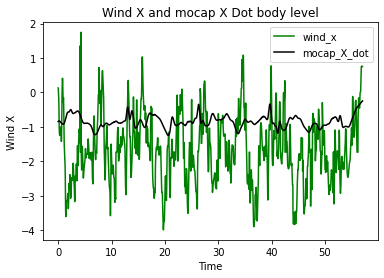

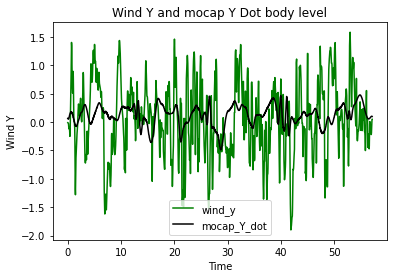

In [368]:
wind_time = data['trisonica']['rosbagTimestamp']/1e9/2
wind_time_shifted = wind_time - wind_time[0]
wind_x = data['trisonica']['westeast']
wind_y = -1*data['trisonica']['northsouth']

# interpolate wind data to mocap time
wind_x_mocap_interp = interpolate_data(wind_time, wind_x, mocap_time)
wind_y_mocap_interp = interpolate_data(wind_time, wind_y, mocap_time)

wind_x_mocap_interp = remove_outliers(wind_x_mocap_interp,threshold=4.0)
wind_y_mocap_interp = remove_outliers(wind_y_mocap_interp,threshold=4.0)

# # # filter out large spikes in the wind data
# if FLAG_FILE == "con_vel" or FLAG_FILE == "con_vel_con_yaw":
#     wind_x_mocap_interp[np.abs(wind_x_mocap_interp - np.median(wind_x_mocap_interp)) > 3 * np.std(wind_x_mocap_interp)] = np.median(wind_x_mocap_interp)
#     wind_y_mocap_interp[np.abs(wind_y_mocap_interp - np.median(wind_y_mocap_interp)) > 3 * np.std(wind_y_mocap_interp)] = np.median(wind_y_mocap_interp)


plt.plot(mocap_time_shifted, wind_x_mocap_interp,label='wind_x',color='green')
# plt.plot(wind_time_shifted, wind_x,label='wind_x',color='green')
# plt.plot(mocap_time_shifted, np.multiply(OFX_rot,meters_per_pixel_X), label="Optic Flow Camera X Rotated",color='blue')
plt.plot(mocap_time_shifted, np.multiply(mocap_bl_X_dot,-1),label='mocap_X_dot',color='black')
plt.title('Wind X and mocap X Dot body level')
plt.xlabel('Time')
plt.ylabel('Wind X')
plt.legend()
plt.show()

plt.plot(mocap_time_shifted, wind_y_mocap_interp,label='wind_y',color='green')
# plt.plot(mocap_time_shifted, np.multiply(OFY_rot,meters_per_pixel_Y), label="Optic Flow Camera Y Rotated",color='blue')
plt.plot(mocap_time_shifted, np.multiply(mocap_bl_Y_dot,-1),label='mocap_Y_dot',color='black')
plt.title('Wind Y and mocap Y Dot body level')
plt.xlabel('Time')
plt.ylabel('Wind Y')
plt.legend()
plt.show()

# mocap groung speed and direction
mocap_ground_speed = np.sqrt(np.square(mocap_bl_X_dot) + np.square(mocap_bl_Y_dot))
mocap_ground_direction = np.arctan2(mocap_bl_Y_dot, mocap_bl_X_dot)
wind_ground_speed = np.sqrt(np.square(wind_x_mocap_interp) + np.square(wind_y_mocap_interp))
wind_ground_direction = np.arctan2(wind_y_mocap_interp, wind_x_mocap_interp)

# plt.plot(mocap_time_shifted, mocap_ground_speed,label='mocap_ground_speed',color='black')
# plt.plot(mocap_time_shifted, wind_ground_speed,label='wind_speed',color='green')
# plt.title('Ground Speed')
# plt.xlabel('Time')
# plt.ylabel('Speed')
# plt.legend()
# plt.show()

# plt.plot(mocap_time_shifted, mocap_ground_direction,label='mocap_ground_direction',color='black')
# # plt.plot(mocap_time_shifted, wind_ground_direction,label='wind_direction',color='green')
# plt.title('Ground Direction')
# plt.xlabel('Time')
# plt.ylabel('Direction')
# plt.legend()
# plt.show()


Scalar X: 0.0028387257217409733
Scalar Y: -0.02202555998992299


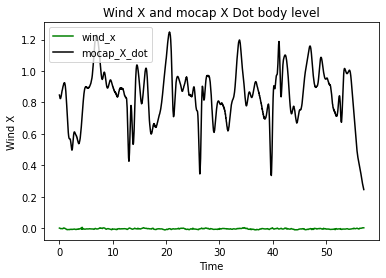

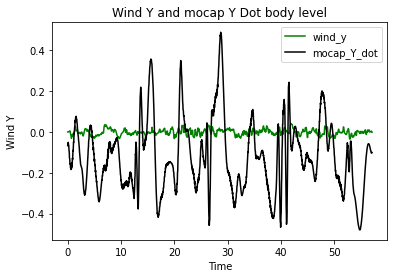

In [369]:

start_int_x = 0
stop_int_x = 4/4
start_int_y = 0
stop_int_y = 4/4

wind_body_level_x, wind_body_level_y =np.array(wind_x_mocap_interp).reshape(-1, 1), np.array(wind_y_mocap_interp).reshape(-1, 1)

wind_body_level_x_temp, wind_body_level_y_temp =np.array(wind_x_mocap_interp)[int(len(wind_x_mocap_interp)*start_int_x):int(len(wind_x_mocap_interp)*stop_int_x)].reshape(-1, 1), np.array(wind_y_mocap_interp).reshape(-1, 1)

wind_body_level_mag_temp = np.array(wind_ground_speed).reshape(-1, 1)

#perform linear regression on the wind data
model_wind_x = LinearRegression()
model_wind_x.fit(wind_body_level_x_temp, mocap_bl_X_dot[int(len(wind_x_mocap_interp)*start_int_x):int(len(wind_x_mocap_interp)*stop_int_x)])

# The slope of the linear regression gives you the scalar
wind_scalar_x = model_wind_x.coef_[0]
# print(model_wind_x.coef_)
print(f"Scalar X: {wind_scalar_x}")

model_wind_y = LinearRegression()
model_wind_y.fit(wind_body_level_y_temp, mocap_bl_Y_dot)

# The slope of the linear regression gives you the scalar
wind_scalar_y = model_wind_y.coef_[0]
print(f"Scalar Y: {wind_scalar_y}")

model_wind_mag = LinearRegression()
model_wind_mag.fit(wind_body_level_mag_temp, mocap_ground_speed)

# The slope of the linear regression gives you the scalar
wind_scalar_mag = model_wind_mag.coef_[0]
# print(f"Scalar (unitless) Mag: {wind_scalar_mag}")


# #mocap xy plot
# plt.plot(mocap_X, mocap_Y,label='mocap')
# plt.scatter(mocap_X, mocap_Y, label='start', c=mocap_time_shifted)
# plt.xlabel('X')
# plt.ylabel('Y')
# plt.title('XY')
# plt.colorbar()
# plt.show()

# #plot mocap yaw
# plt.plot(mocap_time_shifted, mocap_Yaw,label='Yaw')
# plt.scatter(mocap_time_shifted, mocap_Yaw, label='Yaw', c=mocap_time_shifted)
# plt.title('Yaw')
# plt.xlabel('Time')
# plt.ylabel('Yaw')
# plt.legend()
# plt.colorbar()
# plt.show()

# plt.plot(mocap_time_shifted, np.multiply(wind_body_level_x,-0.2410)+0.0530,label='wind_x',color='green')
plt.plot(mocap_time_shifted, np.multiply(wind_body_level_x,wind_scalar_x),label='wind_x',color='green')
plt.plot(mocap_time_shifted, mocap_bl_X_dot,label='mocap_X_dot',color='black')
plt.title('Wind X and mocap X Dot body level')
plt.xlabel('Time')
plt.ylabel('Wind X')
# plt.ylim(-1.5,1.5)
plt.legend()
plt.show()

# plt.plot(mocap_time_shifted, np.multiply(wind_body_level_y,-0.1438)+-0.2180,label='wind_y',color='green')
plt.plot(mocap_time_shifted, np.multiply(wind_body_level_y,wind_scalar_y),label='wind_y',color='green')
plt.plot(mocap_time_shifted, mocap_bl_Y_dot,label='mocap_Y_dot',color='black')
plt.title('Wind Y and mocap Y Dot body level')
plt.xlabel('Time')
plt.ylabel('Wind Y')
plt.legend()
plt.show()

# plt.plot(mocap_time_shifted, np.multiply(wind_ground_speed,wind_scalar_mag),label='wind_speed')
# plt.plot(mocap_time_shifted, mocap_ground_speed,label='mocap_ground_speed')
# plt.title('Ground Speed')
# plt.xlabel('Time')
# plt.ylabel('Speed')
# plt.legend()
# plt.show()


In [370]:
data['mavros/rc/out']
# split the data in header "channels" into individual columns named PWM1, PWM2, PWM3, PWM4 (only take the first 4 channels) each colum should be a float not a string
rc_time = data['mavros/rc/out']['rosbagTimestamp']/1e9/2
rc_time_shifted = rc_time - rc_time[0]
rc_channels = data['mavros/rc/out']['channels']
rc_channels = rc_channels.str.split(',', expand=True)
# remove "[" from the first column
rc_channels[0] = rc_channels[0].str.replace('[','')
rc_channels = rc_channels.iloc[:, :4]
rc_channels = rc_channels.astype(float)
PX4_1 = rc_channels[0]
PX4_2 = rc_channels[1]
PX4_3 = rc_channels[2]
PX4_4 = rc_channels[3]

pwm_1 = PX4_1
pwm_2 = PX4_2
pwm_3 = PX4_3
pwm_4 = PX4_4

PWM_1 = (interpolate_data(rc_time, pwm_1, mocap_time)-1150)/1000*9.81
PWM_2 = (interpolate_data(rc_time, pwm_2, mocap_time)-1150)/1000*9.81
PWM_3 = (interpolate_data(rc_time, pwm_3, mocap_time)-1150)/1000*9.81
PWM_4 = (interpolate_data(rc_time, pwm_4, mocap_time)-1150)/1000*9.81


/tmp/ipykernel_538566/2523009953.py:8: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  rc_channels[0] = rc_channels[0].str.replace('[','')


# WIND stats model

In [371]:
if motif == 'sine' and condition == 'walking':
    print("dont save data because its walking")
else:
    # save wind_x_mocap_interp and wind_y_mocap_interp and velocity_body_x and velocity_body_y to csv file
    df_wind_x_y = pd.DataFrame({
        'wind_x': np.array(wind_x_mocap_interp),
        'wind_y': np.array(wind_y_mocap_interp),
        'vel_x': velocity_body_x,
        'vel_y': velocity_body_y,
        'PWM_1': PWM_1,
        'PWM_2': PWM_2,
        'PWM_3': PWM_3,
        'PWM_4': PWM_4
    })
    df_wind_x_y.to_csv(f'wind_data_for_cal_{motif}.csv', index=False)

In [372]:
if motif == 'sine' and condition == 'walking':
    print("dont save data because its walking")
else:
    # import the wind data from the csv files and make one data frame 
    df_wind_mulit_motif = pd.DataFrame()
    for motif_i in ['p2p','p2p_con_yaw','sine']:
        df_temp = pd.read_csv(f'wind_data_for_cal_{motif_i}.csv')
        df_temp['motif'] = motif_i
        df_wind_mulit_motif = pd.concat([df_wind_mulit_motif, df_temp], ignore_index=True)

    print(df_wind_mulit_motif.head())

     wind_x    wind_y     vel_x     vel_y     PWM_1     PWM_2     PWM_3  \
0  2.190000 -0.540000 -0.462470 -0.008902  4.954050  5.032530  5.611320   
1  2.190000 -0.540000 -0.512885 -0.006923  4.953571  5.031860  5.612660   
2  2.215516 -0.667580 -0.516504  0.029080  4.935244  5.006201  5.663978   
3  2.240293 -0.791465 -0.530762 -0.036213  4.919828  4.984620  5.707141   
4  2.265736 -0.918682 -0.553623  0.022652  4.905626  4.965737  5.744698   

      PWM_4 motif  
0  5.689800   p2p  
1  5.691045   p2p  
2  5.738697   p2p  
3  5.778776   p2p  
4  5.812534   p2p  


R-squared for Wind X: 0.7679503277575782
                            OLS Regression Results                            
Dep. Variable:                  vel_x   R-squared:                       0.768
Model:                            OLS   Adj. R-squared:                  0.768
Method:                 Least Squares   F-statistic:                     4527.
Date:                Thu, 10 Jul 2025   Prob (F-statistic):               0.00
Time:                        23:14:52   Log-Likelihood:                -1737.4
No. Observations:                6845   AIC:                             3487.
Df Residuals:                    6839   BIC:                             3528.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  

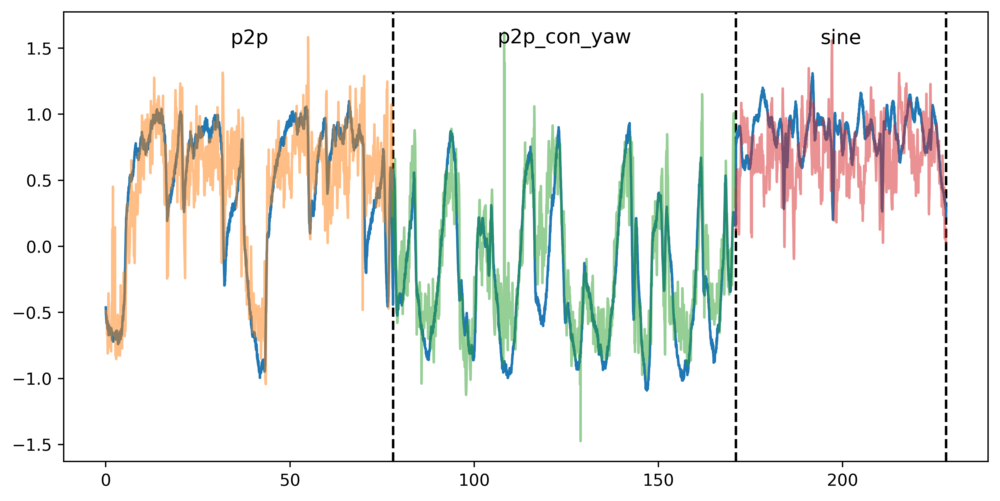

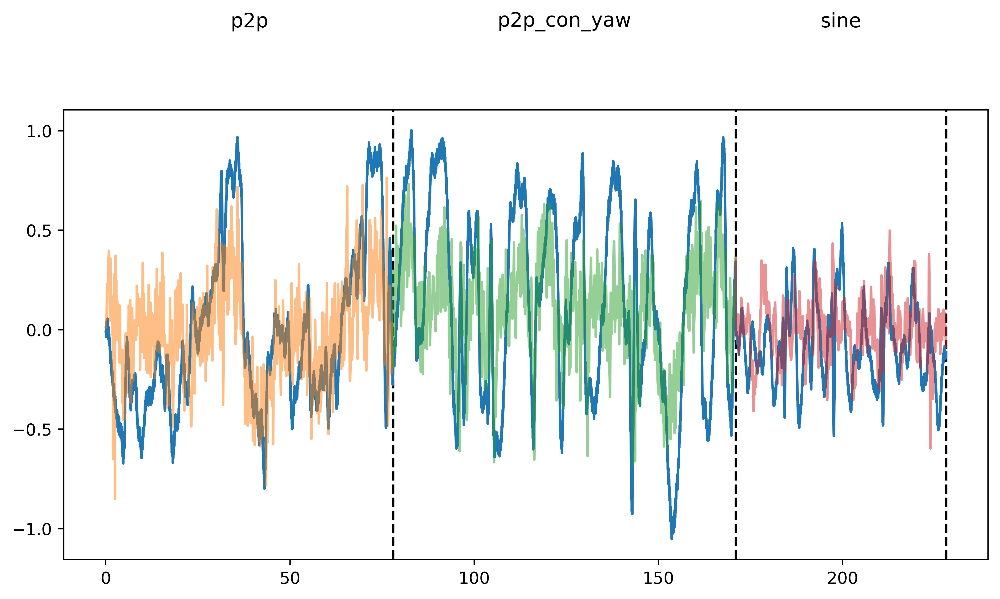

In [373]:
if motif == 'sine' and condition == 'walking':
    wind_intercept_x = 0
    wind_intercept_y = 0
    wind_scalar_x = -1
    wind_scalar_y = -1
    # # X-axis regression (full range)
    # vel_from_wind_x = wind_scalar_x * np.array(wind_x_mocap_interp) + wind_intercept_x
    vel_from_wind_x = wind_scalar_x * np.array(wind_x_mocap_interp) + wind_intercept_x
    # vel_from_wind_x = -0.2617 * np.array(wind_x_mocap_interp) + 0.1422
    print(f"Scalar X: {wind_scalar_x}")

    vel_from_wind_y = wind_scalar_y * np.array(wind_y_mocap_interp) + wind_intercept_y
    # vel_from_wind_y = -0.2316  * np.array(wind_y_mocap_interp) -0.0054
    print(f"Scalar Y: {wind_scalar_y}")

    # Plot the reconstructed velocity based on the wind data and the statsmodels
    fig, ax = plt.subplots(2, 1, figsize=(8, 12), dpi=600)
    # Plot X-axis
    ax[0].plot(mocap_time_shifted, vel_from_wind_x, label="Reconstructed Velocity from Wind X", color='green')
    ax[0].plot(mocap_time_shifted, velocity_body_x, label="Mocap X Dot", color='black')
    ax[0].set_title('Reconstructed Velocity from Wind X and Mocap X Dot')
    # ax[0].set_xlabel('Mocap Time')
    ax[0].set_ylabel('Velocity - X (m/s)')
    print(str(np.std(vel_from_wind_x - velocity_body_x))+' HERE')
    ax[0].legend()
    # Plot Y-axis
    ax[1].plot(mocap_time_shifted, vel_from_wind_y, label="Reconstructed Velocity from Wind Y", color='green')
    ax[1].plot(mocap_time_shifted, velocity_body_y, label="Mocap Y Dot", color='black')
    ax[1].set_title('Reconstructed Velocity from Wind Y and Mocap Y Dot')
    ax[1].set_xlabel('Mocap Time')
    ax[1].set_ylabel('Velocity - Y (m/s)')
    print(str(np.std(vel_from_wind_y - velocity_body_y))+' HERE')
    ax[1].legend()
    plt.tight_layout()
    plt.show()

else:


    model_wind_x = smf.ols('vel_x ~ wind_x + PWM_1 + PWM_2 + PWM_3 + PWM_4', data=df_wind_mulit_motif).fit()
    # model_wind_x = smf.ols('vel ~ wind', data=df_wind_x).fit()
    wind_scalar_x = model_wind_x.params['wind_x']
    PWM_1_scalar_x = model_wind_x.params['PWM_1']
    PWM_2_scalar_x = model_wind_x.params['PWM_2']
    PWM_3_scalar_x = model_wind_x.params['PWM_3']
    PWM_4_scalar_x = model_wind_x.params['PWM_4']
    wind_intercept_x = model_wind_x.params['Intercept']
    wind_x_r2 = model_wind_x.rsquared
    print(f"R-squared for Wind X: {wind_x_r2}")
    # vel_from_wind_x = wind_scalar_x * np.array(wind_x_mocap_interp) + wind_intercept_x
    vel_from_wind_x = wind_scalar_x * df_wind_mulit_motif['wind_x'] + PWM_1_scalar_x * df_wind_mulit_motif['PWM_1'] + PWM_2_scalar_x * df_wind_mulit_motif['PWM_2'] + PWM_3_scalar_x * df_wind_mulit_motif['PWM_3'] + PWM_4_scalar_x * df_wind_mulit_motif['PWM_4'] + wind_intercept_x
    # vel_from_wind_x = -0.2617 * np.array(wind_x_mocap_interp) + 0.1422
    print(model_wind_x.summary())
    print(f"Scalar X: {wind_scalar_x}")

    model_wind_y = smf.ols('vel_y ~ wind_y + PWM_1 + PWM_2 + PWM_3 + PWM_4', data=df_wind_mulit_motif).fit()
    # model_wind_y = smf.ols('vel ~ wind', data=df_wind_y).fit()
    wind_scalar_y = model_wind_y.params['wind_y']
    PWM_1_scalar_y = model_wind_y.params['PWM_1']
    PWM_2_scalar_y = model_wind_y.params['PWM_2']
    PWM_3_scalar_y = model_wind_y.params['PWM_3']
    PWM_4_scalar_y = model_wind_y.params['PWM_4']
    wind_intercept_y = model_wind_y.params['Intercept']
    wind_y_r2 = model_wind_y.rsquared
    print(f"R-squared for Wind Y: {wind_y_r2}")
    # vel_from_wind_y = wind_scalar_y * np.array(wind_y_mocap_interp) + wind_intercept_y
    vel_from_wind_y = wind_scalar_y * df_wind_mulit_motif['wind_y'] + PWM_1_scalar_y * df_wind_mulit_motif['PWM_1'] + PWM_2_scalar_y * df_wind_mulit_motif['PWM_2'] + PWM_3_scalar_y * df_wind_mulit_motif['PWM_3'] + PWM_4_scalar_y * df_wind_mulit_motif['PWM_4'] + wind_intercept_y
    # vel_from_wind_y = -0.1438 * np.array(wind_y_mocap_interp) + -0.2180
    print(model_wind_y.summary())
    print(f"Scalar Y: {wind_scalar_y}")

    # find the iteration where motif changes in the data frame
    t1 = df_wind_mulit_motif[df_wind_mulit_motif['motif'] == 'p2p'].index[-1]
    t2 = df_wind_mulit_motif[df_wind_mulit_motif['motif'] == 'p2p_con_yaw'].index[-1]
    t3 = df_wind_mulit_motif[df_wind_mulit_motif['motif'] == 'sine'].index[-1]
    T_total = np.arange(0, len(df_wind_mulit_motif)*mocap_dt, mocap_dt)
    print(f"t1: {t1}, t2: {t2}, t3: {t3}")
    print(f"Total time: {len(df_wind_mulit_motif)*mocap_dt} seconds")
    print(f"Time for p2p: {t1*mocap_dt} seconds")
    print(f"Time for p2p_con_yaw: {(t2-t1)*mocap_dt} seconds")
    print(f"Time for sine: {(t3-t2)*mocap_dt} seconds")
    plt.figure(figsize=(10, 5), dpi=500)
    plt.axvline(x=T_total[t1], color='black', linestyle='--')
    plt.axvline(x=T_total[t2], color='black', linestyle='--')
    plt.axvline(x=T_total[t3], color='black', linestyle='--')
    plt.plot(T_total, df_wind_mulit_motif['vel_x'])
    plt.plot(T_total[0:t1], vel_from_wind_x[0:t1], alpha=0.5,label=f'Reconstructed {df_wind_mulit_motif["motif"].iloc[t1-1]} Velocity from Wind X and PWM')
    plt.plot(T_total[t1:t2], vel_from_wind_x[t1:t2], alpha=0.5,label=f'Reconstructed {df_wind_mulit_motif["motif"].iloc[t2-1]} Velocity from Wind X and PWM')
    plt.plot(T_total[t2:t3], vel_from_wind_x[t2:t3], alpha=0.5,label=f'Reconstructed {df_wind_mulit_motif["motif"].iloc[t3-1]} Velocity from Wind X and PWM')
    # add text above each section with motif name
    plt.text(T_total[t1]/2, 1.5, df_wind_mulit_motif["motif"].iloc[t1-1], fontsize=12, ha='center', va='bottom')
    plt.text((T_total[t1]+T_total[t2])/2, 1.5, df_wind_mulit_motif["motif"].iloc[t2-1], fontsize=12, ha='center', va='bottom')
    plt.text((T_total[t2]+T_total[t3])/2, 1.5, df_wind_mulit_motif["motif"].iloc[t3-1], fontsize=12, ha='center', va='bottom')
    plt.show()

    plt.figure(figsize=(10, 5), dpi=500)
    plt.axvline(x=T_total[t1], color='black', linestyle='--')
    plt.axvline(x=T_total[t2], color='black', linestyle='--')
    plt.axvline(x=T_total[t3], color='black', linestyle='--')
    plt.plot(T_total, df_wind_mulit_motif['vel_y'])
    plt.plot(T_total[0:t1], vel_from_wind_y[0:t1], alpha=0.5,label=f'Reconstructed {df_wind_mulit_motif["motif"].iloc[t1-1]} Velocity from Wind Y and PWM')
    plt.plot(T_total[t1:t2], vel_from_wind_y[t1:t2], alpha=0.5,label=f'Reconstructed {df_wind_mulit_motif["motif"].iloc[t2-1]} Velocity from Wind Y and PWM')
    plt.plot(T_total[t2:t3], vel_from_wind_y[t2:t3], alpha=0.5,label=f'Reconstructed {df_wind_mulit_motif["motif"].iloc[t3-1]} Velocity from Wind Y and PWM')
    # add text above each section with motif name
    plt.text(T_total[t1]/2, 1.5, df_wind_mulit_motif["motif"].iloc[t1-1], fontsize=12, ha='center', va='bottom')
    plt.text((T_total[t1]+T_total[t2])/2, 1.5, df_wind_mulit_motif["motif"].iloc[t2-1], fontsize=12, ha='center', va='bottom')
    plt.text((T_total[t2]+T_total[t3])/2, 1.5, df_wind_mulit_motif["motif"].iloc[t3-1], fontsize=12, ha='center', va='bottom')
    plt.show()

In [374]:
# import pandas as pd
# import statsmodels.formula.api as smf




# # X-axis regression (full range)
# df_wind_x = pd.DataFrame({
#     'wind': np.array(wind_x_mocap_interp),
#     'vel': velocity_body_x,
#     'PWM_1': PWM_1,
#     'PWM_2': PWM_2,
#     'PWM_3': PWM_3,
#     'PWM_4': PWM_4
# })
# model_wind_x = smf.ols('vel ~ wind + PWM_1 + PWM_2 + PWM_3 + PWM_4', data=df_wind_x).fit()
# # model_wind_x = smf.ols('vel ~ wind', data=df_wind_x).fit()
# wind_scalar_x = model_wind_x.params['wind']
# PWM_1_scalar_x = model_wind_x.params['PWM_1']
# PWM_2_scalar_x = model_wind_x.params['PWM_2']
# PWM_3_scalar_x = model_wind_x.params['PWM_3']
# PWM_4_scalar_x = model_wind_x.params['PWM_4']
# wind_intercept_x = model_wind_x.params['Intercept']
# wind_x_r2 = model_wind_x.rsquared
# print(f"R-squared for Wind X: {wind_x_r2}")
# # vel_from_wind_x = wind_scalar_x * np.array(wind_x_mocap_interp) + wind_intercept_x
# vel_from_wind_x = wind_scalar_x * np.array(wind_x_mocap_interp) + PWM_1_scalar_x * PWM_1 + PWM_2_scalar_x * PWM_2 + PWM_3_scalar_x * PWM_3 + PWM_4_scalar_x * PWM_4 + wind_intercept_x
# # vel_from_wind_x = -0.2617 * np.array(wind_x_mocap_interp) + 0.1422
# print(model_wind_x.summary())
# print(f"Scalar X: {wind_scalar_x}")

# # Y-axis regression (full range)
# df_wind_y = pd.DataFrame({
#     'wind': np.array(wind_y_mocap_interp),
#     'vel': velocity_body_y,
#     'PWM_1': PWM_1,
#     'PWM_2': PWM_2,
#     'PWM_3': PWM_3,
#     'PWM_4': PWM_4
# })
# model_wind_y = smf.ols('vel ~ wind + PWM_1 + PWM_2 + PWM_3 + PWM_4', data=df_wind_y).fit()
# wind_scalar_y = model_wind_y.params['wind']
# PWM_1_scalar_y = model_wind_y.params['PWM_1']
# PWM_2_scalar_y = model_wind_y.params['PWM_2']
# PWM_3_scalar_y = model_wind_y.params['PWM_3']
# PWM_4_scalar_y = model_wind_y.params['PWM_4']
# wind_intercept_y = model_wind_y.params['Intercept']
# wind_y_r2 = model_wind_y.rsquared
# print(f"R-squared for Wind Y: {wind_y_r2}")
# vel_from_wind_y = wind_scalar_y * np.array(wind_y_mocap_interp) + PWM_1_scalar_y * PWM_1 + PWM_2_scalar_y * PWM_2 + PWM_3_scalar_y * PWM_3 + PWM_4_scalar_y * PWM_4 + wind_intercept_y
# # vel_from_wind_y = -0.2316  * np.array(wind_y_mocap_interp) -0.0054
# print(model_wind_y.summary())
# print(f"Scalar Y: {wind_scalar_y}")

# # Magnitude regression (full range)
# df_wind_mag = pd.DataFrame({
#     'wind': np.sqrt(np.square(wind_x_mocap_interp) + np.square(wind_y_mocap_interp)),
#     'vel': np.sqrt(np.square(velocity_body_x) + np.square(velocity_body_y)),
#     'PWM_1': PWM_1,
#     'PWM_2': PWM_2,
#     'PWM_3': PWM_3,
#     'PWM_4': PWM_4
# })
# model_wind_mag = smf.ols('vel ~ wind + PWM_1 + PWM_2 + PWM_3 + PWM_4', data=df_wind_mag).fit()
# wind_scalar_mag = model_wind_mag.params['wind']
# PWM_1_scalar_mag = model_wind_mag.params['PWM_1']
# PWM_2_scalar_mag = model_wind_mag.params['PWM_2']
# PWM_3_scalar_mag = model_wind_mag.params['PWM_3']
# PWM_4_scalar_mag = model_wind_mag.params['PWM_4']
# wind_intercept_mag = model_wind_mag.params['Intercept']
# vel_from_wind_mag = wind_scalar_mag * np.sqrt(np.square(wind_x_mocap_interp) + np.square(wind_y_mocap_interp)) + PWM_1_scalar_mag * PWM_1 + PWM_2_scalar_mag * PWM_2 + PWM_3_scalar_mag * PWM_3 + PWM_4_scalar_mag * PWM_4 + wind_intercept_mag
# print(model_wind_mag.summary())
# print(f"Scalar Mag: {wind_scalar_mag}")

# # Plot the reconstructed velocity based on the wind data and the statsmodels
# fig, ax = plt.subplots(3, 1, figsize=(8, 12), dpi=600)
# # Plot X-axis
# ax[0].plot(mocap_time_shifted, vel_from_wind_x, label="Reconstructed Velocity from Wind X", color='green')
# ax[0].plot(mocap_time_shifted, velocity_body_x, label="Mocap X Dot", color='black')
# ax[0].set_title('Reconstructed Velocity from Wind X and Mocap X Dot')
# # ax[0].set_xlabel('Mocap Time')
# ax[0].set_ylabel('Velocity - X (m/s)')
# print(str(np.std(vel_from_wind_x - velocity_body_x))+' HERE')
# ax[0].legend()
# # Plot Y-axis
# ax[1].plot(mocap_time_shifted, vel_from_wind_y, label="Reconstructed Velocity from Wind Y", color='green')
# ax[1].plot(mocap_time_shifted, velocity_body_y, label="Mocap Y Dot", color='black')
# ax[1].set_title('Reconstructed Velocity from Wind Y and Mocap Y Dot')
# ax[1].set_xlabel('Mocap Time')
# ax[1].set_ylabel('Velocity - Y (m/s)')
# print(str(np.std(vel_from_wind_y - velocity_body_y))+' HERE')
# ax[1].legend()
# # Plot Ground Speed
# ax[2].plot(mocap_time_shifted, vel_from_wind_mag, label="Reconstructed Ground Speed from Wind", color='green')
# ax[2].plot(mocap_time_shifted, np.sqrt(np.square(velocity_body_x) + np.square(velocity_body_y)), label="Mocap Ground Speed", color='black')
# ax[2].set_title('Reconstructed Ground Speed from Wind and Mocap Ground Speed')
# ax[2].set_xlabel('Mocap Time')
# ax[2].set_ylabel('Ground Speed (m/s)')
# ax[2].legend()
# plt.tight_layout()
# plt.show()


# RC Out ~ PWM

In [375]:
data['mavros/rc/out']
# split the data in header "channels" into individual columns named PWM1, PWM2, PWM3, PWM4 (only take the first 4 channels) each colum should be a float not a string
rc_time = data['mavros/rc/out']['rosbagTimestamp']/1e9/2
rc_time_shifted = rc_time - rc_time[0]
rc_channels = data['mavros/rc/out']['channels']
rc_channels = rc_channels.str.split(',', expand=True)
# remove "[" from the first column
rc_channels[0] = rc_channels[0].str.replace('[','')
rc_channels = rc_channels.iloc[:, :4]
rc_channels = rc_channels.astype(float)
PX4_1 = rc_channels[0]
PX4_2 = rc_channels[1]
PX4_3 = rc_channels[2]
PX4_4 = rc_channels[3]



/tmp/ipykernel_538566/2308055145.py:8: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  rc_channels[0] = rc_channels[0].str.replace('[','')


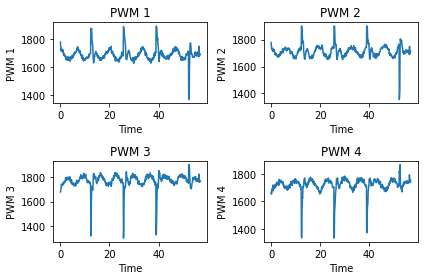

In [376]:
# pwm_1 = PX4_3
# pwm_2 = PX4_1
# pwm_3 = PX4_4
# pwm_4 = PX4_2

pwm_1 = PX4_1
pwm_2 = PX4_2
pwm_3 = PX4_3
pwm_4 = PX4_4
# 2x2 plot of the pwm data
plt.subplot(2, 2, 1)
plt.plot(rc_time_shifted, pwm_1)
plt.title('PWM 1')
plt.xlabel('Time')
plt.ylabel('PWM 1')

plt.subplot(2, 2, 2)
plt.plot(rc_time_shifted, pwm_2)
plt.title('PWM 2')
plt.xlabel('Time')
plt.ylabel('PWM 2')

plt.subplot(2, 2, 3)
plt.plot(rc_time_shifted, pwm_3)
plt.title('PWM 3')
plt.xlabel('Time')
plt.ylabel('PWM 3')

plt.subplot(2, 2, 4)
plt.plot(rc_time_shifted, pwm_4)
plt.title('PWM 4')
plt.xlabel('Time')
plt.ylabel('PWM 4')

plt.tight_layout()
plt.show()

# Get the final values fir all the measured data

## since mocap is the fastes we will interpolate to that

### Mocap Final

In [377]:
X_TRUE = mocap_X
X_DOT_G_TRUE = mocap_X_dot
# X_DOT_BL_TRUE = mocap_bl_X_dot
X_DOT_BL_TRUE = velocity_body_x
Y_TRUE = mocap_Y
Y_DOT_G_TRUE = mocap_Y_dot
# Y_DOT_BL_TRUE = mocap_bl_Y_dot
Y_DOT_BL_TRUE = velocity_body_y
Z_TRUE = mocap_Z
Z_DOT_G_TRUE = mocap_Z_dot
# Z_DOT_BL_TRUE = mocap_bl_Z_dot
Z_DOT_BL_TRUE = velocity_body_z
Roll_TRUE = mocap_Roll
Pitch_TRUE = mocap_Pitch
Yaw_TRUE = mocap_Yaw
OMEGA_X_TRUE = mocap_Omega_x
OMEGA_Y_TRUE = mocap_Omega_y
OMEGA_Z_TRUE = mocap_Omega_z

# put into a dataframe
df_all = pd.DataFrame({
    'X_TRUE': X_TRUE,
    'X_DOT_G_TRUE': X_DOT_G_TRUE,
    'X_DOT_BL_TRUE': X_DOT_BL_TRUE,
    'Y_TRUE': Y_TRUE,
    'Y_DOT_G_TRUE': Y_DOT_G_TRUE,
    'Y_DOT_BL_TRUE': Y_DOT_BL_TRUE,
    'Z_TRUE': Z_TRUE,
    'Z_DOT_G_TRUE': Z_DOT_G_TRUE,
    'Z_DOT_BL_TRUE': Z_DOT_BL_TRUE,
    'Roll_TRUE': Roll_TRUE,
    'Pitch_TRUE': Pitch_TRUE,
    'Yaw_TRUE': Yaw_TRUE,
    'OMEGA_X_TRUE': OMEGA_X_TRUE,
    'OMEGA_Y_TRUE': OMEGA_Y_TRUE,
    'OMEGA_Z_TRUE': OMEGA_Z_TRUE
})

# IMU Final

In [378]:
IMU_ROLL = mocap_Roll
IMU_PITCH = mocap_Pitch
IMU_YAW = mocap_Yaw
# IMU_ROLL_DOT = interpolate_data(imu_time, imu_Roll_dot, mocap_time)
# IMU_PITCH_DOT = interpolate_data(imu_time, imu_Pitch_dot, mocap_time)
# IMU_YAW_DOT = interpolate_data(imu_time, imu_Yaw_dot, mocap_time)
# IMU_OMEGA_X = interpolate_data(imu_time, imu_omega_x, mocap_time)
IMU_OMEGA_X = mocap_Omega_x
# IMU_OMEGA_Y = interpolate_data(imu_time, imu_omega_y, mocap_time)
IMU_OMEGA_Y = mocap_Omega_y
# IMU_OMEGA_Z = interpolate_data(imu_time, imu_omega_z, mocap_time)
IMU_OMEGA_Z = mocap_Omega_z
# IMU_ACC_BL_X = interpolate_data(imu_time, acc_x_body_level, mocap_time)
IMU_ACC_BL_X = accleration_body_x
# IMU_ACC_BL_Y = interpolate_data(imu_time, acc_y_body_level, mocap_time)
IMU_ACC_BL_Y = accleration_body_y
# IMU_ACC_BL_Z = interpolate_data(imu_time, acc_z_body_level, mocap_time)
IMU_ACC_BL_Z = accleration_body_z
print(np.shape(acc_z_body_level))

# add to df_all
df_all['IMU_ROLL'] = IMU_ROLL
df_all['IMU_PITCH'] = IMU_PITCH
df_all['IMU_YAW'] = IMU_YAW
# df_all['IMU_ROLL_DOT'] = IMU_ROLL_DOT
# df_all['IMU_PITCH_DOT'] = IMU_PITCH_DOT
# df_all['IMU_YAW_DOT'] = IMU_YAW_DOT
df_all['IMU_OMEGA_X'] = IMU_OMEGA_X
df_all['IMU_OMEGA_Y'] = IMU_OMEGA_Y
df_all['IMU_OMEGA_Z'] = IMU_OMEGA_Z
df_all['IMU_ACC_BL_X'] = IMU_ACC_BL_X
df_all['IMU_ACC_BL_Y'] = IMU_ACC_BL_Y
df_all['IMU_ACC_BL_Z'] = IMU_ACC_BL_Z
# df_all.to_csv('df_all.csv', index=False)

(2854,)


# Wind sensor fianl

In [379]:
if motif == 'sine' and condition == 'walking':
    Wind_BL_X = np.ravel(np.array(wind_body_level_x))
    Wind_BL_Y = np.ravel(np.array(wind_body_level_y))
    Wind_BL_X_f = 1*wind_scalar_x
    print(f"Wind BL X scalar: {Wind_BL_X_f}")
    # Wind_BL_X_f = -0.2580
    Wind_BL_X_offset = wind_intercept_x
    print(f"Wind BL X offset: {Wind_BL_X_offset}")
    # Wind_BL_X_offset = 0.1175
    Wind_BL_Y_f = 1*wind_scalar_y
    print(f"Wind BL Y scalar: {Wind_BL_Y_f}")
    # Wind_BL_Y_f = -0.2478
    Wind_BL_Y_offset = wind_intercept_y
    print(f"Wind BL Y offset: {Wind_BL_Y_offset}")
    # Wind_BL_Y_offset = -0.1869
    Wind_BL_X_Scaled = np.multiply(Wind_BL_X, Wind_BL_X_f) + Wind_BL_X_offset
    # Wind_BL_X_Scaled = Wind_BL_X
    Wind_BL_Y_Scaled = np.multiply(Wind_BL_Y, Wind_BL_Y_f) + Wind_BL_Y_offset
    # Wind_BL_Y_Scaled = Wind_BL_Y
    Wind_BL_A = np.sqrt(np.square(Wind_BL_X_Scaled) + np.square(Wind_BL_Y_Scaled))
    Wind_BL_Gamma = np.arctan2(Wind_BL_Y_Scaled, Wind_BL_X_Scaled)
else:
    Wind_BL_X = np.ravel(np.array(wind_body_level_x))
    Wind_BL_Y = np.ravel(np.array(wind_body_level_y))
    Wind_BL_X_f = 1*wind_scalar_x
    print(f"Wind BL X scalar: {Wind_BL_X_f}")
    # Wind_BL_X_f = -0.2580
    Wind_BL_X_offset = wind_intercept_x
    print(f"Wind BL X offset: {Wind_BL_X_offset}")
    # Wind_BL_X_offset = 0.1175
    Wind_BL_Y_f = 1*wind_scalar_y
    print(f"Wind BL Y scalar: {Wind_BL_Y_f}")
    # Wind_BL_Y_f = -0.2478
    Wind_BL_Y_offset = wind_intercept_y
    print(f"Wind BL Y offset: {Wind_BL_Y_offset}")
    # Wind_BL_Y_offset = -0.1869
    Wind_BL_X_Scaled = np.multiply(Wind_BL_X, Wind_BL_X_f) + PWM_1_scalar_x* PWM_1 + PWM_2_scalar_x * PWM_2 + PWM_3_scalar_x * PWM_3 + PWM_4_scalar_x * PWM_4 + Wind_BL_X_offset
    # Wind_BL_X_Scaled = Wind_BL_X
    Wind_BL_Y_Scaled = np.multiply(Wind_BL_Y, Wind_BL_Y_f) + PWM_1_scalar_y * PWM_1 + PWM_2_scalar_y * PWM_2 + PWM_3_scalar_y * PWM_3 + PWM_4_scalar_y * PWM_4 + Wind_BL_Y_offset
    # Wind_BL_Y_Scaled = Wind_BL_Y
    Wind_BL_A = np.sqrt(np.square(Wind_BL_X_Scaled) + np.square(Wind_BL_Y_Scaled))
    Wind_BL_Gamma = np.arctan2(Wind_BL_Y_Scaled, Wind_BL_X_Scaled)
# add to df_all
df_all['Wind_BL_X'] = Wind_BL_X
df_all['Wind_BL_Y'] = Wind_BL_Y
df_all['Wind_BL_X_Scaled'] = Wind_BL_X_Scaled
df_all['Wind_BL_Y_Scaled'] = Wind_BL_Y_Scaled
df_all['Wind_BL_A'] = Wind_BL_A
df_all['Wind_BL_Gamma'] = Wind_BL_Gamma


Wind BL X scalar: -0.17271413392632795
Wind BL X offset: -1.418936042123189
Wind BL Y scalar: -0.13511100052431
Wind BL Y offset: 0.11964385615270777


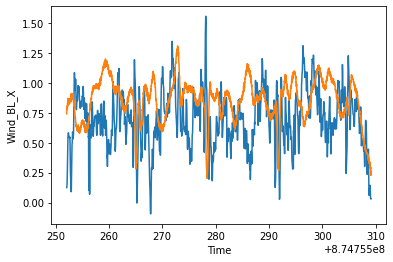

Standard deviation of Wind_BL_X_Scaled - X_DOT_BL_TRUE: 0.2927973319069496
Standard deviation of Wind_BL_Y_Scaled - Y_DOT_BL_TRUE: 0.21996297068289597
Average standard deviation of Wind_BL_X_Scaled - X_DOT_BL_TRUE and Wind_BL_Y_Scaled - Y_DOT_BL_TRUE: 0.2563801512949228


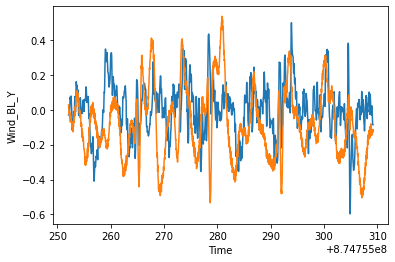

In [380]:
plt.plot(mocap_time, Wind_BL_X_Scaled,label='Wind_X_f')
plt.plot(mocap_time, X_DOT_BL_TRUE,label='X_DOT_BL_TRUE')
plt.xlabel('Time')
plt.ylabel('Wind_BL_X')
plt.show()

plt.plot(mocap_time, Wind_BL_Y_Scaled,label='Wind_Y_f')
plt.plot(mocap_time, Y_DOT_BL_TRUE,label='Y_DOT_BL_TRUE')
plt.xlabel('Time')
plt.ylabel('Wind_BL_Y')
plt.show

std_dev_wax = np.std(Wind_BL_X_Scaled-X_DOT_BL_TRUE)
print('Standard deviation of Wind_BL_X_Scaled - X_DOT_BL_TRUE:', std_dev_wax)
std_dev_way = np.std(Wind_BL_Y_Scaled-Y_DOT_BL_TRUE)
print('Standard deviation of Wind_BL_Y_Scaled - Y_DOT_BL_TRUE:', std_dev_way)
std_dev_wa_avg = np. mean([std_dev_wax, std_dev_way])
print('Average standard deviation of Wind_BL_X_Scaled - X_DOT_BL_TRUE and Wind_BL_Y_Scaled - Y_DOT_BL_TRUE:', std_dev_wa_avg)

# optic flow final

In [381]:
OF_BL_X, OF_BL_Y = rotate_optic_flow(optic_flow_camera_x_mocap_interp, optic_flow_camera_y_mocap_interp)
OF_BL_X_f = optic_flow_scalar_X.copy()
print(OF_BL_X_f)
OF_BL_X_offset = optic_flow_intercept_X.copy()
print(OF_BL_X_offset)
OF_BL_Y_f = optic_flow_scalar_Y
OF_BL_Y_offset = optic_flow_intercept_Y
OF_BL_X_Scaled = np.multiply(OF_BL_X,OF_BL_X_f) + OF_BL_X_offset
OF_BL_Y_Scaled = np.multiply(OF_BL_Y,OF_BL_Y_f) + OF_BL_Y_offset

# add to df_all
df_all['OF_BL_X'] = OF_BL_X
df_all['OF_BL_Y'] = OF_BL_Y
df_all['OF_BL_X_Scaled'] = OF_BL_X_Scaled
df_all['OF_BL_Y_Scaled'] = OF_BL_Y_Scaled

0.0010573727194647688
0.02314069116635657


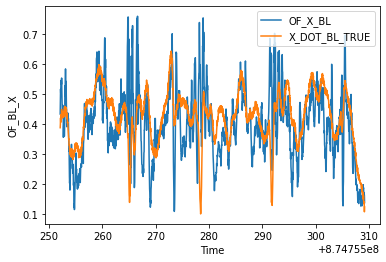

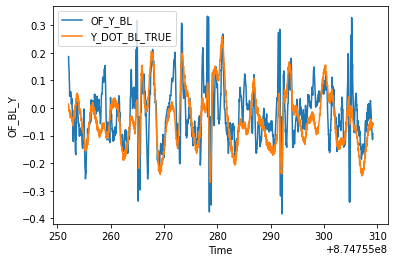

Standard deviation of OF_BL_X_Scaled - np.divide(X_DOT_BL_TRUE,Z_TRUE): 0.10391563345198404
Standard deviation of OF_BL_Y_Scaled - np.divide(Y_DOT_BL_TRUE,Z_TRUE): 0.09167908291928796
Average standard deviation of OF_BL_X_Scaled - np.divide(X_DOT_BL_TRUE,Z_TRUE) and OF_BL_Y_Scaled - np.divide(Y_DOT_BL_TRUE,Z_TRUE): 0.09779735818563601


In [382]:
plt.plot(mocap_time, OF_BL_X_Scaled,label='OF_X_BL')
plt.plot(mocap_time, np.divide(X_DOT_BL_TRUE,Z_TRUE),label='X_DOT_BL_TRUE')
plt.xlabel('Time')
plt.ylabel('OF_BL_X')
plt.legend()
plt.show()

plt.plot(mocap_time, OF_BL_Y_Scaled,label='OF_Y_BL')
plt.plot(mocap_time, np.divide(Y_DOT_BL_TRUE,Z_TRUE),label='Y_DOT_BL_TRUE')
plt.xlabel('Time')
plt.ylabel('OF_BL_Y')
plt.legend()
plt.show()

# calculate the standard deviation of OF_BL_X_Scaled -np.divide(X_DOT_BL_TRUE,Z_TRUE) and print it
std_dev_ofx = np.std(OF_BL_X_Scaled-np.divide(X_DOT_BL_TRUE,Z_TRUE))
print('Standard deviation of OF_BL_X_Scaled - np.divide(X_DOT_BL_TRUE,Z_TRUE):', std_dev_ofx)
std_dev_ofy = np.std(OF_BL_Y_Scaled-np.divide(Y_DOT_BL_TRUE,Z_TRUE))
print('Standard deviation of OF_BL_Y_Scaled - np.divide(Y_DOT_BL_TRUE,Z_TRUE):', std_dev_ofy)
std_dev_of_avg = np.mean([std_dev_ofx, std_dev_ofy])
print('Average standard deviation of OF_BL_X_Scaled - np.divide(X_DOT_BL_TRUE,Z_TRUE) and OF_BL_Y_Scaled - np.divide(Y_DOT_BL_TRUE,Z_TRUE):', std_dev_of_avg)

# plt.plot(mocap_time, OF_BL_X_Scaled-np.divide(X_DOT_BL_TRUE,Z_TRUE),label='OF_BL_X-X_DOT_BL')

# PWM Final

In [383]:
PWM_1 = (interpolate_data(rc_time, pwm_1, mocap_time)-1150)/1000*9.81
PWM_2 = (interpolate_data(rc_time, pwm_2, mocap_time)-1150)/1000*9.81
PWM_3 = (interpolate_data(rc_time, pwm_3, mocap_time)-1150)/1000*9.81
PWM_4 = (interpolate_data(rc_time, pwm_4, mocap_time)-1150)/1000*9.81

# add to df_all
df_all['PWM_1'] = PWM_1
df_all['PWM_2'] = PWM_2
df_all['PWM_3'] = PWM_3
df_all['PWM_4'] = PWM_4

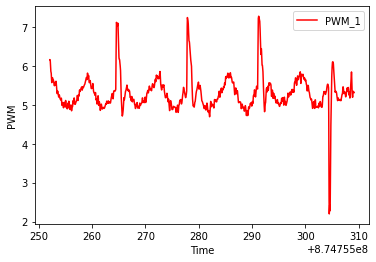

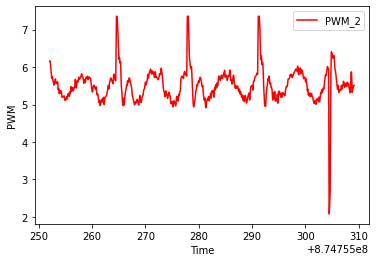

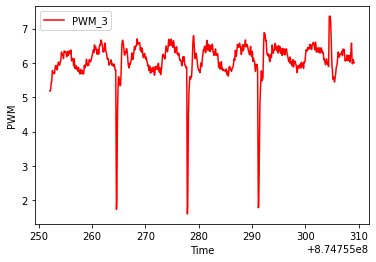

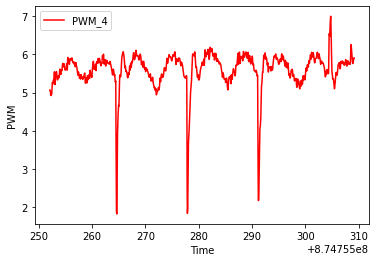

In [384]:
plt.plot(mocap_time, PWM_1,label='PWM_1',color='red')
plt.xlabel('Time')
plt.ylabel('PWM')
plt.legend()
plt.show()
plt.plot(mocap_time, PWM_2,label='PWM_2',color='red')
plt.xlabel('Time')
plt.ylabel('PWM')
plt.legend()
plt.show()
plt.plot(mocap_time, PWM_3,label='PWM_3',color='red')
plt.xlabel('Time')
plt.ylabel('PWM')
plt.legend()
plt.show()
plt.plot(mocap_time, PWM_4,label='PWM_4',color='red')
plt.xlabel('Time')
plt.ylabel('PWM')
plt.legend()
plt.show()

# Time

In [385]:
TIME_BL = mocap_time-mocap_time[0]
DT_BL=np.round(TIME_BL[1]-TIME_BL[0],2)
print(DT_BL)

# add to df_all
df_all['TIME_BL'] = TIME_BL

0.03


In [386]:
g = 9.81  # gravity [m/s^2]
m = 0.086  # mass [kg]
M = 2.529  # mass [kg]
Mm = 4 * m + M  # total mass [kg]
L = 0.2032  # length [m]
R = 0.1778  # average body radius [m]
I_x = .491
# self.I_x = 2 * (self.M * self.R ** 2) / 5 + 2 * self.m * self.L ** 2  # [kg*m^2] moment of inertia about x
I_y = .387
# self.I_y = 2 * (self.M * self.R ** 2) / 5 + 2 * self.m * self.L ** 2  # [kg*m^2] moment of inertia about y
I_z = .667
# self.I_z = 2 * (self.M * self.R ** 2) / 5 + 4 * self.m * self.L ** 2  # [kg*m^2] moment of inertia about y
# b = 1.8311  # thrust coefficient
# d = 1  # drag constant
# C = 0.1  # drag coefficient from ground speed plus air speed
b = 1.34
d = 1.0
C = 0.1
print(f"g: {g}, m: {m}, M: {M}, Mm: {Mm}, L: {L}, R: {R}, I_x: {I_x}, I_y: {I_y}, I_z: {I_z}, b: {b}, d: {d}, C: {C}")
PARAMS = {
        'g': g,
        'm': m,
        'M': M,
        'Mm': Mm,
        'L': L,
        'R': R,
        'I_x': I_x,
        'I_y': I_y,
        'I_z': I_z,
        'b': b,
        'd': d,
        'C': C
                }

g: 9.81, m: 0.086, M: 2.529, Mm: 2.8729999999999998, L: 0.2032, R: 0.1778, I_x: 0.491, I_y: 0.387, I_z: 0.667, b: 1.34, d: 1.0, C: 0.1


In [387]:
df_all.keys()

Index(['X_TRUE', 'X_DOT_G_TRUE', 'X_DOT_BL_TRUE', 'Y_TRUE', 'Y_DOT_G_TRUE',
       'Y_DOT_BL_TRUE', 'Z_TRUE', 'Z_DOT_G_TRUE', 'Z_DOT_BL_TRUE', 'Roll_TRUE',
       'Pitch_TRUE', 'Yaw_TRUE', 'OMEGA_X_TRUE', 'OMEGA_Y_TRUE',
       'OMEGA_Z_TRUE', 'IMU_ROLL', 'IMU_PITCH', 'IMU_YAW', 'IMU_OMEGA_X',
       'IMU_OMEGA_Y', 'IMU_OMEGA_Z', 'IMU_ACC_BL_X', 'IMU_ACC_BL_Y',
       'IMU_ACC_BL_Z', 'Wind_BL_X', 'Wind_BL_Y', 'Wind_BL_X_Scaled',
       'Wind_BL_Y_Scaled', 'Wind_BL_A', 'Wind_BL_Gamma', 'OF_BL_X', 'OF_BL_Y',
       'OF_BL_X_Scaled', 'OF_BL_Y_Scaled', 'PWM_1', 'PWM_2', 'PWM_3', 'PWM_4',
       'TIME_BL'],
      dtype='object')

In [388]:
df_all_keys=['X_TRUE', 'X_DOT_G_TRUE', 'X_DOT_BL_TRUE', 'Y_TRUE', 'Y_DOT_G_TRUE',
       'Y_DOT_BL_TRUE', 'Z_TRUE', 'Z_DOT_G_TRUE', 'Z_DOT_BL_TRUE', 'Roll_TRUE',
       'Pitch_TRUE', 'Yaw_TRUE', 'OMEGA_X_TRUE', 'OMEGA_Y_TRUE',
       'OMEGA_Z_TRUE', 'IMU_ROLL', 'IMU_PITCH', 'IMU_YAW', 'IMU_ROLL_DOT',
       'IMU_PITCH_DOT', 'IMU_YAW_DOT', 'IMU_OMEGA_X', 'IMU_OMEGA_Y',
       'IMU_OMEGA_Z', 'IMU_ACC_BL_X', 'IMU_ACC_BL_Y', 'IMU_ACC_BL_Z',
       'Wind_BL_X', 'Wind_BL_Y', 'Wind_BL_X_Scaled', 'Wind_BL_Y_Scaled',
       'Wind_BL_A', 'Wind_BL_Gamma', 'OF_BL_X', 'OF_BL_Y', 'OF_BL_X_Scaled',
       'OF_BL_Y_Scaled', 'PWM_1', 'PWM_2', 'PWM_3', 'PWM_4']

# w = np.sqrt(wx ** 2 + wy ** 2)
Wx_kin = 0.0
Wy_kin = 0.0
W_kin = np.sqrt(Wx_kin ** 2 + Wy_kin ** 2)
# zeta = np.arctan2(wy, wx)
zeta_kin = np.arctan2(Wy_kin, Wx_kin)
# a_x = v_x - w * np.cos(psi - zeta)
a_x_kin = df_all['X_DOT_BL_TRUE'] - W_kin * np.cos(df_all['IMU_YAW'] - zeta_kin)
# a_y = v_y + w * np.sin(psi - zeta)
a_y_kin = df_all['Y_DOT_BL_TRUE'] + W_kin * np.sin(df_all['IMU_YAW'] - zeta_kin)
# u_psi = self.params.d * (-PWM1 - PWM2 + PWM3 + PWM4)
u_psi_kin = PARAMS['d'] * (-df_all['PWM_1'] - df_all['PWM_2'] + df_all['PWM_3'] + df_all['PWM_4'])
# psi_dot = omega_z * np.cos(phi) * (1 / np.cos(theta)) + omega_y * np.sin(phi) * (1 / np.cos(theta))
psi_dot_kin = df_all['IMU_OMEGA_Z'] * np.cos(df_all['IMU_ROLL']) * (1 / np.cos(df_all['IMU_PITCH'])) + df_all['IMU_OMEGA_Y'] * np.sin(df_all['IMU_ROLL']) * (1 / np.cos(df_all['IMU_PITCH']))
# u_thrust = (PWM1 + PWM2 + PWM3 + PWM4) * self.params.b
u_thrust_kin = (df_all['PWM_1'] + df_all['PWM_2'] + df_all['PWM_3'] + df_all['PWM_4'])* PARAMS['b'] 
# u_x = (1 / m) * (u_thrust * np.cos(phi) * np.sin(theta) - C * a_x)
u_x_kin = (1 / PARAMS['Mm']) * (u_thrust_kin * np.cos(df_all['IMU_ROLL']) * np.sin(df_all['IMU_PITCH']) - PARAMS['C'] * a_x_kin)
#u_y = (1 / m) * (-u_thrust * np.sin(phi) - C * a_y) 
u_y_kin = (1 / PARAMS['Mm']) * (-u_thrust_kin * np.sin(df_all['IMU_ROLL']) - PARAMS['C'] * a_y_kin)
# u_z = (1 / m) * (u_thrust * np.cos(phi) * np.cos(theta) - C * v_z - m * g)
u_z_kin = (1 / PARAMS['Mm']) * (u_thrust_kin * np.cos(df_all['IMU_ROLL']) * np.cos(df_all['IMU_PITCH']) - PARAMS['C'] * df_all['Z_DOT_BL_TRUE'] - PARAMS['Mm'] * PARAMS['g'])

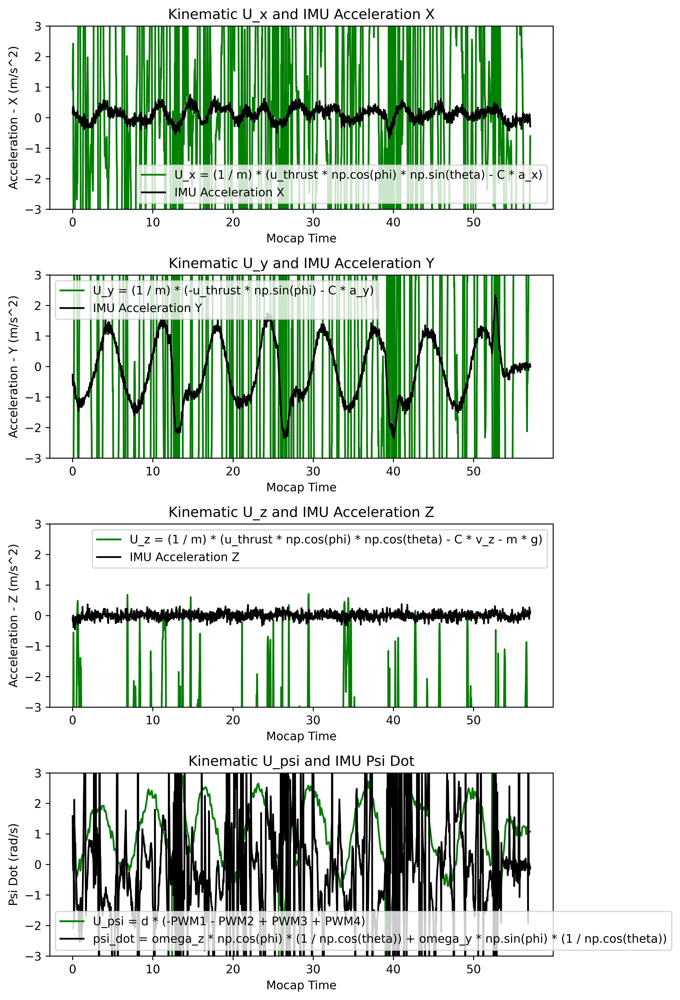

In [389]:
# compare u_x_kin, u_y_kin, u_z_kin with IMU_ACC_BL_X, IMU_ACC_BL_Y, IMU_ACC_BL_Z and u_psi_kin with psi_dot_kin
fig, ax = plt.subplots(4, 1, figsize=(8, 12), dpi=600)
# Plot X-axis
ax[0].plot(mocap_time_shifted, u_x_kin, label="U_x = (1 / m) * (u_thrust * np.cos(phi) * np.sin(theta) - C * a_x)", color='green')
ax[0].plot(mocap_time_shifted, IMU_ACC_BL_X, label="IMU Acceleration X", color='black')
ax[0].set_title('Kinematic U_x and IMU Acceleration X')
ax[0].set_xlabel('Mocap Time')
ax[0].set_ylabel('Acceleration - X (m/s^2)')
ax[0].set_ylim(-3, 3)
ax[0].legend()
# Plot Y-axis
ax[1].plot(mocap_time_shifted, u_y_kin, label="U_y = (1 / m) * (-u_thrust * np.sin(phi) - C * a_y)", color='green')
ax[1].plot(mocap_time_shifted, IMU_ACC_BL_Y, label="IMU Acceleration Y", color='black')
ax[1].set_title('Kinematic U_y and IMU Acceleration Y')
ax[1].set_xlabel('Mocap Time')
ax[1].set_ylabel('Acceleration - Y (m/s^2)')
ax[1].set_ylim(-3, 3)
ax[1].legend()
# Plot Z-axis
ax[2].plot(mocap_time_shifted, u_z_kin, label="U_z = (1 / m) * (u_thrust * np.cos(phi) * np.cos(theta) - C * v_z - m * g)", color='green')
ax[2].plot(mocap_time_shifted, IMU_ACC_BL_Z, label="IMU Acceleration Z", color='black')
ax[2].set_title('Kinematic U_z and IMU Acceleration Z')
ax[2].set_xlabel('Mocap Time')
ax[2].set_ylabel('Acceleration - Z (m/s^2)')
ax[2].set_ylim(-3, 3)
ax[2].legend()
# Plot Psi Dot
ax[3].plot(mocap_time_shifted, u_psi_kin, label="U_psi = d * (-PWM1 - PWM2 + PWM3 + PWM4)", color='green')
ax[3].plot(mocap_time_shifted, psi_dot_kin, label="psi_dot = omega_z * np.cos(phi) * (1 / np.cos(theta)) + omega_y * np.sin(phi) * (1 / np.cos(theta))", color='black')
ax[3].set_title('Kinematic U_psi and IMU Psi Dot')
ax[3].set_xlabel('Mocap Time')
ax[3].set_ylabel('Psi Dot (rad/s)')
ax[3].set_ylim(-3, 3)
ax[3].legend()
plt.tight_layout()
plt.show()

# MPC

In [276]:
X0_mpc = np.atleast_2d(np.vstack((X_TRUE[0], # X
                                 Y_TRUE[0], # Y
                                 Z_TRUE[0], # 1/Z = mu
                                 X_DOT_BL_TRUE[0], # X_DOT
                                 Y_DOT_BL_TRUE[0], # Y_DOT
                                 Z_DOT_BL_TRUE[0], # Z_DOT
                                 IMU_ROLL[0], # ROLL
                                 IMU_PITCH[0], # PITCH
                                 IMU_YAW[0], # YAW
                                 IMU_OMEGA_X[0], # OMEGA_X
                                 IMU_OMEGA_Y[0], # OMEGA_Y
                                 IMU_OMEGA_Z[0], # OMEGA_Z
                                 0, # wx
                                 0 # wy
                                 )))
print("Initial State X0_MPC:")
print(X0_mpc)
X0_sim = []
for i in range(len(X0_mpc)):
    X0_sim.append(X0_mpc[i][0])

# Check if the absolute values of the last two elements are both < 1e-12
if abs(X0_mpc[-1][0]) < 1e-12 and abs(X0_mpc[-2][0]) < 1e-12:
    print('hello')
    X0_sim[-2] = 1e-12
    X0_sim[-1] = 1e-12


X0_sim = np.array(X0_sim)
print("X0_sim", len(X0_sim), '\n', X0_sim)

Initial State X0_MPC:
[[-4.12850332e+00]
 [-2.20388308e-01]
 [ 1.91325736e+00]
 [ 7.42058557e-01]
 [ 2.71817812e-02]
 [ 1.25613238e-01]
 [ 1.66529064e+00]
 [ 4.45582894e+00]
 [ 7.04021452e+01]
 [ 1.70033788e-01]
 [-4.97714120e-01]
 [-3.22320711e-01]
 [ 0.00000000e+00]
 [ 0.00000000e+00]]
hello
X0_sim 14 
 [-4.12850332e+00 -2.20388308e-01  1.91325736e+00  7.42058557e-01
  2.71817812e-02  1.25613238e-01  1.66529064e+00  4.45582894e+00
  7.04021452e+01  1.70033788e-01 -4.97714120e-01 -3.22320711e-01
  1.00000000e-12  1.00000000e-12]


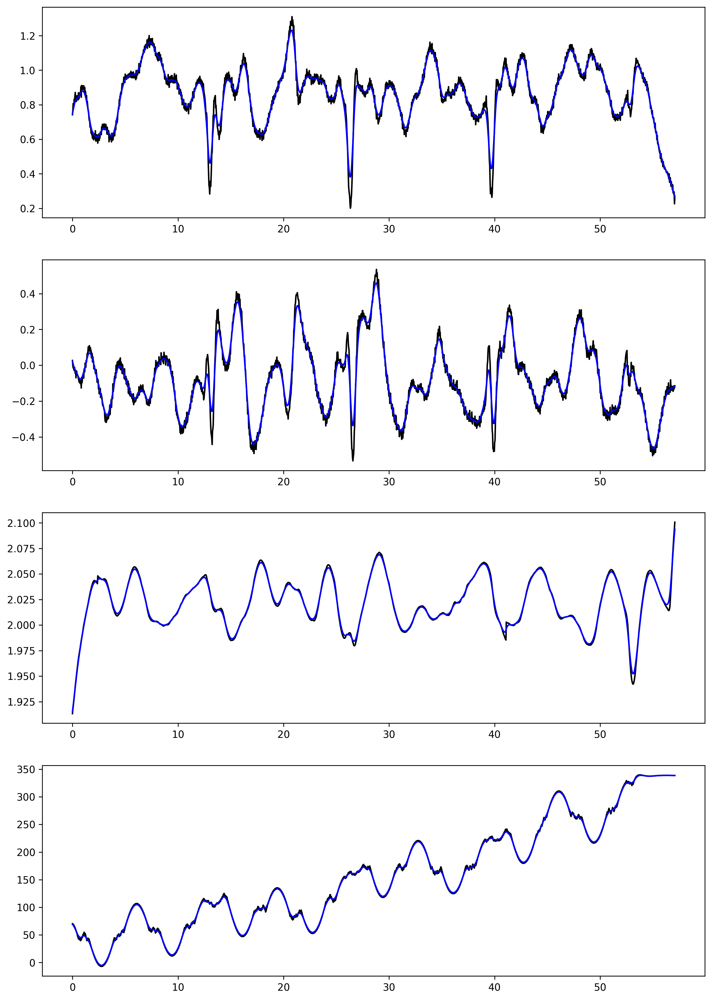

In [277]:
dt_filtter = TIME_BL[1] - TIME_BL[0]
X_DOT_BL_TRUE_MPC = low_pass_filter(X_DOT_BL_TRUE, dt_filtter, 1)
Y_DOT_BL_TRUE_MPC = low_pass_filter(Y_DOT_BL_TRUE, dt_filtter, 1)
Z_TRUE_MPC = low_pass_filter(Z_TRUE, dt_filtter, 1)
IMU_YAW_MPC = low_pass_filter(np.unwrap(IMU_YAW), dt_filtter, 1)

#take every nth element of the array
nth= 1
TIME_BL_MPC = np.array(TIME_BL[::nth])
dt_MPC = np.mean(np.diff(TIME_BL_MPC))
X_DOT_BL_TRUE_MPC = np.array(X_DOT_BL_TRUE_MPC[::nth])
Y_DOT_BL_TRUE_MPC = np.array(Y_DOT_BL_TRUE_MPC[::nth])
Z_TRUE_MPC = np.array(Z_TRUE_MPC[::nth])
IMU_YAW_MPC = np.array(IMU_YAW_MPC[::nth])

fig, ax = plt.subplots(4, 1, figsize=(3 * 4, 3 * 6), dpi=300)
# plot
ax[0].plot(TIME_BL, X_DOT_BL_TRUE, label='true', color='black')
ax[1].plot(TIME_BL, Y_DOT_BL_TRUE, label='true', color='black')
ax[2].plot(TIME_BL, Z_TRUE, label='true', color='black')
ax[3].plot(TIME_BL, np.unwrap(IMU_YAW), label='true', color='black')
ax[0].plot(TIME_BL_MPC, X_DOT_BL_TRUE_MPC, label='true', color='blue')
ax[1].plot(TIME_BL_MPC, Y_DOT_BL_TRUE_MPC, label='true', color='blue')
ax[2].plot(TIME_BL_MPC, Z_TRUE_MPC, label='true', color='blue')
ax[3].plot(TIME_BL_MPC, IMU_YAW_MPC, label='true', color='blue')
plt.show()

In [278]:
# Create simulator
simulator = DroneSimulator(dt=DT_BL*nth, mpc_horizon=50, r_u=1e-4, control_mode='velocity_body_level',params=PARAMS)
# Update the setpoints
simulator.update_setpoint(v_x=X_DOT_BL_TRUE_MPC, v_y=Y_DOT_BL_TRUE_MPC, psi=IMU_YAW_MPC, z=Z_TRUE_MPC, wx=np.zeros_like(Z_TRUE_MPC), wy=np.zeros_like(Z_TRUE_MPC))
# Run simulation
st = time.time()
# t_sim, x_sim, u_sim, y_sim = simulator.simulate(x0=X0_sim, u=U_real, mpc=False, return_full_output=True)
t_sim, x_sim, u_sim, y_sim = simulator.simulate(x0=X0_sim, mpc=True, return_full_output=True)
et = time.time()
print('elapsed time:', et-st)

in 2
Drone parameters: {'g': 9.81, 'm': 0.086, 'M': 2.529, 'Mm': 2.8729999999999998, 'L': 0.2032, 'R': 0.1778, 'I_x': 0.491, 'I_y': 0.387, 'I_z': 0.667, 'b': 1.34, 'd': 1.0, 'C': 0.1}


elapsed time: 155.2023572921753


In [279]:
# save the simulation results to a csv file
df_sim = pd.DataFrame({
    't_sim': t_sim})
for keys in x_sim.keys():
    df_sim['states_'+keys] = x_sim[keys]
for keys in u_sim.keys():
    df_sim['controls_'+keys] = u_sim[keys]
for keys in y_sim.keys():
    df_sim['outputs_'+keys] = y_sim[keys]
print(df_sim.head())
df_sim.to_csv(condition + "_" + motif +'_real2sim.csv', index=False)

   t_sim  states_x  states_y  states_z  states_v_x  states_v_y  states_v_z  \
0   0.00 -4.128503 -0.220388  1.913257    0.742059    0.027182    0.125613   
1   0.03 -4.131492 -0.198390  1.916981   -0.717848    0.165292    0.122640   
2   0.06 -4.134259 -0.176014  1.920591   -0.170721    0.715799    0.118007   
3   0.09 -4.129313 -0.171168  1.924055    0.504642   -0.017209    0.112926   
4   0.12 -4.139992 -0.184904  1.927373    0.783856    0.110286    0.108287   

   states_psi  states_wx  states_wy  ...  outputs_psi  outputs_wx  outputs_wy  \
0    1.665291   4.455829  70.402145  ...     1.665291    4.455829   70.402145   
1   55.341774   4.455829  70.402145  ...    55.341774    4.455829   70.402145   
2   68.990947   4.455829  70.402145  ...    68.990947    4.455829   70.402145   
3   68.017312   4.455829  70.402145  ...    68.017312    4.455829   70.402145   
4   65.940137   4.455829  70.402145  ...    65.940137    4.455829   70.402145   

   outputs_Ax  outputs_Ay  outputs_Az  outpu

# Observability

In [280]:
drone_model = DroneModel()
if FLAG == '1':
    z_function=drone_model.z_function
elif FLAG == '2' or FLAG == '3':
    z_function=drone_model.z_function2
elif FLAG == '4':
    z_function=drone_model.z_function4

In [281]:
# Set time-window
time_window = 8
# Construct O in sliding windows
st = time.time()
if FLAG == '1':
    z_state_names = ['x', 'y', 'z', 'g', 'beta', 'v_z', 'phi', 'theta', 'psi', 'omega_x', 'omega_y', 'omega_z', 'W', 'zeta']
elif FLAG == '2' or FLAG == '3':
    z_state_names = ['x', 'y', 'z', 'g', 'beta', 'v_z', 'psi', 'W', 'zeta']
elif FLAG == '4':
    z_state_names = ['x', 'y', 'z', 'g', 'beta', 'v_z', 'phi', 'theta', 'psi', 'W', 'zeta']
SEOM = SlidingEmpiricalObservabilityMatrix(simulator, t_sim, x_sim, u_sim,
                                           w=5, eps=1e-5,
                                           z_function=z_function,
                                           z_state_names=z_state_names)
et = time.time()
print('elapsed time:', et-st)

elapsed time: 336.0245032310486


In [282]:
O_sliding = SEOM.get_observability_matrix()
n_window = len(O_sliding)
o_sensors = ['psi', 'Ax', 'Ay', 'Az', 'rx', 'ry', 'Wax', 'Way']
o_states = None
window_size = 5
o_time_steps = np.arange(0, window_size, step=1)
O_sliding[0]

,,x,y,z,g,beta,v_z,psi,W,zeta
sensor,time_step,,,,,,,,,
x,0,1.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000
y,0,0.000000e+00,1.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000
z,0,0.000000e+00,0.000000e+00,1.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000
v_x,0,0.000000e+00,0.000000e+00,0.000000e+00,0.999330,-0.027182,0.000000e+00,0.000000e+00,0.000000,0.000000
v_y,0,0.000000e+00,0.000000e+00,0.000000e+00,0.036606,0.742059,0.000000e+00,0.000000e+00,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...
Az,4,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000
rx,4,1.360578e-08,1.045553e-08,-2.110108e-01,0.084934,0.380059,-2.532128e-02,-9.320961e-07,0.000000,0.000000
ry,4,2.092770e-09,8.028300e-10,-2.968862e-02,-0.511868,0.063074,-3.562631e-03,2.540673e-06,0.000000,0.000000


In [283]:
SFO = SlidingFisherObservability(SEOM.O_df_sliding, time=SEOM.t_sim, lam=1e-6, R=0.5**2,
                                states=z_state_names, sensors=o_sensors, time_steps=o_time_steps, w=window_size)

EV_aligned = SFO.get_minimum_error_variance()
EV_no_nan = EV_aligned.fillna(method='bfill').fillna(method='ffill')

In [284]:
np.mean(np.log10(EV_no_nan['W']))

-0.15724980294677976

In [285]:
def flip_scale(data, min_val=-2, max_val=6):
    """
    Flip values in `data` across the interval [min_val, max_val],
    then shift so that the new minimum is 0.

    In other words:
      1. Clip the input to [min_val, max_val].
      2. Flip by:  flipped = (min_val + max_val) - clipped.
      3. Shift up by subtracting min_val, so that the final range is [0, max_val - min_val].

    Parameters
    ----------
    data : array‐like
        Numeric array to transform.
    min_val : float
        Lower bound of the original range (default = -2).
    max_val : float
        Upper bound of the original range (default = 6).

    Returns
    -------
    np.ndarray
        Flipped + shifted array, spanning [0, max_val - min_val].
    """
    arr = np.clip(data, min_val, max_val)
    flipped = (min_val + max_val) - arr
    shifted = flipped - min_val
    return shifted

STATES = [
    'x', 'y', 'z',
    'g', 'beta', 'v_z',
    'psi',
    'W', 'zeta'
]

sensor = 'psi'  # or any other sensor you want to use

flipped   = {state: None for state in STATES}
neg_flipped = {state: None for state in STATES}
X1        = {state: None for state in STATES}
X2        = {state: None for state in STATES}
Y1        = {state: None for state in STATES}
Y2        = {state: None for state in STATES}
dist_map  = {state: None for state in STATES}
X_mesh    = {state: None for state in STATES}
Y_mesh    = {state: None for state in STATES}
C_map     = {state: None for state in STATES}

for state in STATES:
    # 1. Flip-and-shift the log10(data):
    raw = EV_no_nan[state]
    flipped[state] = flip_scale(np.log10(raw))
    neg_flipped[state] = -flipped[state]

    # 2. Time arrays:
    X1[state] = EV_no_nan['time']
    X2[state] = EV_no_nan['time']

    # 3. The two y-lines:
    Y1[state] = flipped[state] + 1.5
    Y2[state] = neg_flipped[state] - 1.5

    # 4. Distance map (value to color by):
    dist_map[state] = Y1[state] - 1.5

    # 5. Build the mesh (2xN for pcolormesh):
    X_mesh[state] = np.vstack([X1[state], X2[state]])
    Y_mesh[state] = np.vstack([Y1[state], Y2[state]])

    # 6. C_map shape (1, N-1):
    C_map[state] = np.array(dist_map[state][:-1])[np.newaxis, :]




In [286]:
if o_states is None:
        state_labels = STATES
else:
    state_labels = STATES

cnorm, cmap, log_ticks = ff.plot_heatmap_log_timeseries(EV_no_nan.iloc[:, 2:].values, log_ticks=(-2, 6),
                                                        data_labels=state_labels, y_label='min. error variance')

# measuerments

In [390]:

IMU_cluster = np.array(np.vstack((np.radians(df_all['IMU_YAW']), df_all['IMU_ACC_BL_X'], df_all['IMU_ACC_BL_Y'], df_all['IMU_ACC_BL_Z'])))
OF_cluster = np.array(np.vstack((df_all['OF_BL_X_Scaled'], df_all['OF_BL_Y_Scaled'])))
if wind_sensor == 'real':
    WIND_cluster = np.array(np.vstack((df_all['Wind_BL_X_Scaled'], df_all['Wind_BL_Y_Scaled'])))
    m = ['IMU_YAW', 'IMU_ACC_BL_X', 'IMU_ACC_BL_Y', 'IMU_ACC_BL_Z', 'OF_BL_X_Scaled', 'OF_BL_Y_Scaled', 'Wind_BL_X_Scaled', 'Wind_BL_Y_Scaled']
elif wind_sensor == 'simulated':
    WIND_cluster = np.array(np.vstack((df_all['X_DOT_BL_TRUE'], df_all['Y_DOT_BL_TRUE'])))
    m = ['IMU_YAW', 'IMU_ACC_BL_X', 'IMU_ACC_BL_Y', 'IMU_ACC_BL_Z', 'OF_BL_X_Scaled', 'OF_BL_Y_Scaled', 'X_DOT_BL_TRUE', 'Y_DOT_BL_TRUE']
#wind_sensor == 'simulated'
Y = np.vstack((IMU_cluster, OF_cluster, WIND_cluster))
U = np.array(np.vstack((df_all['IMU_ACC_BL_X'], df_all['IMU_ACC_BL_Y'], df_all['IMU_ACC_BL_Z'], df_all['IMU_OMEGA_Z'])))

In [391]:
# save Y and U to separate csv files
df_Y = pd.DataFrame(Y.T, columns=m)
df_Y.to_csv(condition + "_" + motif + '_Y.csv', index=False)
df_U = pd.DataFrame(U.T, columns=['IMU_ACC_BL_X', 'IMU_ACC_BL_Y', 'IMU_ACC_BL_Z', 'IMU_OMEGA_Z'])
df_U.to_csv(condition + "_" + motif + '_U.csv', index=False)

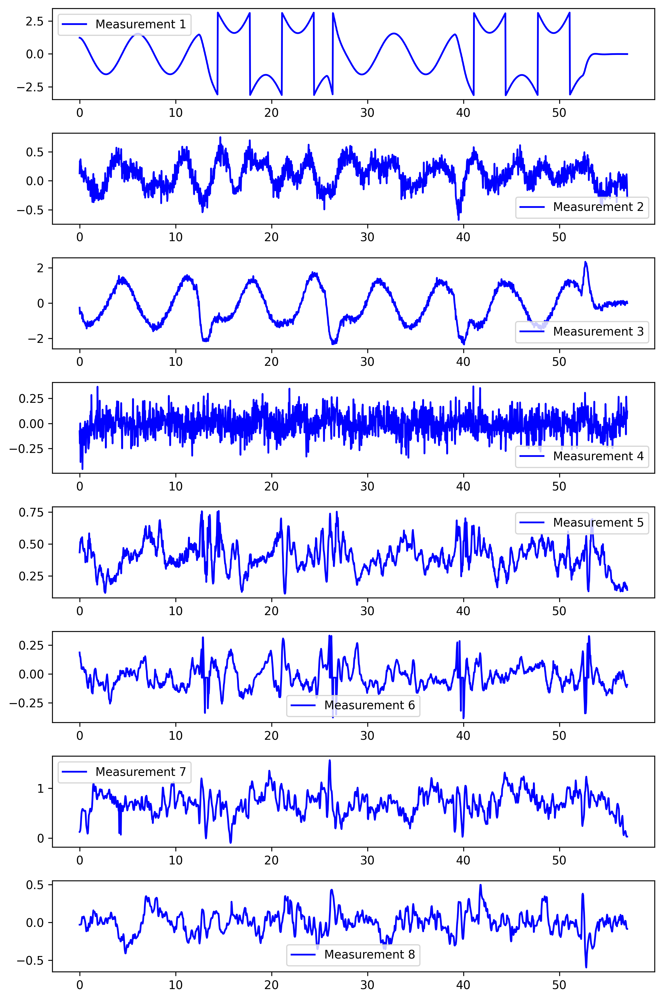

Text(0.5, 0, 'Mocap Time')

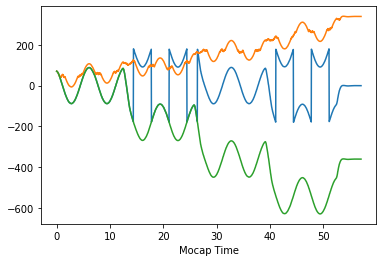

In [392]:
# plot all the measurements in a sub plot size of Y
fig, ax = plt.subplots(np.shape(Y)[0], 1, figsize=(8, 12), dpi=300)
for i in range(np.shape(Y)[0]):
    ax[i].plot(mocap_time_shifted, Y[i, :], label=f'Measurement {i+1}', color='blue')
    # ax[i].set_title(m[i])
    # ax[i].set_xlabel('Mocap Time')
    # ax[i].set_ylabel(m[i]+ ' Value')
    ax[i].legend()
plt.tight_layout()
plt.show()
plt.plot(mocap_time_shifted, df_all['IMU_YAW'], label='Mocap Yaw')
plt.plot(mocap_time_shifted, np.unwrap(df_all['IMU_YAW']), label='Mocap Yaw Unwrapped')
plt.plot(mocap_time_shifted, np.rad2deg(utility.unwrap_angle(np.radians(mocap_Yaw_unwrapped))), label='Mocap Yaw Unwrapped')
plt.xlabel('Mocap Time')

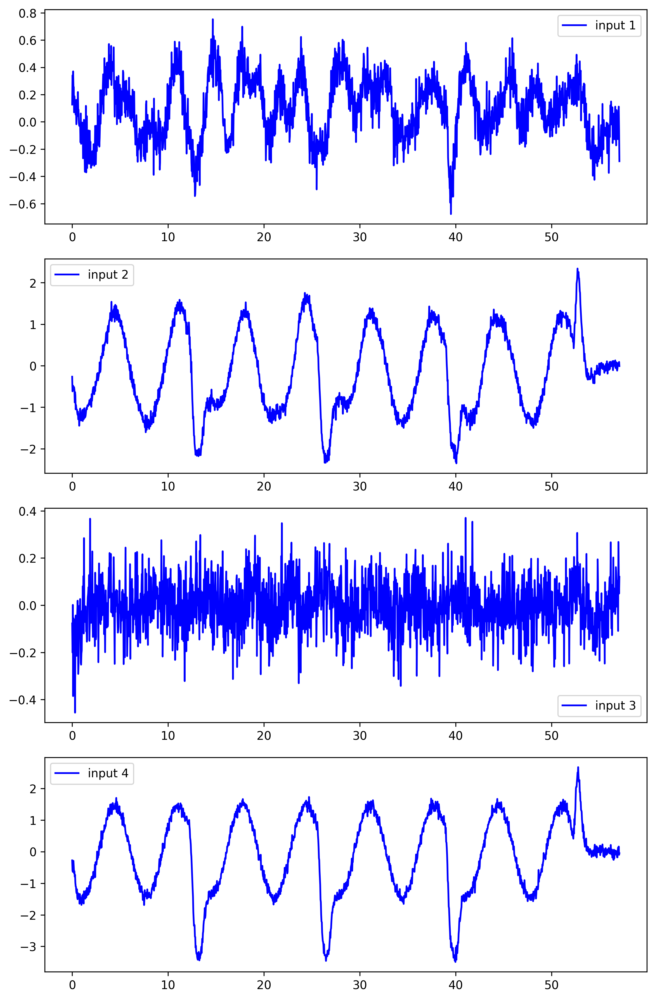

In [393]:
# plot all the measurements in a sub plot size of Y
fig, ax = plt.subplots(np.shape(U)[0], 1, figsize=(8, 12), dpi=300)
for i in range(np.shape(U)[0]):
    ax[i].plot(mocap_time_shifted, U[i, :], label=f'input {i+1}', color='blue')
    # ax[i].set_title(m[i])
    # ax[i].set_xlabel('Mocap Time')
    # ax[i].set_ylabel(m[i]+ ' Value')
    ax[i].legend()
plt.tight_layout()
plt.show()

# Xo

In [394]:
df_all_keys=['X_TRUE', 'X_DOT_G_TRUE', 'X_DOT_BL_TRUE', 'Y_TRUE', 'Y_DOT_G_TRUE',
       'Y_DOT_BL_TRUE', 'Z_TRUE', 'Z_DOT_G_TRUE', 'Z_DOT_BL_TRUE', 'Roll_TRUE',
       'Pitch_TRUE', 'Yaw_TRUE', 'OMEGA_X_TRUE', 'OMEGA_Y_TRUE',
       'OMEGA_Z_TRUE', 'IMU_ROLL', 'IMU_PITCH', 'IMU_YAW', 'IMU_ROLL_DOT',
       'IMU_PITCH_DOT', 'IMU_YAW_DOT', 'IMU_OMEGA_X', 'IMU_OMEGA_Y',
       'IMU_OMEGA_Z', 'IMU_ACC_BL_X', 'IMU_ACC_BL_Y', 'IMU_ACC_BL_Z',
       'Wind_BL_X', 'Wind_BL_Y', 'Wind_BL_X_Scaled', 'Wind_BL_Y_Scaled',
       'Wind_BL_A', 'Wind_BL_Gamma', 'OF_BL_X', 'OF_BL_Y', 'OF_BL_X_Scaled',
       'OF_BL_Y_Scaled', 'PWM_1', 'PWM_2', 'PWM_3', 'PWM_4']


In [395]:
# states are  x, y, z, v_x, v_y, v_z, psi, wx, wy 
offset = 2.0
X0 = np.atleast_2d(np.vstack((df_all['X_TRUE'][0] + offset, df_all['Y_TRUE'][0] + offset, df_all['Z_TRUE'][0] + offset,
                                   df_all['X_DOT_BL_TRUE'][0], df_all['Y_DOT_BL_TRUE'][0], df_all['Z_DOT_BL_TRUE'][0],
                                   np.radians(df_all['IMU_YAW'][0]) + offset,
                                   0.0 + offset, 0.0 + offset)))

# Q

In [396]:
Q = np.diag(np.array([
        1e-6, 1e-6, 1e-6,  # x, y, z
        1e-6, 1e-6, 1e-6,  # v_x, v_y, v_z
        1e-6,              # psi
        1e-6, 1e-6          # wx, wy
    ]))

# R

In [397]:
attitude_noise = 0.0001
of_noise = std_dev_of_avg
wind_noise = std_dev_wa_avg
R = np.power(np.diag(np.array([
                    attitude_noise,                           # psi
                    acceleration_noise, acceleration_noise, acceleration_noise,  # Ax, Ay, Az
                    of_noise, of_noise,                   # rx, ry
                    # wind_noise*10, wind_noise*10                # Wax, Way
                    .6**(.5), .6**(.5)                # Wax, Way
                ])), 2)
print(R)

[[1.00000000e-08 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 1.00000000e-02 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 1.00000000e-02 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 1.00000000e-02
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  9.56432327e-03 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 9.56432327e-03 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 6.00000000e-01 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 6.00000000e-01]]

In [295]:
# print the diagnal of the R matrix
print("R matrix diagonal:")
for i in range(len(R)):
    print(f"R[{i}][{i}] = {R[i][i]}")

R matrix diagonal:
R[0][0] = 1e-08
R[1][1] = 0.010000000000000002
R[2][2] = 0.010000000000000002
R[3][3] = 0.010000000000000002
R[4][4] = 0.009564323268089587
R[5][5] = 0.009564323268089587
R[6][6] = 0.6000000000000001
R[7][7] = 0.6000000000000001


# P

In [296]:
P0 = np.diag(np.array([offset, offset, offset,
                           offset, offset, offset,
                           offset,
                           offset, offset]) ** 2)

# Check size

In [297]:
if Y.shape[0] != R.shape[0]:
    raise ValueError('Y and R must have the same number of rows')
elif Y.shape[0] != R.shape[1]:
    raise ValueError('Y and R must have the same number of columns')
elif X0.shape[0] != P0.shape[0]:
    raise ValueError('X0 and P0 must have the same number of rows')
elif X0.shape[0] != P0.shape[1]:
    raise ValueError('X0 and P0 must have the same number of columns')
elif X0.shape[0] != Q.shape[0]:
    raise ValueError('X0 and Q must have the same number of rows')
elif X0.shape[0] != Q.shape[1]:
    raise ValueError('X0 and Q must have the same number of columns')
else:
    print('All dimensions are correct')

print('Y shape:', Y.shape)
print('U shape:', U.shape)
print('R shape:', R.shape)
print('X0 shape:', X0.shape)
print('P0 shape:', P0.shape)
print('Q shape:', Q.shape)

All dimensions are correct
Y shape: (8, 1713)
U shape: (4, 1713)
R shape: (8, 8)
X0 shape: (9, 1)
P0 shape: (9, 9)
Q shape: (9, 9)


# set up EKF functions

In [298]:
drone_model = DroneModel()
Y_SWEEP = 'IMU + WIND + OPTIC_FLOW'
def outer(func):
    def wrapper(*args, **kwargs):
        global DT_BL
        args = list(args) + [DT_BL]
        value = func(*args)
        return value
    return wrapper

f_c = outer(drone_model.f_c_car2)

def outer_h(func, input_sensor=None):
    if input_sensor is None:
        # If no explicit sensor is passed, use whatever Y_SWEEP currently is
        def wrapper(*args, **kwargs):
            global Y_SWEEP
            # Convert args → list, append Y_SWEEP, then call func
            full_args = list(args) + [Y_SWEEP]
            return func(*full_args)
    else:
        # If input_sensor is provided in the decorator, always use that
        def wrapper(*args, **kwargs):
            full_args = list(args) + [input_sensor]
            return func(*full_args)
    return wrapper

h_c = outer_h(drone_model.h_c_car2)

# run the EKF

In [299]:
xhat, P, s = EKF(Y, X0, f_c, h_c, Q, R, U, P0)

In [300]:
xhat_dict = {
            'x_hat': xhat[0, :],
            'y_hat': xhat[1, :],
            'z_hat': xhat[2, :],
            'v_x_hat': xhat[3, :],
            'v_y_hat': xhat[4, :],
            'v_z_hat': xhat[5, :],
            'psi_hat': xhat[6, :],
            'wx_hat': xhat[7, :],
            'wy_hat': xhat[8, :],
            'g_hat': (xhat[3, :]**2 + xhat[4, :]**2)**0.5,
            'beta_hat': np.arctan2(xhat[4, :], xhat[3, :]),
            'W_hat':(xhat[7, :]**2 + xhat[8, :]**2)**0.5,
            'zeta_hat': np.arctan2(xhat[8, :], xhat[7, :]),
        }

In [301]:
#save the xhat_dict to a csv file
df_xhat = pd.DataFrame(xhat_dict)
df_xhat.to_csv(condition + "_" + motif + '_xhat.csv', index=False)

In [302]:
# save 

In [303]:
# make sub plot 5 x 3 to plot all 13 states
fig, ax = plt.subplots(5, 3, figsize=(15, 15), dpi=600)
# Plot X-axis
ax[0, 0].plot(mocap_time_shifted, xhat_dict['x_hat'], label="X_hat", color='green')
ax[0, 0].plot(mocap_time_shifted, df_all['X_TRUE'], label="X_TRUE", color='black')
ax[0, 0].set_title('X_hat and X_TRUE')
ax[0, 0].set_xlabel('Mocap Time')
ax[0, 0].set_ylabel('X (m)')
ax[0, 0].legend()
# Plot Y-axis
ax[0, 1].plot(mocap_time_shifted, xhat_dict['y_hat'], label="Y_hat", color='green')
ax[0, 1].plot(mocap_time_shifted, df_all['Y_TRUE'], label="Y_TRUE", color='black')
ax[0, 1].set_title('Y_hat and Y_TRUE')
ax[0, 1].set_xlabel('Mocap Time')
ax[0, 1].set_ylabel('Y (m)')
ax[0, 1].legend()
# Plot Z-axis
ax[0, 2].plot(mocap_time_shifted, xhat_dict['z_hat'], label="Z_hat", color='green')
ax[0, 2].plot(mocap_time_shifted, df_all['Z_TRUE'], label="Z_TRUE", color='black')
ax[0, 2].set_title('Z_hat and Z_TRUE')
ax[0, 2].set_xlabel('Mocap Time')
ax[0, 2].set_ylabel('Z (m)')
ax[0, 2].legend()
# Plot Vx
ax[1, 0].plot(mocap_time_shifted, xhat_dict['v_x_hat'], label="Vx_hat", color='green')
ax[1, 0].plot(mocap_time_shifted, df_all['X_DOT_BL_TRUE'], label="X_DOT_BL_TRUE", color='black')
# ax[1, 0].plot(mocap_time_shifted, df_all['Wind_BL_X_Scaled'], label="Wind_BL_X_Scaled", color='blue')
ax[1, 0].set_title('Vx_hat and X_DOT_BL_TRUE')
ax[1, 0].set_xlabel('Mocap Time')
ax[1, 0].set_ylabel('Vx (m/s)')
ax[1, 0].set_ylim(-3, 3)
ax[1, 0].legend()
# Plot Vy
ax[1, 1].plot(mocap_time_shifted, xhat_dict['v_y_hat'], label="Vy_hat", color='green')
ax[1, 1].plot(mocap_time_shifted, df_all['Y_DOT_BL_TRUE'], label="Y_DOT_BL_TRUE", color='black')
# ax[1, 1].plot(mocap_time_shifted, df_all['Wind_BL_Y_Scaled'], label="Wind_BL_Y_Scaled", color='blue')
ax[1, 1].set_title('Vy_hat and Y_DOT_BL_TRUE')
ax[1, 1].set_xlabel('Mocap Time')
ax[1, 1].set_ylabel('Vy (m/s)')
ax[1, 1].set_ylim(-3, 3)
ax[1, 1].legend()
# Plot Vz
ax[1, 2].plot(mocap_time_shifted, xhat_dict['v_z_hat'], label="Vz_hat", color='green')
ax[1, 2].plot(mocap_time_shifted, df_all['Z_DOT_BL_TRUE'], label="Z_DOT_BL_TRUE", color='black')
ax[1, 2].set_title('Vz_hat and Z_DOT_BL_TRUE')
ax[1, 2].set_xlabel('Mocap Time')
ax[1, 2].set_ylabel('Vz (m/s)')
ax[1, 2].set_ylim(-3, 3)
ax[1, 2].legend()
# Plot Psi
ax[2, 0].plot(mocap_time_shifted, xhat_dict['psi_hat'], label="Psi_hat", color='green')
ax[2, 0].plot(mocap_time_shifted, np.radians(df_all['IMU_YAW']), label="IMU_YAW", color='black')
ax[2, 0].set_title('Psi_hat and IMU_YAW')
ax[2, 0].set_xlabel('Mocap Time')
ax[2, 0].set_ylabel('Psi (rad)')
ax[2, 0].legend()
# Plot Wx
ax[2, 1].plot(mocap_time_shifted, xhat_dict['wx_hat'], label="Wx_hat", color='green')
ax[2, 1].plot(mocap_time_shifted, np.zeros_like(mocap_time_shifted), label="IMU_OMEGA_X", color='black')
ax[2, 1].set_title('Wx_hat and Wind X')
ax[2, 1].set_xlabel('Mocap Time')
ax[2, 1].set_ylabel('Wx (rad/s)')
ax[2, 1].set_ylim(-3, 3)
ax[2, 1].legend()
# Plot Wy
ax[2, 2].plot(mocap_time_shifted, xhat_dict['wy_hat'], label="Wy_hat", color='green')
ax[2, 2].plot(mocap_time_shifted, np.zeros_like(mocap_time_shifted), label="IMU_OMEGA_Y", color='black')
ax[2, 2].set_title('Wy_hat and Wind Y')
ax[2, 2].set_xlabel('Mocap Time')
ax[2, 2].set_ylabel('Wy (rad/s)')
ax[2, 2].set_ylim(-3, 3)
ax[2, 2].legend()
# Plot Ground Speed
ax[3, 0].plot(mocap_time_shifted, xhat_dict['g_hat'], label="Ground Speed", color='green')
ax[3, 0].plot(mocap_time_shifted, np.sqrt(np.square(df_all['X_DOT_BL_TRUE']) + np.square(df_all['Y_DOT_BL_TRUE'])), label="Mocap Ground Speed", color='black')
ax[3, 0].set_title('Ground Speed from EKF and Mocap')
ax[3, 0].set_xlabel('Mocap Time')
ax[3, 0].set_ylabel('Ground Speed (m/s)')
ax[3, 0].set_ylim(-3, 3)
ax[3, 0].legend()
# Plot Beta
ax[3, 1].plot(mocap_time_shifted, xhat_dict['beta_hat'], label="Beta_hat", color='green')
ax[3, 1].plot(mocap_time_shifted, np.arctan2(df_all['Y_DOT_BL_TRUE'], df_all['X_DOT_BL_TRUE']), label="Mocap Beta", color='black')
ax[3, 1].set_title('Beta from EKF and Mocap')
ax[3, 1].set_xlabel('Mocap Time')
ax[3, 1].set_ylabel('Beta (rad)')
ax[3, 1].legend()
# Plot Wind Speed
ax[4, 0].plot(mocap_time_shifted, xhat_dict['W_hat'], label="Wind Speed", color='green')
ax[4, 0].plot(mocap_time_shifted, np.zeros_like(mocap_time_shifted), label="Mocap Wind Speed", color='black')
ax[4, 0].set_title('Wind Speed from EKF and Mocap')
ax[4, 0].set_xlabel('Mocap Time')
ax[4, 0].set_ylabel('Wind Speed (m/s)')
ax[4, 0].set_ylim(-3, 3)
ax[4, 0].legend()
# Plot Zeta
ax[4, 1].plot(mocap_time_shifted, xhat_dict['zeta_hat'], label="Zeta_hat", color='green')
ax[4, 1].plot(mocap_time_shifted, np.zeros_like(mocap_time_shifted), label="Mocap Zeta", color='black')
ax[4, 1].set_title('Zeta from EKF and Mocap')
ax[4, 1].set_xlabel('Mocap Time')
ax[4, 1].set_ylabel('Zeta (rad)')
ax[4, 1].legend()
# Hide the empty subplots
ax[3, 2].axis('off')
ax[4, 2].axis('off')
plt.tight_layout()
plt.show()

# figure first

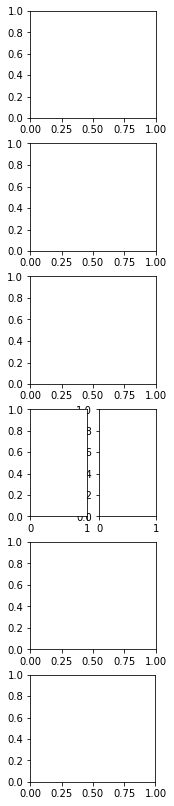

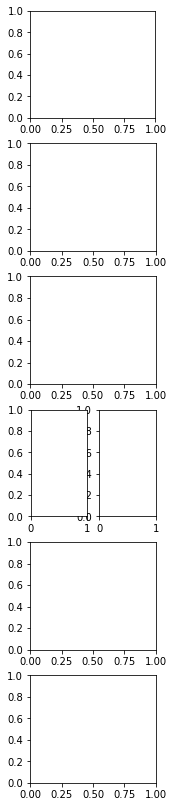

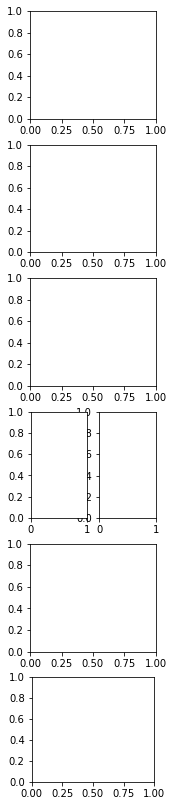

In [304]:
input_svg = '/home/austinlopez/Drone_AFRL/paper_figures/Fig_4_02.svg'
layout = fifi.svg_to_axes.FigureLayout(input_svg, autogenlayers=True, make_mplfigures=True, hide_layers=[])

In [305]:
# wind_sensor = 'real'
#wind_sensor == 'simulated'

In [306]:
Flag = False  # Set to True if you want to create a new figure
trajectory_percent = 50  # Set this to any value between 0 and 100

if Flag:
    fig = plt.figure(figsize=(2, 2))
    ax = fig.add_subplot(111)
else:
    if motif == 'p2p' and condition == 'flying':
        ax = layout.axes[('p2p', 'A')]
        print("Using p2p motif for flying condition")
    elif motif == 'p2p_con_yaw' and condition == 'flying':
        ax = layout.axes[('p2p_con_yaw', 'A')]
        print("Using p2p_con_yaw motif for flying condition")
    elif motif == 'sine' and condition == 'flying' and wind_sensor == 'real':
        ax = layout.axes[('sine', 'A')]
        print("Using sine motif for flying condition with real wind sensor")
    elif motif == 'sine' and condition == 'flying' and wind_sensor == 'simulated':
        ax = layout.axes[('sine_recon', 'A')]
        print("Using sine motif for flying condition with simulated wind sensor")
    elif motif == 'sine' and condition == 'walking' and wind_sensor == 'real':
        ax = layout.axes[('sine_walking', 'A')]
        print("Using sine motif for walking condition with real wind sensor")

# ax.set_title(f"Trajectory: {motif}")

# Calculate the number of points to display based on percentage
n_total = len(TIME_BL)
n_show = int(np.round(n_total * trajectory_percent / 100.0))

# Slice arrays for the displayed segment
X_TRUE_show = X_TRUE[:n_show]
Y_TRUE_show = Y_TRUE[:n_show]
IMU_YAW_show = np.radians(IMU_YAW[:n_show])
TIME_BL_show = np.array(TIME_BL[:n_show])

cmap = plt.get_cmap('viridis')
norm = mpl.colors.Normalize(vmin=TIME_BL_show[0], vmax=TIME_BL_show[-1])
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

# overlay triangles with color by time
tri = np.array([[.1,0],[-.05,-.05],[-.05,.05]]) * 2.0
for i in range(0, n_show, 10):
    R = np.array([[np.cos(IMU_YAW_show[i]), -np.sin(IMU_YAW_show[i])],
                  [np.sin(IMU_YAW_show[i]),  np.cos(IMU_YAW_show[i])]])
    tri_r = tri @ R.T
    color = cmap(norm(TIME_BL_show[i]))
    ax.fill(X_TRUE_show[i]+tri_r[:,0],
            Y_TRUE_show[i]+tri_r[:,1],
            color=color, alpha=0.8, edgecolor=None)

# Plot the trajectory line up to n_show
ax.plot(X_TRUE_show, Y_TRUE_show, color='black', linewidth=0.5)

fifi.mpl_functions.adjust_spines(ax, [], yticks=[-3, 0, 3], xticks=[-6, -4, -2, 0, 2, 4, 6],
                                      tick_length=3, linewidth=1, spine_locations={'left': 5, 'bottom': 5})
fifi.mpl_functions.set_fontsize(ax, 6)

ax.set_xlim([-6, 6.5])
ax.set_ylim([-3, 3.5])
ax.set_yticklabels([-3, 0, 3])
ax.set_xticklabels([-6, -4, -2, 0, 2, 4, 6])

if Flag:
    plt.show()
    fig.savefig(f'{motif}_.pdf', dpi=300)

Using sine motif for flying condition with real wind sensor


In [307]:
df_all.keys()

Index(['X_TRUE', 'X_DOT_G_TRUE', 'X_DOT_BL_TRUE', 'Y_TRUE', 'Y_DOT_G_TRUE',
       'Y_DOT_BL_TRUE', 'Z_TRUE', 'Z_DOT_G_TRUE', 'Z_DOT_BL_TRUE', 'Roll_TRUE',
       'Pitch_TRUE', 'Yaw_TRUE', 'OMEGA_X_TRUE', 'OMEGA_Y_TRUE',
       'OMEGA_Z_TRUE', 'IMU_ROLL', 'IMU_PITCH', 'IMU_YAW', 'IMU_OMEGA_X',
       'IMU_OMEGA_Y', 'IMU_OMEGA_Z', 'IMU_ACC_BL_X', 'IMU_ACC_BL_Y',
       'IMU_ACC_BL_Z', 'Wind_BL_X', 'Wind_BL_Y', 'Wind_BL_X_Scaled',
       'Wind_BL_Y_Scaled', 'Wind_BL_A', 'Wind_BL_Gamma', 'OF_BL_X', 'OF_BL_Y',
       'OF_BL_X_Scaled', 'OF_BL_Y_Scaled', 'PWM_1', 'PWM_2', 'PWM_3', 'PWM_4',
       'TIME_BL'],
      dtype='object')

In [308]:
Flag = False
trajectory_percent = 50  # Set this to any value between 0 and 100

if Flag:
    fig = plt.figure(figsize=(2, 2))
    ax = fig.add_subplot(111)
else:
    if motif == 'p2p' and condition == 'flying':
        ax = layout.axes[('p2p', 'B')]
        print("Using p2p motif for flying condition")
    elif motif == 'p2p_con_yaw' and condition == 'flying':
        ax = layout.axes[('p2p_con_yaw', 'B')]
        print("Using p2p_con_yaw motif for flying condition")
    elif motif == 'sine' and condition == 'flying' and wind_sensor == 'real':
        ax = layout.axes[('sine', 'B')]
        print("Using sine motif for flying condition with real wind sensor")
    elif motif == 'sine' and condition == 'flying' and wind_sensor == 'simulated':
        ax = layout.axes[('sine_recon', 'B')]
        print("Using sine motif for flying condition with simulated wind sensor")
    elif motif == 'sine' and condition == 'walking' and wind_sensor == 'real':
        ax = layout.axes[('sine_walking', 'B')]
        print("Using sine motif for walking condition with real wind sensor")

if wind_sensor == 'real':
    WAX = df_all['Wind_BL_X_Scaled']
    VX = df_all['X_DOT_BL_TRUE']
elif wind_sensor == 'simulated':
    WAX = df_all['X_DOT_BL_TRUE']
    VX = df_all['X_DOT_BL_TRUE']

ax.plot(TIME_BL, VX, label='VX', color='black', linewidth=0.5)
ax.plot(TIME_BL, WAX, label='WAX', color='tab:blue', linewidth=0.5)

fifi.mpl_functions.adjust_spines(ax, ['left', 'bottom'], yticks=[-2, -1, 0, 1, 2], xticks=[0, 10, 20, 30],
                                      tick_length=3, linewidth=1, spine_locations={'left': 5, 'bottom': 5})
fifi.mpl_functions.set_fontsize(ax, 6)

ax.set_xlim([0, 30])
ax.set_ylim([-2, 2])
ax.set_yticklabels([-2, -1, 0, 1, 2])
ax.set_xticklabels([0, 10, 20, 30])
ax.set_xlabel('Time [s]')
ax.set_ylabel(r'$V_{x}$, $W_{a,x}$ [$\frac{m}{s}$]')

if Flag:
    plt.show()
    fig.savefig(f'{motif}_.pdf', dpi=300)

Using sine motif for flying condition with real wind sensor


In [309]:
Flag = False
trajectory_percent = 50  # Set this to any value between 0 and 100

if Flag:
    fig = plt.figure(figsize=(2, 2))
    ax = fig.add_subplot(111)
else:
    if motif == 'p2p' and condition == 'flying':
        ax = layout.axes[('p2p', 'B2')]
        print("Using p2p motif for flying condition")
    elif motif == 'p2p_con_yaw' and condition == 'flying':
        ax = layout.axes[('p2p_con_yaw', 'B2')]
        print("Using p2p_con_yaw motif for flying condition")
    elif motif == 'sine' and condition == 'flying' and wind_sensor == 'real':
        ax = layout.axes[('sine', 'B2')]
        print("Using sine motif for flying condition with real wind sensor")
    elif motif == 'sine' and condition == 'flying' and wind_sensor == 'simulated':
        ax = layout.axes[('sine_recon', 'B2')]
        print("Using sine motif for flying condition with simulated wind sensor")
    elif motif == 'sine' and condition == 'walking' and wind_sensor == 'real':
        ax = layout.axes[('sine_walking', 'B2')]
        print("Using sine motif for walking condition with real wind sensor")

if wind_sensor == 'real':
    WAY = df_all['Wind_BL_Y_Scaled']
    VY = df_all['Y_DOT_BL_TRUE']
elif wind_sensor == 'simulated':
    WAY = df_all['X_DOT_BL_TRUE']
    VY = df_all['Y_DOT_BL_TRUE']

ax.plot(TIME_BL, VY, label='VY', color='black', linewidth=0.5)
ax.plot(TIME_BL, WAY, label='WAY', color='tab:orange', linewidth=0.5)

fifi.mpl_functions.adjust_spines(ax, ['left', 'bottom'], yticks=[-2, -1, 0, 1, 2], xticks=[0, 10, 20, 30],
                                      tick_length=3, linewidth=1, spine_locations={'left': 5, 'bottom': 5})
fifi.mpl_functions.set_fontsize(ax, 6)

ax.set_xlim([0, 30])
ax.set_ylim([-2, 2])
ax.set_yticklabels([-2, -1, 0, 1, 2])
ax.set_xticklabels([0, 10, 20, 30])
ax.set_xlabel('Time [s]')
ax.set_ylabel(r'$V_{y}$, $W_{a,y}$ [$\frac{m}{s}$]')

if Flag:
    plt.show()
    fig.savefig(f'{motif}_.pdf', dpi=300)

Using sine motif for flying condition with real wind sensor


In [310]:
EV_no_nan.keys()

Index(['time', 'time_initial', 'x', 'y', 'z', 'g', 'beta', 'v_z', 'psi', 'W',
       'zeta'],
      dtype='object')

In [311]:
# print(EV_no_nan.head())
# import seaborn as sns

# # Example: replace this with your actual data
# data_ev = {}
# for state in STATES:
#     data_ev[state] = np.log10(EV_no_nan[state])

# # Set up subplots
# num_states = len(STATES)
# cols = 3  # You can change this for a different layout
# rows = int(np.ceil(num_states / cols))

# fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3 * rows), sharex=True)

# for i, (state, data) in enumerate(data_ev.items()):
#     row = i // cols
#     col = i % cols
#     ax = axes[row, col] if rows > 1 else axes[col]  # Handle 1-row case
#     sns.kdeplot(data, bw_adjust=0.5, fill=True, clip=(-2, 6), ax=ax)
#     ax.set_title(state)
#     ax.set_xlim(-3, 7)
#     ax.grid(True)
#     ax.set_ylim(0, 5)

# # Remove empty plots if any
# for j in range(i + 1, rows * cols):
#     fig.delaxes(axes.flatten()[j])

# fig.suptitle('Distribution of log$_{10}$(Error Variance) by State', fontsize=14)
# plt.tight_layout(rect=[0, 0, 1, 0.96])
# plt.show()

In [312]:
# fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3 * rows), sharey=True)

# for i, state in enumerate(STATES):
#     row = i // cols
#     col = i % cols
#     ax = axes[row, col] if rows > 1 else axes[col]

#     # Create violin plot
#     parts = sns.violinplot(y=np.log10(EV_no_nan[state]), ax=ax, cut=0, inner=None, color='red')

#     # Update the outline color
#     for pc in ax.collections:
#         pc.set_edgecolor('black')   # change to desired outline color
#         pc.set_linewidth(1.0)

#     ax.set_title(state)
#     ax.set_ylim(-2, 6)
#     ax.set_xlabel('')
#     ax.set_ylabel('log$_{10}$(EV)')
#     ax.grid(True)

# # Remove empty subplots
# for j in range(i + 1, rows * cols):
#     fig.delaxes(axes.flatten()[j])

# fig.suptitle('Error Variance Distribution by State (Violin Plots)', fontsize=14)
# plt.tight_layout(rect=[0, 0, 1, 0.96])
# plt.show()


In [313]:
from sklearn.metrics import mean_squared_error
Flag = False
trajectory_percent = 50  # Set this to any value between 0 and 100

if Flag:
    fig = plt.figure(figsize=(2, 2))
    ax = fig.add_subplot(111)
else:
    if motif == 'p2p' and condition == 'flying':
        ax = layout.axes[('p2p', 'C')]
        print("Using p2p motif for flying condition")
    elif motif == 'p2p_con_yaw' and condition == 'flying':
        ax = layout.axes[('p2p_con_yaw', 'C')]
        print("Using p2p_con_yaw motif for flying condition")
    elif motif == 'sine' and condition == 'flying' and wind_sensor == 'real':
        ax = layout.axes[('sine', 'C')]
        print("Using sine motif for flying condition with real wind sensor")
    elif motif == 'sine' and condition == 'flying' and wind_sensor == 'simulated':
        ax = layout.axes[('sine_recon', 'C')]
        print("Using sine motif for flying condition with simulated wind sensor")
    elif motif == 'sine' and condition == 'walking' and wind_sensor == 'real':
        ax = layout.axes[('sine_walking', 'C')]
        print("Using sine motif for walking condition with real wind sensor")

# x_labels = ['wind_x', 'EV(W)']
# x_labels = [r'$W_{a,x} \rightarrow V_{x}$']
x_labels = [r'$W_{a,x} \rightarrow V_{x}$', r'$W_{a,y} \rightarrow V_{y}$']

# Calculate RMSEs
rmse_x = np.sqrt(mean_squared_error(df_all['X_DOT_BL_TRUE'], df_all['Wind_BL_X_Scaled']))
rmse_y = np.sqrt(mean_squared_error(df_all['Y_DOT_BL_TRUE'], df_all['Wind_BL_Y_Scaled']))

if wind_sensor == 'simulated':
    bar_values = [0.0, 0.0]
else:
    bar_values = [rmse_x, rmse_y]

# Set bar positions for each bar (not grouped)
x = np.arange(len(bar_values))
width = 0.5

bars = ax.bar(x, bar_values, width, bottom=-0.2, color=['tab:blue', 'tab:orange'])

# Set ticks under each bar
ax.set_xticks(x)
ax.set_xticklabels(x_labels)

ax.set_ylabel(r'RMSE $ [\frac{m}{s}]$')
ax.set_ylim(-.2, .4)
ax.tick_params(axis='y')

# Remove perimeter lines and adjust spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
fifi.mpl_functions.adjust_spines(ax, ['left', 'bottom'], yticks=[-.2, 0, .2, .4], xticks=[],
                                      tick_length=3, linewidth=1, spine_locations={'left': 5, 'bottom': 5})

fifi.mpl_functions.set_fontsize(ax, 6)
ax.set_xticks(x)
ax.set_xticklabels(x_labels)

# Color the tick labels
tick_colors = ['tab:blue', 'tab:orange']
for ticklabel, color in zip(ax.get_xticklabels(), tick_colors):
    ticklabel.set_color(color)

ax.set_yticks([-.2, 0, .2, .4])
ax.set_yticklabels(['', '0', '.2', '.4'])

# Optional: Add legend manually if you want
# ax.legend(['RMSE X', 'RMSE Y'])

if Flag:
    plt.show()
    fig.savefig(f'{motif}_bar.pdf', dpi=300)

Using sine motif for flying condition with real wind sensor


In [314]:
import seaborn as sns
Flag = False  # Set to True if you want to create a new figure
trajectory_percent = 50  # Set this to any value between 0 and 100

if Flag:
    fig = plt.figure(figsize=(2, 2))
    ax = fig.add_subplot(111)
else:
    if motif == 'p2p' and condition == 'flying':
        ax = layout.axes[('p2p', 'C2')]
        print("Using p2p motif for flying condition")
    elif motif == 'p2p_con_yaw' and condition == 'flying':
        ax = layout.axes[('p2p_con_yaw', 'C2')]
        print("Using p2p_con_yaw motif for flying condition")
    elif motif == 'sine' and condition == 'flying' and wind_sensor == 'real':
        ax = layout.axes[('sine', 'C2')]
        print("Using sine motif for flying condition with real wind sensor")
    elif motif == 'sine' and condition == 'flying' and wind_sensor == 'simulated':
        ax = layout.axes[('sine_recon', 'C2')]
        print("Using sine motif for flying condition with simulated wind sensor")
    elif motif == 'sine' and condition == 'walking' and wind_sensor == 'real':
        ax = layout.axes[('sine_walking', 'C2')]
        print("Using sine motif for walking condition with real wind sensor")

state = 'W'  # change this to the state you want to plot
state2 = 'g'
bar_values = [0, 1]
x_labels = [r'$V_{g}$', r'$W$']
x = np.arange(len(bar_values))
# Prepare data for side-by-side violin plots
df_violin = pd.DataFrame({
    'value': np.concatenate([np.log10(EV_no_nan[state2]), np.log10(EV_no_nan[state])]),
    'state': [state2]*len(EV_no_nan[state2]) + [state]*len(EV_no_nan[state])
})

sns.violinplot(
    x='state',
    y='value',
    data=df_violin,
    ax=ax,
    cut=0,
    inner=None,
    palette=['red', 'red']
)

# Adjust spines and outline as before
fifi.mpl_functions.adjust_spines(ax, ['right', 'bottom'], yticks=[-2, 0, 2, 4, 6], xticks=[],
                                      tick_length=3, linewidth=1, spine_locations={'right': 5, 'bottom': 5})
for pc in ax.collections:
    pc.set_edgecolor('black')
    pc.set_linewidth(1.0)

# Set y labels, x ticks, etc.
ax.set_yticks([-2, 0, 2, 4, 6])
ax.set_yticklabels([-2, 0, 2, 4, 6])
ax.set_xlabel('')
ax.yaxis.set_label_position("right")
ax.set_ylabel('log$_{10}$(min. error variance)')
ax.set_ylim(-2, 6)
ax.spines['bottom'].set_visible(True)
ax.spines['bottom'].set_color('black')
ax.spines['bottom'].set_linewidth(1.0)

ax.set_xticks(x)
ax.set_xticklabels(x_labels)

# Color the tick labels
tick_colors = ['red', 'red']
for ticklabel, color in zip(ax.get_xticklabels(), tick_colors):
    ticklabel.set_color(color)

if Flag:
    plt.show()
    fig.savefig(f'{motif}_bar.pdf', dpi=300)

Using sine motif for flying condition with real wind sensor


In [315]:
Flag = False
trajectory_percent = 50  # Set this to any value between 0 and 100

if Flag:
    fig = plt.figure(figsize=(2, 2))
    ax = fig.add_subplot(111)
else:
    if motif == 'p2p' and condition == 'flying':
        ax = layout.axes[('p2p', 'D')]
        print("Using p2p motif for flying condition")
    elif motif == 'p2p_con_yaw' and condition == 'flying':
        ax = layout.axes[('p2p_con_yaw', 'D')]
        print("Using p2p_con_yaw motif for flying condition")
    elif motif == 'sine' and condition == 'flying' and wind_sensor == 'real':
        ax = layout.axes[('sine', 'D')]
        print("Using sine motif for flying condition with real wind sensor")
    elif motif == 'sine' and condition == 'flying' and wind_sensor == 'simulated':
        ax = layout.axes[('sine_recon', 'D')]
        print("Using sine motif for flying condition with simulated wind sensor")
    elif motif == 'sine' and condition == 'walking' and wind_sensor == 'real':
        ax = layout.axes[('sine_walking', 'D')]
        print("Using sine motif for walking condition with real wind sensor")

if wind_sensor == 'real':
    WAX = df_all['Wind_BL_X_Scaled']
    VX = df_all['X_DOT_BL_TRUE']
elif wind_sensor == 'simulated':
    WAX = df_all['X_DOT_BL_TRUE']
    VX = df_all['X_DOT_BL_TRUE']

ax.plot(TIME_BL, np.zeros_like(VX), label='VX', color='black', linewidth=3.5)
ax.plot(TIME_BL, xhat_dict['W_hat'], label='WAX', color='red', linewidth=0.5)

fifi.mpl_functions.adjust_spines(ax, ['left', 'bottom'], yticks=[0, 1, 2, 3, 4], xticks=[0, 10, 20, 30],
                                      tick_length=3, linewidth=1, spine_locations={'left': 5, 'bottom': 5})
fifi.mpl_functions.set_fontsize(ax, 6)

ax.set_xlim([0, 30])
ax.set_ylim([0, 4])
ax.set_yticklabels([0, 1, 2, 3, 4])
ax.set_xticklabels([0, 10, 20, 30])
ax.set_xlabel('Time [s]')
ax.set_ylabel(r'$W$ [$\frac{m}{s}$]')

if Flag:
    plt.show()
    fig.savefig(f'{motif}_wind_estimation.pdf', dpi=300)

Using sine motif for flying condition with real wind sensor


In [316]:
Flag = False
trajectory_percent = 50  # Set this to any value between 0 and 100

if Flag:
    fig = plt.figure(figsize=(2, 2))
    ax = fig.add_subplot(111)
else:
    if motif == 'p2p' and condition == 'flying':
        ax = layout.axes[('p2p', 'D2')]
        print("Using p2p motif for flying condition")
    elif motif == 'p2p_con_yaw' and condition == 'flying':
        ax = layout.axes[('p2p_con_yaw', 'D2')]
        print("Using p2p_con_yaw motif for flying condition")
    elif motif == 'sine' and condition == 'flying' and wind_sensor == 'real':
        ax = layout.axes[('sine', 'D2')]
        print("Using sine motif for flying condition with real wind sensor")
    elif motif == 'sine' and condition == 'flying' and wind_sensor == 'simulated':
        ax = layout.axes[('sine_recon', 'D2')]
        print("Using sine motif for flying condition with simulated wind sensor")
    elif motif == 'sine' and condition == 'walking' and wind_sensor == 'real':
        ax = layout.axes[('sine_walking', 'D2')]
        print("Using sine motif for walking condition with real wind sensor")

if wind_sensor == 'real':
    WAY = df_all['Wind_BL_Y_Scaled']
    VY = df_all['Y_DOT_BL_TRUE']
elif wind_sensor == 'simulated':
    WAY = df_all['Y_DOT_BL_TRUE']
    VY = df_all['Y_DOT_BL_TRUE']

ax.plot(TIME_BL, np.sqrt(np.square(df_all['X_DOT_BL_TRUE']) + np.square(df_all['Y_DOT_BL_TRUE'])), label='VY', color='black', linewidth=0.5)
ax.plot(TIME_BL, xhat_dict['g_hat'], label='g', color='red', linewidth=0.5)

fifi.mpl_functions.adjust_spines(ax, ['left', 'bottom'], yticks=[0, 1, 2, 3, 4], xticks=[0, 10, 20, 30],
                                      tick_length=3, linewidth=1, spine_locations={'left': 5, 'bottom': 5})
fifi.mpl_functions.set_fontsize(ax, 6)

ax.set_xlim([0, 30])
ax.set_ylim([0, 4])
ax.set_yticklabels([0, 1, 2, 3, 4])
ax.set_xticklabels([0, 10, 20, 30])
ax.set_xlabel('Time [s]')
ax.set_ylabel(r'$V_{g}$ [$\frac{m}{s}$]')

if Flag:
    plt.show()
    fig.savefig(f'{motif}_wind_estimation.pdf', dpi=300)

Using sine motif for flying condition with real wind sensor


Appending sine figure to layer


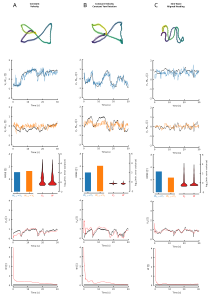

In [317]:
if motif == 'p2p':
    print("Appending p2p figure to layer")
    layout.append_figure_to_layer(layout.figures['p2p'], 'p2p', cleartarget=True)
elif motif == 'p2p_con_yaw':
    print("Appending p2p_con_yaw figure to layer")
    layout.append_figure_to_layer(layout.figures['p2p_con_yaw'], 'p2p_con_yaw', cleartarget=True)
elif motif == 'sine' and condition == 'flying' and wind_sensor == 'real':
    print("Appending sine figure to layer")
    layout.append_figure_to_layer(layout.figures['sine'], 'sine', cleartarget=True)
elif motif == 'sine' and condition == 'flying' and wind_sensor == 'simulated':
    print("Appending sine_recon figure to layer")
    layout.append_figure_to_layer(layout.figures['sine_recon'], 'sine_recon', cleartarget=True)
elif motif == 'sine' and condition == 'walking':
    print("Appending sine_walking figure to layer")
    layout.append_figure_to_layer(layout.figures['sine_walking'], 'sine_walking', cleartarget=True)
layout.write_svg(input_svg)
display(SVG(input_svg))

-0.41640747832103314
-0.15724980294677976


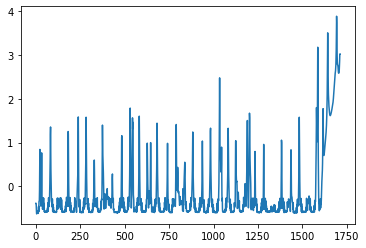

In [318]:
plt.plot(np.log10(EV_no_nan['W']))

print(np.median(np.log10(EV_no_nan['W'])))
print(np.mean(np.log10(EV_no_nan['W'])))